# 🇧🇩 Bangla Clickbait Detection — Research Notebook (Kaggle Edition)
## BanglaBait Dataset | Title-Based Binary Classification
### Models: XLM-R-base/large · BanglaBERT · BanglaBERT-large · Bangla-BERT-Base · mDeBERTa-v3 · MuRIL · IndicBERTv2 · TigerLLM-1B (QLoRA) · TF-IDF baselines

**Task:** Binary classification — `title` → `label` (0 = Non-Clickbait, 1 = Clickbait)
**Dataset:** [BanglaBait](https://www.kaggle.com/datasets/motaharmahtab/banglabait-bangla-clickbait-dataset) (train.csv / test.csv) — no external data used
**Input field:** `title` only · **Target field:** `label` only
**Compute:** Designed for Kaggle **GPU T4 x2** (mixed precision + `DataParallel` across both GPUs)

---
### 📝 What changed vs. the original notebook
This is a corrected and substantially upgraded version of the original Colab notebook. Key fixes/upgrades:

| # | Issue in original notebook | Fix / Upgrade in this version |
|---|---|---|
| 1 | Used `google.colab.drive` — doesn't exist on Kaggle | Auto-detects dataset under `/kaggle/input/...`, writes to `/kaggle/working/...` |
| 2 | `pip install torch ...` — overwrites Kaggle's pre-built CUDA-matched PyTorch | Removed `torch` from the install line; only adds the extra libraries |
| 3 | `csebuetnlp/banglabert-large` (hyphen) → 404 on HuggingFace Hub | Corrected to the real public repo `csebuetnlp/banglabert_large` (underscore) |
| 4 | `TigerResearch/tigerbot-7b-chat-v3` is a **Chinese** LLM, not a Bangla model at all | Replaced with the real Bangla LLM `md-nishat-008/TigerLLM-1B-it` (ACL 2025 paper) |
| 5 | Classification-report heatmap faked the Non-Clickbait row as `1 - Clickbait metric` (mathematically wrong) | Both classes' precision/recall/F1 are now computed and plotted correctly |
| 6 | Single GPU only, no mixed precision | `DataParallel` across both T4s + AMP (`torch.cuda.amp`) for ~2-3x faster training |
| 7 | No ROC/PR curves, no significance testing, no classical baseline | Added ROC-AUC & PR-AUC per model, ROC/PR comparison plots, McNemar's test, TF-IDF+LogReg/SVM baselines |
| 8 | `TrainingArguments(evaluation_strategy=...)` — removed in newer `transformers` | Version-safe argument builder that works on old and new `transformers` |
| 9 | No use of BanglaBERT's recommended text normalization | Optional `csebuetnlp/normalizer` preprocessing for BanglaBERT/BanglaBERT-large |
| 10 | — | Added `sagorsarker/bangla-bert-base` for a broader model comparison |
| 11 | Bangla text in figures drawn with plain Matplotlib text → empty boxes / broken conjuncts (স্ত, ক্ষ, র্ক …) even with a Bangla font loaded | New **Section 1B**: Kalpurush / Noto Sans Bengali font setup + PIL **RAQM (HarfBuzz) shaped-text rendering** (`draw_bengali_text`, `set_bengali_yticklabels`) used by every Bangla figure |
| 12 | `TfidfVectorizer` default token pattern and LIME's default `\W+` split cut Bangla words at vowel signs / virama | Bangla-aware `token_pattern` (Section 8, 24.2) and whitespace/punctuation `split_expression` for LIME (21.3, 22.1) |
| 13 | TigerLLM: prompt truncated at 96 tokens, `<eos>` masked (pad = eos), only 6 new tokens generated → label often cut off / never learned | Dynamic padding, `max_len=256`, explicit `<eos>`, answer-only loss, 12 new tokens |
| 14 | Exported/demo BanglaBERT skipped the csebuetnlp normalizer used in training; Section 19 "Val" curves were computed on the test set | `needs_bn_norm` saved in `model_card.json` and applied in the demo; curves now use the real validation split |

---


## ⚙️ Section 0 — Environment Setup (Kaggle)

In [1]:
# ── 0.1  Install / upgrade the extra libraries we need ────────────
# IMPORTANT: we deliberately do NOT touch `torch` here. Kaggle's GPU images
# ship a PyTorch build that is already matched to the driver / CUDA version
# on the machine. Reinstalling `torch` from PyPI (as the original notebook
# did) can silently replace it with a build that no longer sees the GPU.
!pip install -q -U "transformers>=4.44,<5" "accelerate>=0.33" "peft>=0.12" \
                   "bitsandbytes>=0.43" "datasets" "evaluate" "sentencepiece" \
                   "protobuf"

# Optional: BanglaBERT's official text normalizer (improves BanglaBERT /
# BanglaBERT-large accuracy slightly). Not fatal if it fails to install.
!pip install -q "git+https://github.com/csebuetnlp/normalizer" || \
    echo "⚠️  Could not install csebuetnlp/normalizer — will skip normalization."

# Interpretability / visualisation extras (only installs what is missing; harmless if present)
!pip install -q lime shap wordcloud psutil || echo "⚠️  Could not install lime/shap/wordcloud — related sections will skip."

print("✅ Package installation step complete")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 580.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 45.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires g

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"   # avoid tokenizer fork warnings/deadlocks

import torch
print(f"torch version   : {torch.__version__}")
print(f"CUDA available   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    n_gpu = torch.cuda.device_count()
    print(f"GPU count        : {n_gpu}")
    for i in range(n_gpu):
        props = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {props.name}  ({props.total_memory/1e9:.1f} GB)")
else:
    print("⚠️  No GPU detected. On Kaggle: Settings (right sidebar) → Accelerator → GPU T4 x2")


torch version   : 2.11.0+cu128
CUDA available   : True
GPU count        : 2
  GPU 0: Tesla T4  (15.6 GB)
  GPU 1: Tesla T4  (15.6 GB)


## 📦 Section 1 — Imports & Global Configuration

In [3]:
import os, gc, json, glob, time, warnings, inspect
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    f1_score, classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
)
from sklearn.model_selection import train_test_split
from scipy.stats import chi2
warnings.filterwarnings("ignore")

# ── Reproducibility ──────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = False   # False = allow cuDNN autotune (faster on T4)
torch.backends.cudnn.benchmark     = True    # speeds up training when input sizes are fixed

# ── Device & multi-GPU setup ─────────────────────────────────────
DEVICE  = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
N_GPUS  = torch.cuda.device_count() if torch.cuda.is_available() else 0
USE_AMP = torch.cuda.is_available()   # mixed precision only makes sense on GPU

print(f"Device            : {DEVICE}")
print(f"GPUs visible       : {N_GPUS}")
print(f"Mixed precision    : {USE_AMP}")
if N_GPUS > 1:
    print(f"→ Encoder models will be wrapped in nn.DataParallel across all {N_GPUS} GPUs.")
elif N_GPUS == 1:
    print("→ Single GPU detected — training will still use AMP mixed precision.")

# ── Column names ──────────────────────────────────────────────────
TEXT_COL  = "title"
LABEL_COL = "label"
LABEL_NAMES = ["Non-Clickbait", "Clickbait"]

# ── Default hyperparameters (overridden per model below) ─────────
# Batch sizes below assume a T4 x2 setup: DataParallel splits each batch
# roughly in half across the 2 GPUs, so e.g. batch_size=32 → 16 per GPU.
DEFAULT_CFG = dict(
    max_len      = 128,
    batch_size   = 32,
    epochs       = 5,
    lr           = 2e-5,
    weight_decay = 0.01,
    warmup_ratio = 0.1,
    grad_clip    = 1.0,
    patience     = 3,          # early stopping patience
    val_size     = 0.10,       # 10 % of train → validation
)

print("✅ Imports and config done")


Device            : cuda:0
GPUs visible       : 2
Mixed precision    : True
→ Encoder models will be wrapped in nn.DataParallel across all 2 GPUs.
✅ Imports and config done


## 🔤 Section 1B — Bangla Font & Complex-Script Text Rendering

Matplotlib's default font has no Bangla glyphs (you get empty boxes), and even with a Bangla font Matplotlib has **no
complex-script shaping**, so conjuncts (স্ত, ক্ষ, র্ক …), reph and vowel-sign order come out wrong. This cell therefore:

1. finds a Bangla font — a custom path, a cached copy, a font attached under `/kaggle/input`, then downloads **Kalpurush**
   (3 mirrors) and finally **Noto Sans Bengali** (3 mirrors); each file is validated to really contain Bengali glyphs;
2. shapes text with **PIL's RAQM (HarfBuzz) layout engine** (`draw_bengali_text`) and places it on the figure as an image —
   Bangla runs use the Bangla font, English/digits use DejaVu Sans, so mixed labels never show boxes;
3. provides `set_bengali_yticklabels`, `reserve_left_margin`, `place_axes_row` and `wrap_bengali_text` for bar-chart labels,
   margins and word-boundary-safe wrapping, plus `apply_bengali_rc()` to restore font fallbacks after `sns.set_theme()`.

Turn **Internet ON** in the Kaggle sidebar the first time (font download), or attach a Kalpurush/Noto `.ttf` as a dataset.


Downloaded Kalpurush (mirror 1) -> /kaggle/working/fonts/bengali_font.ttf
RAQM complex-script shaping available: True


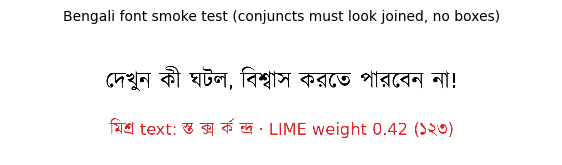

✅ Bengali rendering helpers ready: draw_bengali_text, set_bengali_yticklabels, wrap_bengali_text, reserve_left_margin, place_axes_row, apply_bengali_rc


In [4]:
# ── 1B.1  Bengali font + complex-script (conjunct) text rendering ──────────
# Matplotlib draws text glyph-by-glyph with NO complex-script shaping, so Bengali
# comes out as boxes (missing font) or as broken conjuncts / mis-ordered vowel
# signs (font present, shaping absent).  The fix used in the captioning notebook:
#   1. find / download a real Bengali font (Kalpurush → Noto Sans Bengali),
#   2. let PIL's RAQM layout engine (HarfBuzz) shape the text into an RGBA image,
#   3. place that image on the figure as an AnnotationBbox.
# Every Bengali label in this notebook goes through draw_bengali_text() /
# set_bengali_yticklabels() below; English text keeps using normal Matplotlib text.
import os, re, glob, textwrap, subprocess, sys, urllib.request
from functools import lru_cache

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import ft2font
from matplotlib.colors import to_hex
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image, ImageDraw, ImageFont, features as _pil_features

WORKING_ROOT   = globals().get("WORKING_ROOT", "/kaggle/working")
FONT_DIR       = f"{WORKING_ROOT}/fonts"
FONT_CACHE_PATH = f"{FONT_DIR}/bengali_font.ttf"
os.makedirs(FONT_DIR, exist_ok=True)

# Set this to a .ttf path (e.g. an attached Kaggle dataset) to force a specific font.
CUSTOM_BENGALI_FONT = globals().get("CUSTOM_BENGALI_FONT", None)

FALLBACK_FONT_URLS = [
    ("Kalpurush (mirror 1)", "https://raw.githubusercontent.com/hmoazzem/bangla-fonts/master/kalpurush.ttf"),
    ("Kalpurush (mirror 2)", "https://raw.githubusercontent.com/MohammadTaseenKhan/Fonts-Hub/main/kalpurush.ttf"),
    ("Kalpurush (mirror 3)", "https://raw.githubusercontent.com/shiftenterdev/bangla-font/master/kalpurush.ttf"),
    ("Noto Sans Bengali",    "https://raw.githubusercontent.com/notofonts/noto-fonts/main/hinted/ttf/NotoSansBengali/NotoSansBengali-Regular.ttf"),
    ("Noto Sans Bengali (mirror 2)", "https://raw.githubusercontent.com/notofonts/notofonts.github.io/main/fonts/NotoSansBengali/hinted/ttf/NotoSansBengali-Regular.ttf"),
    ("Noto Sans Bengali (mirror 3)", "https://raw.githubusercontent.com/openmaptiles/fonts/master/noto-sans/NotoSansBengali-Regular.ttf"),
]

_FONT_MAGIC = (b"\x00\x01\x00\x00", b"OTTO", b"true", b"ttcf")

def _font_has_bengali(path):
    """True if `path` is a loadable font file that really contains Bengali glyphs
    (guards against a 404 HTML page saved as .ttf, or a font without Bengali)."""
    try:
        if os.path.getsize(path) < 10_000:
            return False
        with open(path, "rb") as fh:
            if fh.read(4) not in _FONT_MAGIC:
                return False
        ImageFont.truetype(path, 20)
        f = ft2font.FT2Font(path)
        # ক (U+0995), virama ্ (U+09CD), vowel sign ি (U+09BF)
        return all(f.get_char_index(cp) > 0 for cp in (0x0995, 0x09CD, 0x09BF))
    except Exception:
        return False

def _local_font_candidates():
    pats = ["/kaggle/input/**/*alpurush*.ttf", "/kaggle/input/**/*engali*.ttf",
            "/kaggle/input/**/*angla*.ttf",    "/kaggle/input/**/*olaimanLipi*.ttf"]
    found = []
    for p in pats:
        found += glob.glob(p, recursive=True)
    try:
        for p in fm.findSystemFonts(fontext="ttf"):
            if re.search(r"kalpurush|bengali|bangla|solaimanlipi|siyamrupali|nikosh|lohit.?beng", os.path.basename(p), re.I):
                found.append(p)
    except Exception:
        pass
    return found

def setup_bengali_font():
    if CUSTOM_BENGALI_FONT and _font_has_bengali(CUSTOM_BENGALI_FONT):
        print(f"Using custom Bengali font: {CUSTOM_BENGALI_FONT}")
        return CUSTOM_BENGALI_FONT
    if os.path.exists(FONT_CACHE_PATH) and _font_has_bengali(FONT_CACHE_PATH):
        print(f"Using previously-cached Bengali font: {FONT_CACHE_PATH}")
        return FONT_CACHE_PATH
    for p in _local_font_candidates():
        if _font_has_bengali(p):
            print(f"Using Bengali font found on disk: {p}")
            return p
    for label, url in FALLBACK_FONT_URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=30) as r, open(FONT_CACHE_PATH, "wb") as out:
                out.write(r.read())
            if _font_has_bengali(FONT_CACHE_PATH):
                print(f"Downloaded {label} -> {FONT_CACHE_PATH}")
                return FONT_CACHE_PATH
            os.remove(FONT_CACHE_PATH)
            print(f"  {label}: file was not a valid Bengali font, trying next source...")
        except Exception as e:
            print(f"  {label} failed ({type(e).__name__}), trying next source...")
    print("\n*** WARNING: could not obtain a Bengali font. Bengali labels will fall back to "
          "plain Matplotlib text and WILL show as empty boxes. ***\n"
          "    → Turn Internet ON in the Kaggle sidebar, or attach a Kalpurush/Noto Sans Bengali "
          ".ttf as a dataset (or set CUSTOM_BENGALI_FONT) and re-run this cell.")
    return None

BENGALI_FONT_PATH = setup_bengali_font()

# ── RAQM (HarfBuzz) availability: required for correct conjunct shaping ─────
RAQM_OK = bool(_pil_features.check("raqm"))
if not RAQM_OK:
    print("⚠️  PIL was built without libraqm — Bengali conjuncts would be drawn unshaped. "
          "Trying to install it (needs Internet); if this message repeats after a kernel "
          "restart, run:  !apt-get install -y libraqm0 libfribidi0 libharfbuzz0b")
    try:
        subprocess.run(["apt-get", "install", "-y", "-qq", "libraqm0", "libfribidi0", "libharfbuzz0b"],
                       check=False, capture_output=True, timeout=180)
    except Exception:
        pass
    print("   Restart the kernel (Run → Restart) and run again so Pillow can pick it up.")
print(f"RAQM complex-script shaping available: {RAQM_OK}")

# Matplotlib-side registration (also gives a glyph-level fallback for stray Bengali text)
BENGALI_FONT_NAME = None
BANGLA_FONT_PROP  = None          # kept for backward compatibility with older cells
if BENGALI_FONT_PATH:
    fm.fontManager.addfont(BENGALI_FONT_PATH)
    BANGLA_FONT_PROP  = fm.FontProperties(fname=BENGALI_FONT_PATH)
    BENGALI_FONT_NAME = BANGLA_FONT_PROP.get_name()

def apply_bengali_rc():
    """Keep DejaVu Sans for English text (Noto Sans Bengali has no Latin glyphs) and add the
    Bengali font as a fallback.  Call again after sns.set_theme(), which resets rcParams."""
    plt.rcParams["font.family"] = "sans-serif"
    sans = ["DejaVu Sans"] + ([BENGALI_FONT_NAME] if BENGALI_FONT_NAME else [])
    plt.rcParams["font.sans-serif"] = sans + [f for f in plt.rcParams["font.sans-serif"] if f not in sans]
    plt.rcParams["axes.unicode_minus"] = False

apply_bengali_rc()

# ── Shaped text renderer ────────────────────────────────────────────────────
_LATIN_REG  = os.path.join(matplotlib.get_data_path(), "fonts", "ttf", "DejaVuSans.ttf")
_LATIN_BOLD = os.path.join(matplotlib.get_data_path(), "fonts", "ttf", "DejaVuSans-Bold.ttf")
_BN_CH  = "\u0980-\u09FF\u0964\u0965\u200c\u200d"
_BN_RUN = re.compile(rf"([{_BN_CH}]+(?:[ \u00a0]+[{_BN_CH}]+)*)")   # Bengali words (+ inner spaces)

@lru_cache(maxsize=64)
def _pil_font(path, px):
    return ImageFont.truetype(path, px)

def wrap_bengali_text(text, width=28):
    """Word-boundary-aware wrapping (never splits a Bengali word / conjunct)."""
    if not text:
        return ""
    lines = textwrap.wrap(str(text), width=width, break_long_words=False, break_on_hyphens=False)
    return "\n".join(lines) if lines else str(text)

def render_text_image(text, fontsize=12, color="black", ha="center", bold=False,
                      scale=3, pad=6, line_gap=0.25, latin_scale=0.9):
    """Render (possibly multi-line, mixed Bengali/English) text to an RGBA PIL image.
    Bengali runs use the Bengali font through RAQM; everything else uses DejaVu Sans, so
    digits / Latin / brackets never turn into boxes even when only Noto Sans Bengali is available."""
    px = max(int(round(fontsize * scale)), 6)
    fill = to_hex(color)
    lat_path = _LATIN_BOLD if bold else _LATIN_REG
    kw_bn = {"language": "bn"} if RAQM_OK else {}
    engine = {"layout_engine": ImageFont.Layout.RAQM} if RAQM_OK else {}

    def _font(path, size=px):
        try:
            return ImageFont.truetype(path, size, **engine)
        except Exception:
            return _pil_font(path, size)

    lines = []
    for raw in str(text).split("\n"):
        parts, x = [], 0.0
        for seg in [s for s in _BN_RUN.split(raw) if s != ""]:
            is_bn = bool(_BN_RUN.fullmatch(seg))
            use_bn = is_bn and bool(BENGALI_FONT_PATH)
            # DejaVu looks larger than Bengali fonts at the same size → shrink Latin runs slightly
            f = _font(BENGALI_FONT_PATH) if use_bn else _font(lat_path, max(int(px * latin_scale), 6))
            kw = kw_bn if use_bn else {}
            adv = f.getlength(seg, **kw)
            l, t, r, b = f.getbbox(seg, anchor="ls", **kw)       # relative to the baseline origin
            parts.append((seg, f, kw, x, l, t, r, b))
            x += adv
        if not parts:
            parts = [(" ", _font(lat_path, max(int(px * latin_scale), 6)), {}, 0.0, 0, -px, 1, px // 4)]
            x = px * 0.3
        left   = min(p[3] + p[4] for p in parts)
        right  = max(max(p[3] + p[6] for p in parts), x)
        top    = min(p[5] for p in parts)
        bottom = max(p[7] for p in parts)
        lines.append(dict(parts=parts, left=left, right=right, top=top, bottom=bottom, adv=x))

    g_top    = min(l["top"] for l in lines)
    g_bottom = max(l["bottom"] for l in lines)
    line_h   = (g_bottom - g_top) + line_gap * px
    width_px = max(l["right"] - min(0, l["left"]) for l in lines)
    W = int(np.ceil(width_px + 2 * pad))
    H = int(np.ceil(line_h * len(lines) - line_gap * px + 2 * pad))
    img = Image.new("RGBA", (max(W, 1), max(H, 1)), (255, 255, 255, 0))
    draw = ImageDraw.Draw(img)
    for k, ln in enumerate(lines):
        base_y = pad - g_top + k * line_h
        ln_w = ln["right"] - min(0, ln["left"])
        off = {"left": 0.0, "center": (width_px - ln_w) / 2, "right": width_px - ln_w}.get(ha, 0.0)
        x0 = pad - min(0, ln["left"]) + off
        for seg, f, kw, x, *_ in ln["parts"]:
            draw.text((x0 + x, base_y), seg, fill=fill, font=f, anchor="ls", **kw)
    return img

_ALIGN = {"center": 0.5, "left": 0.0, "right": 1.0, "top": 1.0, "bottom": 0.0, "baseline": 0.0}

def draw_bengali_text(ax, x, y, text, fontsize=12, color="black", ha="center", va="center",
                      transform=None, bold=False, offset_pts=None, zorder=6):
    """Place correctly-shaped Bengali text (optionally mixed with English) on a Matplotlib axis.
    (x, y) are in `transform` coordinates (default: data).  Falls back to ax.text() only if
    no Bengali font could be loaded at all."""
    if text is None or str(text) == "":
        return None
    tr = transform if transform is not None else ax.transData
    if not BENGALI_FONT_PATH:
        return ax.text(x, y, str(text), fontsize=fontsize, color=color, ha=ha, va=va, transform=tr,
                       fontweight="bold" if bold else "normal")
    scale = 3
    img = render_text_image(text, fontsize=fontsize, color=color, ha=ha, bold=bold, scale=scale)
    box = OffsetImage(np.asarray(img), zoom=1 / scale)
    kwargs = dict(xycoords=tr, frameon=False, annotation_clip=False,
                  box_alignment=(_ALIGN.get(ha, 0.5), _ALIGN.get(va, 0.5)), pad=0.0)
    if offset_pts is not None:
        kwargs.update(xybox=offset_pts, boxcoords="offset points")
    ab = AnnotationBbox(box, (x, y), **kwargs)
    ab.set_zorder(zorder)
    ax.add_artist(ab)
    ab.bn_size_pt = (img.width / scale, img.height / scale)       # (width, height) in points
    return ab

def set_bengali_yticklabels(ax, labels, fontsize=12, color="black", gap_pts=5):
    """Replace y tick labels by shaped Bengali text. Returns the widest label width in points
    (use it with reserve_left_margin / place_axes_row so nothing is cut off or overlaps)."""
    labels = [str(l) for l in labels]
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels([])                       # avoid Matplotlib's unshaped / boxed glyphs
    widest = 0.0
    for i, lab in enumerate(labels):
        ab = draw_bengali_text(ax, 0.0, i, lab, fontsize=fontsize, color=color, ha="right", va="center",
                               transform=ax.get_yaxis_transform(), offset_pts=(-gap_pts, 0))
        if ab is not None and hasattr(ab, "bn_size_pt"):
            widest = max(widest, ab.bn_size_pt[0])
        elif ab is not None:                     # fallback plain-text path
            widest = max(widest, len(lab) * fontsize * 0.6)
    return widest

def reserve_left_margin(fig, width_pt, extra_pt=18, right=0.97, **adjust):
    """Make room on the left of a (single-column) figure for `width_pt` of Bengali tick labels."""
    left = min(0.7, (width_pt + extra_pt) / (fig.get_figwidth() * 72))
    fig.subplots_adjust(left=left, right=right, **adjust)

def place_axes_row(fig, axes, widths_pt, left_pad_pt=18, right=0.98, gap_pt=22):
    """Side-by-side axes whose y tick labels are Bengali: widths_pt[i] is the label width of axes i.
    Call AFTER fig.subplots_adjust(top=..., bottom=...)."""
    W = fig.get_figwidth() * 72
    gaps = [left_pad_pt + widths_pt[0]] + [gap_pt + w for w in widths_pt[1:]]
    avail = right * W - sum(gaps)
    aw = avail / len(axes)
    x = 0.0
    for ax, g in zip(axes, gaps):
        x += g
        pos = ax.get_position()
        ax.set_position([x / W, pos.y0, aw / W, pos.height])
        x += aw

# ── Smoke test ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 1.6))
draw_bengali_text(ax, 0.5, 0.62, "দেখুন কী ঘটল, বিশ্বাস করতে পারবেন না!", fontsize=17,
                  ha="center", va="center", transform=ax.transAxes)
draw_bengali_text(ax, 0.5, 0.22, "মিশ্র text: স্ত ক্স র্ক ন্দ্র · LIME weight 0.42 (১২৩)", fontsize=13,
                  ha="center", va="center", transform=ax.transAxes, color="#DC2626")
ax.axis("off")
plt.title("Bengali font smoke test (conjuncts must look joined, no boxes)", fontsize=10, pad=8)
os.makedirs(f"{WORKING_ROOT}/banglabait_results", exist_ok=True)
plt.savefig(f"{WORKING_ROOT}/banglabait_results/fig_00_font_smoke_test.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("✅ Bengali rendering helpers ready: draw_bengali_text, set_bengali_yticklabels, "
      "wrap_bengali_text, reserve_left_margin, place_axes_row, apply_bengali_rc")


## 📂 Section 2 — Dataset Loading (Kaggle input auto-detection)

In [5]:
# ── Auto-detect train.csv / test.csv anywhere under /kaggle/input ────────
# Kaggle sometimes nests dataset files one folder deeper than expected, so
# instead of hardcoding a path we search for them and prefer paths that
# mention "banglabait" (the dataset slug) if there is more than one match.

def _find_csv(filename):
    all_matches = glob.glob(f"/kaggle/input/**/{filename}", recursive=True)
    if not all_matches:
        return None, all_matches
    preferred = [p for p in all_matches if "banglabait" in p.lower()]
    chosen = preferred[0] if preferred else all_matches[0]
    return chosen, all_matches

BN_TRAIN_PATH, _train_matches = _find_csv("train.csv")
BN_TEST_PATH,  _test_matches  = _find_csv("test.csv")

SAVE_DIR = "/kaggle/working/banglabait_results"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Searched /kaggle/input for train.csv / test.csv ...")
print(f"  train.csv matches found : {_train_matches}")
print(f"  test.csv  matches found : {_test_matches}")

if BN_TRAIN_PATH is None or BN_TEST_PATH is None:
    raise FileNotFoundError(
        "Could not locate train.csv / test.csv under /kaggle/input.\n"
        "→ Make sure you added the dataset via 'Add Input' → search "
        "'BanglaBait: Bangla Clickbait Dataset' (motaharmahtab) and it "
        "appears in the Data pane on the right.\n"
        "If it uses different filenames, set BN_TRAIN_PATH / BN_TEST_PATH manually below."
    )

print(f"\n✅ Using train file : {BN_TRAIN_PATH}")
print(f"✅ Using test  file : {BN_TEST_PATH}")
print(f"✅ Output directory : {SAVE_DIR}")


Searched /kaggle/input for train.csv / test.csv ...
  train.csv matches found : ['/kaggle/input/datasets/motaharmahtab/banglabait-bangla-clickbait-dataset/clickbait/train.csv']
  test.csv  matches found : ['/kaggle/input/datasets/motaharmahtab/banglabait-bangla-clickbait-dataset/clickbait/test.csv']

✅ Using train file : /kaggle/input/datasets/motaharmahtab/banglabait-bangla-clickbait-dataset/clickbait/train.csv
✅ Using test  file : /kaggle/input/datasets/motaharmahtab/banglabait-bangla-clickbait-dataset/clickbait/test.csv
✅ Output directory : /kaggle/working/banglabait_results


In [6]:
def load_banglabait(train_path, test_path, text_col=TEXT_COL, label_col=LABEL_COL):
    """Load BanglaBait CSVs; return cleaned DataFrames."""
    train_df = pd.read_csv(train_path)
    test_df  = pd.read_csv(test_path)

    # ── Validate expected columns exist (helpful error if schema differs) ──
    for name, df in [("train", train_df), ("test", test_df)]:
        missing = [c for c in (text_col, label_col) if c not in df.columns]
        if missing:
            raise KeyError(
                f"Column(s) {missing} not found in {name}.csv. "
                f"Available columns: {df.columns.tolist()}\n"
                f"→ Update TEXT_COL / LABEL_COL in Section 1 to match your file."
            )

    # Keep only required columns
    train_df = train_df[[text_col, label_col]].dropna().reset_index(drop=True)
    test_df  = test_df[[text_col, label_col]].dropna().reset_index(drop=True)

    # Ensure labels are integers
    train_df[label_col] = train_df[label_col].astype(int)
    test_df[label_col]  = test_df[label_col].astype(int)

    # Ensure texts are strings, de-duplicated
    train_df[text_col] = train_df[text_col].astype(str).str.strip()
    test_df[text_col]  = test_df[text_col].astype(str).str.strip()
    train_df = train_df.drop_duplicates(subset=[text_col]).reset_index(drop=True)
    test_df  = test_df.drop_duplicates(subset=[text_col]).reset_index(drop=True)

    return train_df, test_df


bn_train_full, bn_test = load_banglabait(BN_TRAIN_PATH, BN_TEST_PATH)

print("=" * 50)
print(f"BanglaBait Dataset Loaded")
print("=" * 50)
print(f"Train rows  : {len(bn_train_full):,}")
print(f"Test  rows  : {len(bn_test):,}")
print(f"Columns     : {bn_train_full.columns.tolist()}")
print(f"\nTrain label distribution:")
for lbl, cnt in bn_train_full[LABEL_COL].value_counts().items():
    pct = cnt / len(bn_train_full) * 100
    print(f"  {LABEL_NAMES[lbl]} ({lbl}) : {cnt:,}  ({pct:.1f}%)")
print(f"\nTest label distribution:")
for lbl, cnt in bn_test[LABEL_COL].value_counts().items():
    pct = cnt / len(bn_test) * 100
    print(f"  {LABEL_NAMES[lbl]} ({lbl}) : {cnt:,}  ({pct:.1f}%)")
print(f"\nSample titles:")
print(bn_train_full[[TEXT_COL, LABEL_COL]].head(5).to_string(index=False))


BanglaBait Dataset Loaded
Train rows  : 10,469
Test  rows  : 2,988
Columns     : ['title', 'label']

Train label distribution:
  Non-Clickbait (0) : 6,908  (66.0%)
  Clickbait (1) : 3,561  (34.0%)

Test label distribution:
  Non-Clickbait (0) : 1,941  (65.0%)
  Clickbait (1) : 1,047  (35.0%)

Sample titles:
                                                                  title  label
             গলায় বিধেঁছে মাছের কাঁ’টা ? জেনে নিন ছাড়িয়ে নেওয়ার ৫ উপায়      1
সমালোচনা জীবনের একটা অংশ, এটা সহ্য করাও একটা আর্ট : মাশরাফি বিন মুর্তজা      0
                        এয়ার ফ্রেশনার ব্যবহার করে রোগ ঢেকে আনছেন না তো?      1
            সিজারের পরপরই সন্তানকে রেখে প্রেমিকের সঙ্গে পালিয়ে গেলেন মা      0
                           চুলের জন্য সিনেমা থেকে বাদ পড়লেন নায়ক বাপ্পী      0


## 📊 Section 3 — Exploratory Data Analysis

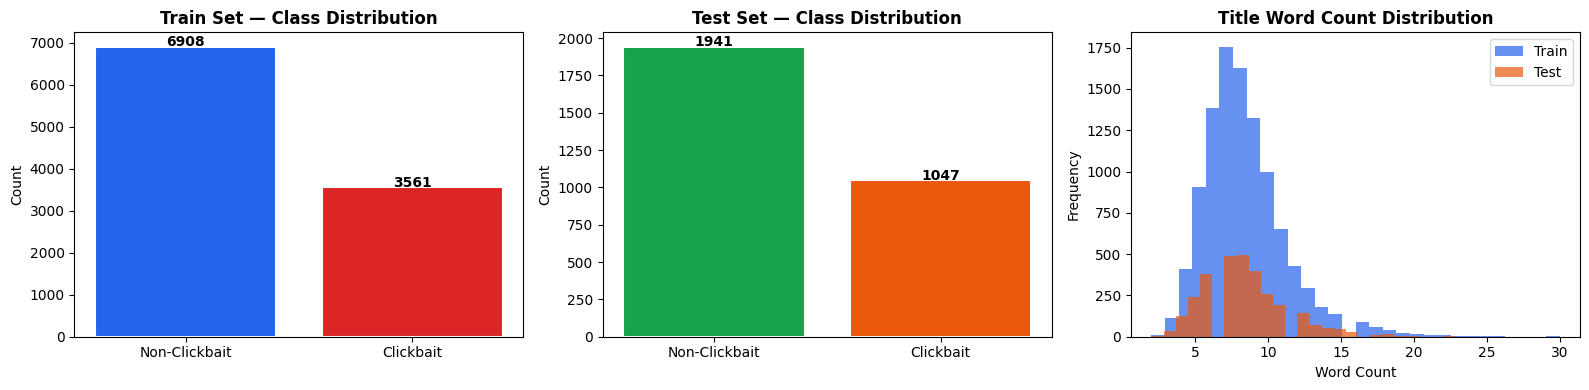

Train title length — mean: 8.3 | max: 30 | 95th pct: 14
Test  title length — mean: 8.3 | max: 27 | 95th pct: 14


In [7]:
# ── Class distribution & title length ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Train class counts
train_counts = bn_train_full[LABEL_COL].value_counts().sort_index()
axes[0].bar([LABEL_NAMES[i] for i in train_counts.index],
            train_counts.values,
            color=["#2563EB", "#DC2626"], edgecolor="white", linewidth=1.5)
axes[0].set_title("Train Set — Class Distribution", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
for i, v in enumerate(train_counts.values):
    axes[0].text(i, v + 10, str(v), ha="center", fontweight="bold")

# Test class counts
test_counts = bn_test[LABEL_COL].value_counts().sort_index()
axes[1].bar([LABEL_NAMES[i] for i in test_counts.index],
            test_counts.values,
            color=["#16A34A", "#EA580C"], edgecolor="white", linewidth=1.5)
axes[1].set_title("Test Set — Class Distribution", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Count")
for i, v in enumerate(test_counts.values):
    axes[1].text(i, v + 5, str(v), ha="center", fontweight="bold")

# Title length distribution
bn_train_full["title_len"] = bn_train_full[TEXT_COL].str.split().str.len()
bn_test["title_len"]       = bn_test[TEXT_COL].str.split().str.len()
axes[2].hist(bn_train_full["title_len"], bins=30, alpha=0.7, label="Train", color="#2563EB")
axes[2].hist(bn_test["title_len"],       bins=30, alpha=0.7, label="Test",  color="#EA580C")
axes[2].set_title("Title Word Count Distribution", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Word Count")
axes[2].set_ylabel("Frequency")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Train title length — mean: {bn_train_full['title_len'].mean():.1f} "
      f"| max: {bn_train_full['title_len'].max()} "
      f"| 95th pct: {bn_train_full['title_len'].quantile(0.95):.0f}")
print(f"Test  title length — mean: {bn_test['title_len'].mean():.1f} "
      f"| max: {bn_test['title_len'].max()} "
      f"| 95th pct: {bn_test['title_len'].quantile(0.95):.0f}")


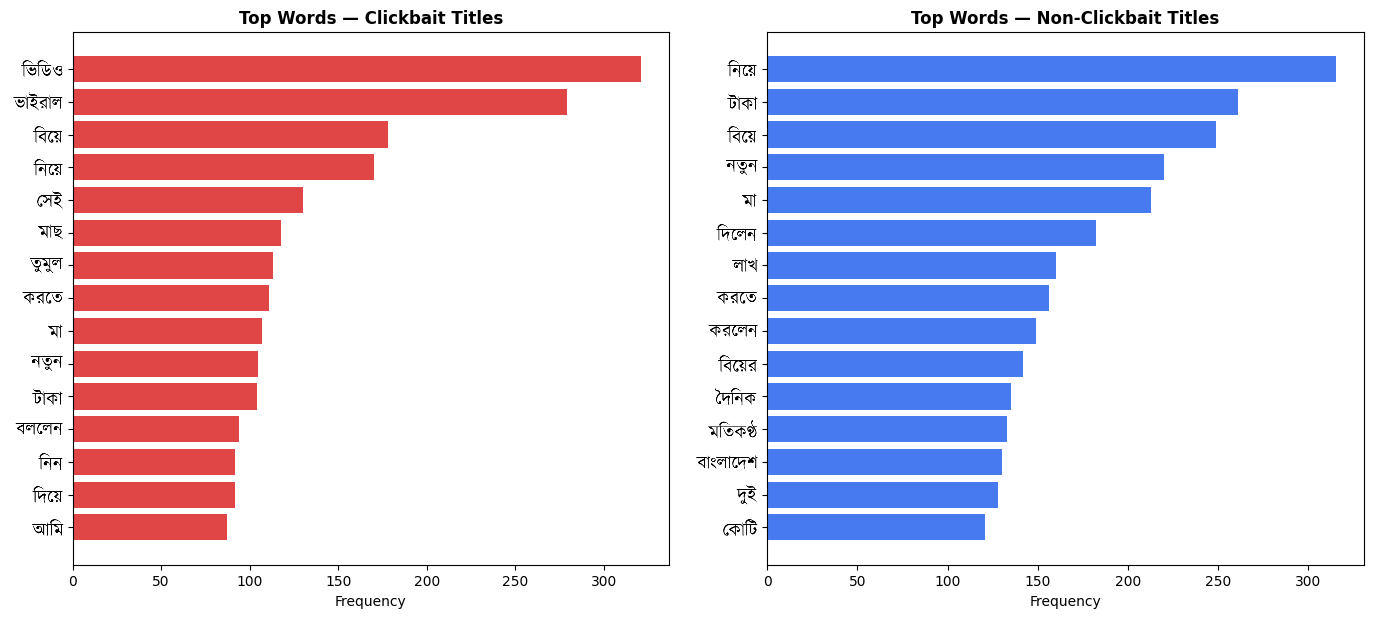

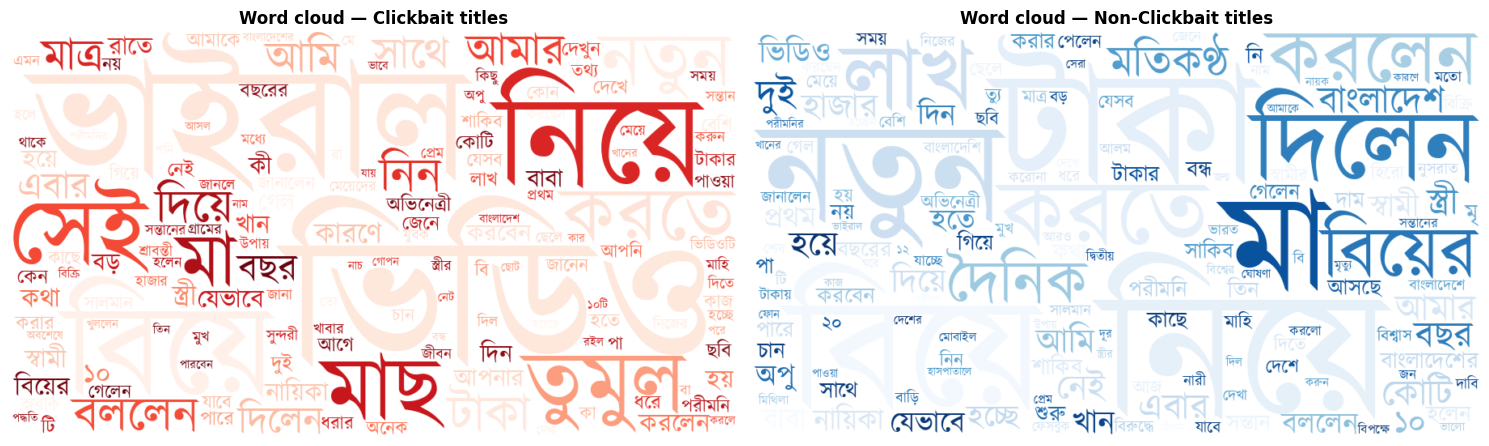

In [8]:
# ── Most frequent Bangla words per class (shaped Bengali labels) ───
# Bengali tick labels are drawn with draw_bengali_text() (PIL/RAQM, Section 1B) so conjuncts
# such as স্ত / ক্ষ / র্ক are joined correctly instead of being broken or boxed.
import re
from collections import Counter

BANGLA_STOPWORDS = {
    "এই","ও","না","যে","এ","এর","কি","করে","এক","সে","আর","তার","হয়","হবে",
    "কে","একটি","হয়েছে","করেন","করা","কিন্তু","আছে","থেকে","জন্য","সঙ্গে","পর",
    "সব","তিনি","তা","এবং","এখন","কোনো","দিয়ে","নিয়ে","হলো","বলে","যা","যান",
}

def top_words(titles, n=15):
    words = []
    for t in titles:
        words += [w for w in re.findall(r"[\u0980-\u09FF]+", str(t))
                  if w not in BANGLA_STOPWORDS and len(w) > 1]
    return Counter(words).most_common(n)

cb_words  = top_words(bn_train_full.loc[bn_train_full[LABEL_COL] == 1, TEXT_COL])
ncb_words = top_words(bn_train_full.loc[bn_train_full[LABEL_COL] == 0, TEXT_COL])

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
label_widths = []
for ax, data, title, color in [
    (axes[0], cb_words,  "Top Words — Clickbait Titles",     "#DC2626"),
    (axes[1], ncb_words, "Top Words — Non-Clickbait Titles", "#2563EB"),
]:
    words, counts = zip(*data[::-1])
    ax.barh(range(len(words)), counts, color=color, alpha=0.85)
    label_widths.append(set_bengali_yticklabels(ax, words, fontsize=13))   # shaped Bengali words
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Frequency")
fig.subplots_adjust(top=0.92, bottom=0.10)
place_axes_row(fig, axes, label_widths)          # leave room for the Bengali labels
plt.savefig(f"{SAVE_DIR}/fig_02_top_words.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ── Word clouds (WordCloud draws through PIL, so it needs the font FILE, not a Matplotlib name) ──
try:
    from wordcloud import WordCloud
    if not BENGALI_FONT_PATH:
        raise RuntimeError("no Bengali font available")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, mask_val, title, cmap in [
        (axes[0], 1, "Word cloud — Clickbait titles",     "Reds"),
        (axes[1], 0, "Word cloud — Non-Clickbait titles", "Blues"),
    ]:
        freqs = dict(top_words(bn_train_full.loc[bn_train_full[LABEL_COL] == mask_val, TEXT_COL], n=150))
        wc = WordCloud(width=900, height=500, background_color="white", font_path=BENGALI_FONT_PATH,
                       collocations=False, colormap=cmap, prefer_horizontal=1.0, random_state=SEED)
        wc.generate_from_frequencies(freqs)
        ax.imshow(wc, interpolation="bilinear")
        ax.axis("off")
        ax.set_title(title, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/fig_02b_wordclouds.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
except Exception as e:
    print(f"⚠️  Word clouds skipped — {type(e).__name__}: {str(e)[:150]}")


## 🛠️ Section 4 — Core Utility Functions

In [9]:
# ── 4.1  Stratified train / validation split ─────────────────────
def make_split(df, text_col=TEXT_COL, label_col=LABEL_COL,
               val_size=DEFAULT_CFG["val_size"], seed=SEED):
    X_tr, X_vl, y_tr, y_vl = train_test_split(
        df[text_col].values,
        df[label_col].values,
        test_size=val_size,
        stratify=df[label_col].values,
        random_state=seed,
    )
    print(f"  Train : {len(X_tr):,}  | Val : {len(X_vl):,}")
    return X_tr, X_vl, y_tr, y_vl


In [10]:
# ── 4.2  Bangla text normalization (optional, BanglaBERT family) ─
# csebuetnlp recommend running their normalizer before tokenizing for
# BanglaBERT / BanglaBERT-large. Falls back to identity if unavailable.
try:
    from normalizer import normalize as _bn_normalize_raw
    BN_NORMALIZER_OK = True
    def bn_normalize(text):
        try:
            return _bn_normalize_raw(text)
        except Exception:
            return text
except Exception:
    BN_NORMALIZER_OK = False
    def bn_normalize(text):
        return text

print(f"BanglaBERT normalizer available: {BN_NORMALIZER_OK}")
# NOTE: whether a given model needs this normalization is controlled per-model
# via the "needs_bn_norm" flag in MODEL_REGISTRY (Section 6), not a fixed set here.


# ── 4.3  PyTorch Dataset class ────────────────────────────────────
class BanglaClickbaitDataset(Dataset):
    """Wraps texts + labels for a HuggingFace tokenizer."""
    def __init__(self, texts, labels, tokenizer, max_len=128, normalize_fn=None):
        if normalize_fn is not None:
            self.texts = [normalize_fn(str(t)) for t in texts]
        else:
            self.texts = [str(t) for t in texts]
        self.labels    = list(labels)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels":         torch.tensor(self.labels[idx], dtype=torch.long),
        }


BanglaBERT normalizer available: True


In [11]:
# ── 4.4  DataLoader builder (supports weighted sampling) ─────────
def make_loaders(X_tr, y_tr, X_vl, y_vl, X_ts, y_ts,
                 tokenizer, cfg, use_weighted_sampler=False):
    normalize_fn = bn_normalize if cfg.get("needs_bn_norm", False) else None

    tr_ds = BanglaClickbaitDataset(X_tr, y_tr, tokenizer, cfg["max_len"], normalize_fn)
    vl_ds = BanglaClickbaitDataset(X_vl, y_vl, tokenizer, cfg["max_len"], normalize_fn)
    ts_ds = BanglaClickbaitDataset(X_ts, y_ts, tokenizer, cfg["max_len"], normalize_fn)

    sampler = None
    shuffle  = True
    if use_weighted_sampler:
        class_counts = np.bincount(y_tr)
        weights      = 1.0 / class_counts
        sample_wts   = np.array([weights[y] for y in y_tr])
        sampler      = WeightedRandomSampler(
            torch.DoubleTensor(sample_wts), len(sample_wts), replacement=True)
        shuffle = False  # mutually exclusive with sampler

    n_workers = min(4, os.cpu_count() or 2)
    tr_loader = DataLoader(tr_ds, batch_size=cfg["batch_size"],
                           sampler=sampler, shuffle=shuffle,
                           num_workers=n_workers, pin_memory=True,
                           persistent_workers=n_workers > 0, drop_last=True)
    vl_loader = DataLoader(vl_ds, batch_size=cfg["batch_size"],
                           shuffle=False, num_workers=n_workers, pin_memory=True,
                           persistent_workers=n_workers > 0)
    ts_loader = DataLoader(ts_ds, batch_size=cfg["batch_size"],
                           shuffle=False, num_workers=n_workers, pin_memory=True,
                           persistent_workers=n_workers > 0)
    return tr_loader, vl_loader, ts_loader


In [12]:
# ── 4.5  Loss functions ───────────────────────────────────────────
class FocalLoss(nn.Module):
    """Focal Loss for imbalanced binary / multi-class classification."""
    def __init__(self, gamma=2.0, alpha=None, reduction="mean"):
        super().__init__()
        self.gamma     = gamma
        self.alpha     = alpha      # tensor of per-class weights or None
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = nn.functional.cross_entropy(
            logits, targets, weight=self.alpha, reduction="none")
        pt      = torch.exp(-ce_loss)
        focal   = (1 - pt) ** self.gamma * ce_loss
        return focal.mean() if self.reduction == "mean" else focal.sum()


def get_criterion(loss_type, y_train, device):
    """Return the requested loss function, computing class weights from data."""
    counts      = np.bincount(y_train)
    total       = len(y_train)
    # Inverse-frequency weights
    raw_weights = total / (len(counts) * counts.astype(float))
    weights     = torch.tensor(raw_weights, dtype=torch.float32).to(device)

    if loss_type == "ce_weighted":
        return nn.CrossEntropyLoss(weight=weights)
    elif loss_type == "focal":
        return FocalLoss(gamma=2.0, alpha=weights)
    else:  # standard CE
        return nn.CrossEntropyLoss()


In [13]:
# ── 4.6  Multi-GPU helpers ────────────────────────────────────────
def wrap_multi_gpu(model):
    """Wrap a model in nn.DataParallel if more than one GPU is visible."""
    model = model.to(DEVICE)
    if N_GPUS > 1:
        model = nn.DataParallel(model)
    return model


def get_base_model(model):
    """Unwrap nn.DataParallel to get the underlying HF model (for save/load)."""
    return model.module if isinstance(model, nn.DataParallel) else model


def forward_logits(model, ids, mask):
    """Forward pass that works identically for plain and DataParallel-wrapped
    HuggingFace models (return_dict=False → plain tuple output, which
    DataParallel can gather across GPUs without issue)."""
    out = model(input_ids=ids, attention_mask=mask, return_dict=False)
    return out[0]


In [14]:
# ── 4.7  One training epoch (AMP mixed precision) ────────────────
def train_one_epoch(model, loader, optimizer, criterion, scheduler, cfg, scaler):
    model.train()
    total_loss, preds_all, labels_all = 0.0, [], []
    for batch in loader:
        ids  = batch["input_ids"].to(DEVICE, non_blocking=True)
        mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
        labs = batch["labels"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = forward_logits(model, ids, mask)
            loss   = criterion(logits, labs)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item()
        preds_all  += logits.argmax(-1).detach().cpu().tolist()
        labels_all += labs.cpu().tolist()

    macro_f1 = f1_score(labels_all, preds_all, average="macro", zero_division=0)
    return total_loss / len(loader), macro_f1


# ── 4.8  One validation epoch ─────────────────────────────────────
def val_one_epoch(model, loader, criterion):
    model.eval()
    total_loss, preds_all, labels_all = 0.0, [], []
    with torch.no_grad():
        for batch in loader:
            ids  = batch["input_ids"].to(DEVICE, non_blocking=True)
            mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            labs = batch["labels"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = forward_logits(model, ids, mask)
                loss   = criterion(logits, labs)
            total_loss += loss.item()
            preds_all  += logits.argmax(-1).cpu().tolist()
            labels_all += labs.cpu().tolist()

    macro_f1 = f1_score(labels_all, preds_all, average="macro", zero_division=0)
    return total_loss / len(loader), macro_f1


In [15]:
# ── 4.9  Full training loop with early stopping & checkpointing ───
def train_model(model, tr_loader, vl_loader, cfg,
                save_name="model", y_train=None, loss_type="ce_weighted"):
    """
    Train with:
      - AdamW + linear warmup scheduler
      - class-weighted CE or focal loss
      - AMP mixed precision (T4-friendly fp16)
      - gradient clipping
      - early stopping on validation macro-F1
      - best checkpoint saving (DataParallel-safe: always saves the
        underlying base model's state_dict, never the wrapper's)
    """
    if y_train is None:
        y_train = [b["labels"].tolist() for b in tr_loader]
        y_train = [l for sub in y_train for l in sub]

    criterion = get_criterion(loss_type, y_train, DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])

    total_steps  = len(tr_loader) * cfg["epochs"]
    warmup_steps = int(cfg["warmup_ratio"] * total_steps)
    scheduler    = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps,
        num_training_steps=total_steps)

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    best_vl_f1   = 0.0
    patience_cnt = 0
    history      = {"tr_loss": [], "vl_loss": [], "tr_f1": [], "vl_f1": []}
    save_path    = f"{SAVE_DIR}/best_{save_name}.pt"

    header = f"{'Epoch':>6}  {'TrLoss':>8}  {'VlLoss':>8}  {'TrF1':>7}  {'VlF1':>7}"
    print(header)
    print("-" * len(header))

    for epoch in range(1, cfg["epochs"] + 1):
        t0                  = time.time()
        tr_loss, tr_f1      = train_one_epoch(model, tr_loader, optimizer,
                                              criterion, scheduler, cfg, scaler)
        vl_loss, vl_f1      = val_one_epoch(model, vl_loader, criterion)
        elapsed             = time.time() - t0

        history["tr_loss"].append(tr_loss)
        history["vl_loss"].append(vl_loss)
        history["tr_f1"].append(tr_f1)
        history["vl_f1"].append(vl_f1)

        flag = ""
        if vl_f1 > best_vl_f1:
            best_vl_f1   = vl_f1
            patience_cnt = 0
            torch.save(get_base_model(model).state_dict(), save_path)
            flag = " ✅ saved"
        else:
            patience_cnt += 1
            flag = f" (patience {patience_cnt}/{cfg['patience']})"

        print(f"{epoch:>6}  {tr_loss:>8.4f}  {vl_loss:>8.4f}  "
              f"{tr_f1:>7.4f}  {vl_f1:>7.4f}  [{elapsed:.0f}s]{flag}")

        if patience_cnt >= cfg["patience"]:
            print(f"  ⏹  Early stop at epoch {epoch} — best val F1={best_vl_f1:.4f}")
            break

    torch.cuda.empty_cache()
    return history, best_vl_f1


In [16]:
# ── 4.10  Threshold tuning on validation set ──────────────────────
def tune_threshold(model, vl_loader, model_path, thresholds=None):
    """
    Sweep decision thresholds on the validation set.
    Returns the threshold that maximises validation macro-F1.
    """
    if thresholds is None:
        thresholds = np.arange(0.30, 0.71, 0.02)

    get_base_model(model).load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch in vl_loader:
            ids  = batch["input_ids"].to(DEVICE, non_blocking=True)
            mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = forward_logits(model, ids, mask)
            probs = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().tolist()
            all_probs  += probs
            all_labels += batch["labels"].tolist()

    best_thr, best_f1 = 0.5, 0.0
    for thr in thresholds:
        preds  = [1 if p >= thr else 0 for p in all_probs]
        mf1    = f1_score(all_labels, preds, average="macro", zero_division=0)
        if mf1 > best_f1:
            best_f1, best_thr = mf1, thr

    print(f"  Best threshold={best_thr:.2f}  →  Val Macro-F1={best_f1:.4f}")
    return best_thr, all_probs, all_labels


In [17]:
# ── 4.11  Full test-set evaluation ────────────────────────────────
def evaluate_model(model, ts_loader, model_path, title="", threshold=0.5):
    """Load best checkpoint, run inference at given threshold, return
    (metrics_dict, all_probs, all_labels, preds).

    metrics_dict now includes BOTH classes' precision/recall/F1 (fixes the
    original notebook's heatmap, which faked Non-Clickbait as `1 - Clickbait`),
    plus ROC-AUC and PR-AUC (average precision)."""
    get_base_model(model).load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch in ts_loader:
            ids  = batch["input_ids"].to(DEVICE, non_blocking=True)
            mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = forward_logits(model, ids, mask)
            probs = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().tolist()
            all_probs  += probs
            all_labels += batch["labels"].tolist()

    preds = [1 if p >= threshold else 0 for p in all_probs]

    acc  = accuracy_score(all_labels, preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        all_labels, preds, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
        all_labels, preds, average="weighted", zero_division=0)
    report = classification_report(
        all_labels, preds, target_names=LABEL_NAMES, zero_division=0)
    cm     = confusion_matrix(all_labels, preds)

    # Per-class metrics for BOTH classes
    per_class = classification_report(
        all_labels, preds, target_names=LABEL_NAMES,
        output_dict=True, zero_division=0)
    cb_prec, cb_rec, cb_f1    = (per_class["Clickbait"][k] for k in ("precision", "recall", "f1-score"))
    nc_prec, nc_rec, nc_f1    = (per_class["Non-Clickbait"][k] for k in ("precision", "recall", "f1-score"))

    # Threshold-independent ranking metrics
    try:
        roc_auc = roc_auc_score(all_labels, all_probs)
        pr_auc  = average_precision_score(all_labels, all_probs)
    except ValueError:
        roc_auc, pr_auc = float("nan"), float("nan")

    print(f"\n{'='*60}")
    print(f"  {title}  (threshold={threshold:.2f})")
    print(f"{'='*60}")
    print(report)
    print(f"  ROC-AUC = {roc_auc:.4f}   PR-AUC (Avg. Precision) = {pr_auc:.4f}")

    metrics = dict(
        title=title, threshold=threshold,
        accuracy=acc,
        macro_precision=prec_macro, macro_recall=rec_macro, macro_f1=f1_macro,
        weighted_precision=prec_w, weighted_recall=rec_w, weighted_f1=f1_w,
        cb_precision=cb_prec, cb_recall=cb_rec, cb_f1=cb_f1,
        nc_precision=nc_prec, nc_recall=nc_rec, nc_f1=nc_f1,
        roc_auc=roc_auc, pr_auc=pr_auc,
        confusion_matrix=cm,
    )
    return metrics, all_probs, all_labels, preds


In [18]:
# ── 4.12  Plotting helpers ────────────────────────────────────────
def plot_training_curves(history, title, save_path=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    epochs = range(1, len(history["tr_loss"]) + 1)
    ax1.plot(epochs, history["tr_loss"], "o-", color="#DC2626", label="Train Loss")
    ax1.plot(epochs, history["vl_loss"], "s--", color="#2563EB", label="Val Loss")
    ax1.set_title(f"{title} — Loss", fontweight="bold")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
    ax1.legend(); ax1.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    ax2.plot(epochs, history["tr_f1"], "o-", color="#EA580C", label="Train Macro-F1")
    ax2.plot(epochs, history["vl_f1"], "s--", color="#16A34A", label="Val Macro-F1")
    ax2.set_title(f"{title} — Macro-F1", fontweight="bold")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Macro-F1")
    ax2.set_ylim(0, 1); ax2.legend()
    ax2.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_confusion_matrix(cm, title, save_path=None):
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(f"Confusion Matrix — {title}", fontweight="bold")
    ax.set_ylabel("True Label"); ax.set_xlabel("Predicted Label")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_classification_heatmap(metrics, title, save_path=None):
    """Heatmap of precision/recall/F1 per class.
    FIX vs. original notebook: Non-Clickbait row now uses the model's
    *actual* Non-Clickbait precision/recall/F1 (computed in evaluate_model),
    instead of incorrectly assuming it equals `1 - Clickbait metric`."""
    data = pd.DataFrame({
        "Non-Clickbait": [
            metrics["nc_precision"],
            metrics["nc_recall"],
            metrics["nc_f1"],
        ],
        "Clickbait": [
            metrics["cb_precision"],
            metrics["cb_recall"],
            metrics["cb_f1"],
        ]
    }, index=["Precision", "Recall", "F1-score"])
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.heatmap(data, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=1,
                linewidths=0.5, ax=ax)
    ax.set_title(f"Classification Report Heatmap — {title}", fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# ── GPU memory helper ─────────────────────────────────────────────
def gpu_clear(label=""):
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        free = torch.cuda.mem_get_info()[0] / 1e9
        print(f"  GPU cleared {label}— {free:.2f} GB free")


print("✅ All utility functions defined")


✅ All utility functions defined


## ✂️ Section 5 — Stratified Train / Validation Split

In [19]:
print("Splitting BanglaBait train → 90% train / 10% val (stratified) ...")
X_tr, X_vl, y_tr, y_vl = make_split(bn_train_full)

X_ts = bn_test[TEXT_COL].values
y_ts = bn_test[LABEL_COL].values

print(f"Train  : {len(X_tr):,}  | Val : {len(X_vl):,}  | Test : {len(X_ts):,}")
print("Label balance in each split:")
for split_name, y in [("Train", y_tr), ("Val", y_vl), ("Test", y_ts)]:
    cnts = np.bincount(y)
    print(f"  {split_name:<6}: Non-CB={cnts[0]:,}  CB={cnts[1]:,}  "
          f"Imbalance ratio={cnts[0]/cnts[1]:.2f}")


Splitting BanglaBait train → 90% train / 10% val (stratified) ...
  Train : 9,422  | Val : 1,047
Train  : 9,422  | Val : 1,047  | Test : 2,988
Label balance in each split:
  Train : Non-CB=6,217  CB=3,205  Imbalance ratio=1.94
  Val   : Non-CB=691  CB=356  Imbalance ratio=1.94
  Test  : Non-CB=1,941  CB=1,047  Imbalance ratio=1.85


## 🗂️ Section 6 — Model Configuration Registry

In [20]:
# Each dict defines one experiment. Batch sizes assume T4 x2 + DataParallel
# (roughly half the batch goes to each GPU) — halve them if you only have 1 GPU.
#
# loss_type options : "ce" | "ce_weighted" | "focal"
# use_wrs           : True → WeightedRandomSampler
# needs_bn_norm     : True → apply csebuetnlp normalizer before tokenizing
#
# NOTE on fixes vs. the original notebook:
#   • "csebuetnlp/banglabert-large" (hyphen) does not exist on the Hub and
#     raised a 404. The correct, fully public repo id uses an underscore:
#     "csebuetnlp/banglabert_large".
# ─────────────────────────────────────────────────────────────────
MODEL_REGISTRY = [
    {
        "name"        : "XLM-RoBERTa-base",
        "model_id"    : "xlm-roberta-base",
        "save_name"   : "xlmr_base",
        "max_len"     : 128,
        "batch_size"  : 32,
        "epochs"      : 5,
        "lr"          : 2e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "ce_weighted",
        "use_wrs"     : False,
    },
    {
        "name"        : "XLM-RoBERTa-large",
        "model_id"    : "xlm-roberta-large",
        "save_name"   : "xlmr_large",
        "max_len"     : 128,
        "batch_size"  : 16,
        "epochs"      : 5,
        "lr"          : 1e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "focal",
        "use_wrs"     : False,
    },
    {
        "name"        : "BanglaBERT (csebuetnlp)",
        "model_id"    : "csebuetnlp/banglabert",
        "save_name"   : "banglabert",
        "max_len"     : 128,
        "batch_size"  : 32,
        "epochs"      : 5,
        "lr"          : 2e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "ce_weighted",
        "use_wrs"     : False,
        "needs_bn_norm": True,
    },
    {
        # FIXED: was "csebuetnlp/banglabert-large" (hyphen, 404). The real,
        # fully public repo id uses an underscore.
        "name"        : "BanglaBERT-large (csebuetnlp)",
        "model_id"    : "csebuetnlp/banglabert_large",
        "save_name"   : "banglabert_large",
        "max_len"     : 128,
        "batch_size"  : 16,
        "epochs"      : 5,
        "lr"          : 1e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "focal",
        "use_wrs"     : False,
        "needs_bn_norm": True,
    },
    {
        # Added: a second, widely-cited Bangla-specific BERT for a broader comparison.
        "name"        : "Bangla-BERT-Base (sagorsarker)",
        "model_id"    : "sagorsarker/bangla-bert-base",
        "save_name"   : "sagor_banglabert",
        "max_len"     : 128,
        "batch_size"  : 32,
        "epochs"      : 5,
        "lr"          : 2e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "ce_weighted",
        "use_wrs"     : False,
    },
    {
        "name"        : "mDeBERTa-v3-base",
        "model_id"    : "microsoft/mdeberta-v3-base",
        "save_name"   : "mdeberta",
        "max_len"     : 128,
        "batch_size"  : 32,
        "epochs"      : 5,
        "lr"          : 1e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "ce_weighted",
        "use_wrs"     : False,
    },
    {
        "name"        : "MuRIL-base",
        "model_id"    : "google/muril-base-cased",
        "save_name"   : "muril",
        "max_len"     : 128,
        "batch_size"  : 32,
        "epochs"      : 5,
        "lr"          : 2e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "ce_weighted",
        "use_wrs"     : True,
    },
    {
        "name"        : "IndicBERTv2",
        "model_id"    : "ai4bharat/IndicBERTv2-MLM-Sam-TLM",
        "save_name"   : "indicbert_v2",
        "max_len"     : 128,
        "batch_size"  : 32,
        "epochs"      : 5,
        "lr"          : 2e-5,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "grad_clip"   : 1.0,
        "patience"    : 3,
        "loss_type"   : "ce_weighted",
        "use_wrs"     : False,
    },
]

print(f"✅ {len(MODEL_REGISTRY)} models registered for training")
for m in MODEL_REGISTRY:
    print(f"  • {m['name']}  ({m['model_id']})")

# ── Quick accessibility check ─────────────────────────────────────
print("\nChecking model accessibility on HuggingFace Hub...")
from huggingface_hub import model_info as hf_model_info
for m in MODEL_REGISTRY:
    try:
        hf_model_info(m["model_id"])
        print(f"  ✅ OK      — {m['name']}")
    except Exception as e:
        print(f"  ❌ BLOCKED — {m['name']}  ({type(e).__name__})")


✅ 8 models registered for training
  • XLM-RoBERTa-base  (xlm-roberta-base)
  • XLM-RoBERTa-large  (xlm-roberta-large)
  • BanglaBERT (csebuetnlp)  (csebuetnlp/banglabert)
  • BanglaBERT-large (csebuetnlp)  (csebuetnlp/banglabert_large)
  • Bangla-BERT-Base (sagorsarker)  (sagorsarker/bangla-bert-base)
  • mDeBERTa-v3-base  (microsoft/mdeberta-v3-base)
  • MuRIL-base  (google/muril-base-cased)
  • IndicBERTv2  (ai4bharat/IndicBERTv2-MLM-Sam-TLM)

Checking model accessibility on HuggingFace Hub...
  ✅ OK      — XLM-RoBERTa-base
  ✅ OK      — XLM-RoBERTa-large
  ✅ OK      — BanglaBERT (csebuetnlp)
  ✅ OK      — BanglaBERT-large (csebuetnlp)
  ✅ OK      — Bangla-BERT-Base (sagorsarker)
  ✅ OK      — mDeBERTa-v3-base
  ✅ OK      — MuRIL-base
  ✅ OK      — IndicBERTv2


## 🚀 Section 7 — Training All Models

Each model is:
1. Loaded fresh from HuggingFace Hub
2. Wrapped in `nn.DataParallel` across both T4s (if 2 GPUs are visible)
3. Trained with AMP mixed precision, class-weighted/focal loss, early stopping
4. Threshold-tuned on the validation set
5. Evaluated on the held-out test set (Accuracy, Macro-F1, ROC-AUC, PR-AUC, ...)

Raw probabilities/predictions are kept in `ALL_PROBS` / `ALL_PREDS` for the
ROC/PR comparison plots and the McNemar significance test later on.



═════════════════════════════════════════════════════════════════
  MODEL : XLM-RoBERTa-base
  ID    : xlm-roberta-base
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 278 M
  Batches — Train:294 | Val:33 | Test:94
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------
     1    0.6212    0.5081   0.6456   0.7035  [127s] ✅ saved
     2    0.4978    0.4617   0.7590   0.7532  [126s] ✅ saved
     3    0.4293    0.4499   0.8001   0.7720  [126s] ✅ saved
     4    0.3705    0.4663   0.8337   0.7791  [126s] ✅ saved
     5    0.3176    0.5007   0.8608   0.7851  [126s] ✅ saved

  Best Val Macro-F1 during training: 0.7851


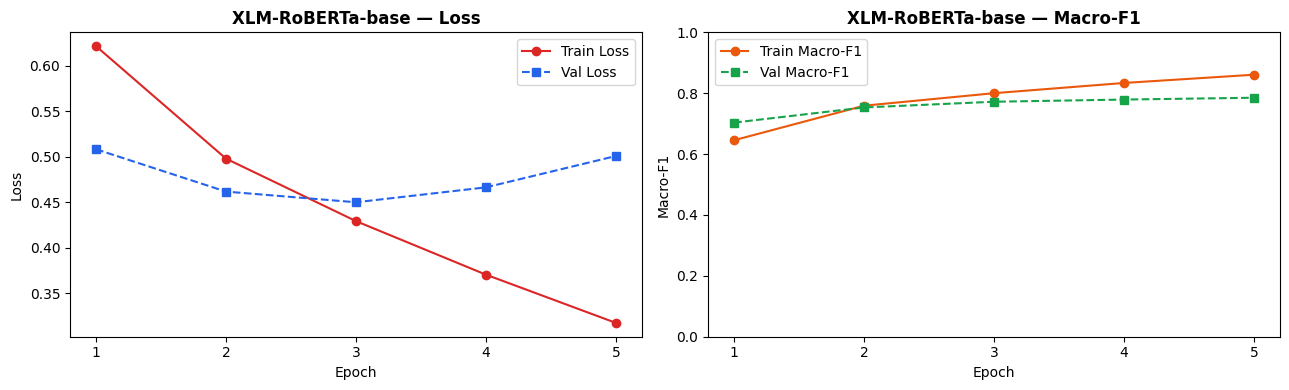

  Tuning decision threshold on validation set...
  Best threshold=0.50  →  Val Macro-F1=0.7851

  XLM-RoBERTa-base  (threshold=0.50)
               precision    recall  f1-score   support

Non-Clickbait       0.87      0.83      0.85      1941
    Clickbait       0.71      0.77      0.74      1047

     accuracy                           0.81      2988
    macro avg       0.79      0.80      0.79      2988
 weighted avg       0.81      0.81      0.81      2988

  ROC-AUC = 0.8763   PR-AUC (Avg. Precision) = 0.7982


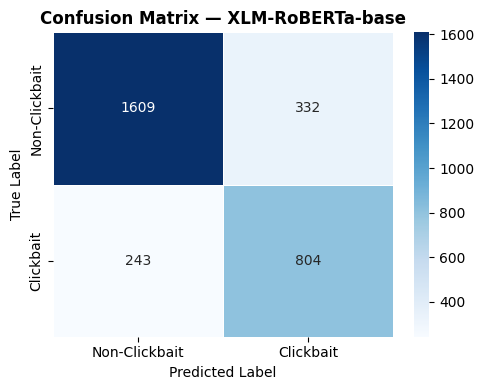

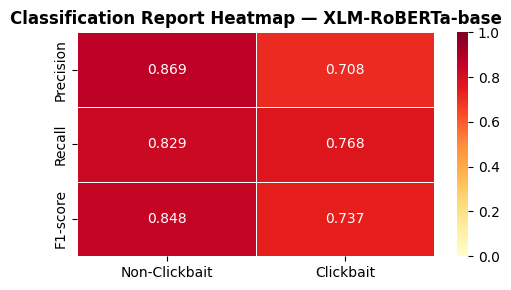

  GPU cleared after XLM-RoBERTa-base — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : XLM-RoBERTa-large
  ID    : xlm-roberta-large
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 560 M
  Batches — Train:588 | Val:66 | Test:187
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------
     1    0.1789    0.1533   0.5645   0.4818  [502s] ✅ saved
     2    0.1395    0.1222   0.7072   0.7673  [495s] ✅ saved
     3    0.1173    0.1200   0.7729   0.7617  [495s] (patience 1/3)
     4    0.1018    0.1425   0.8174   0.7684  [495s] ✅ saved
     5    0.0853    0.1479   0.8554   0.7732  [495s] ✅ saved

  Best Val Macro-F1 during training: 0.7732


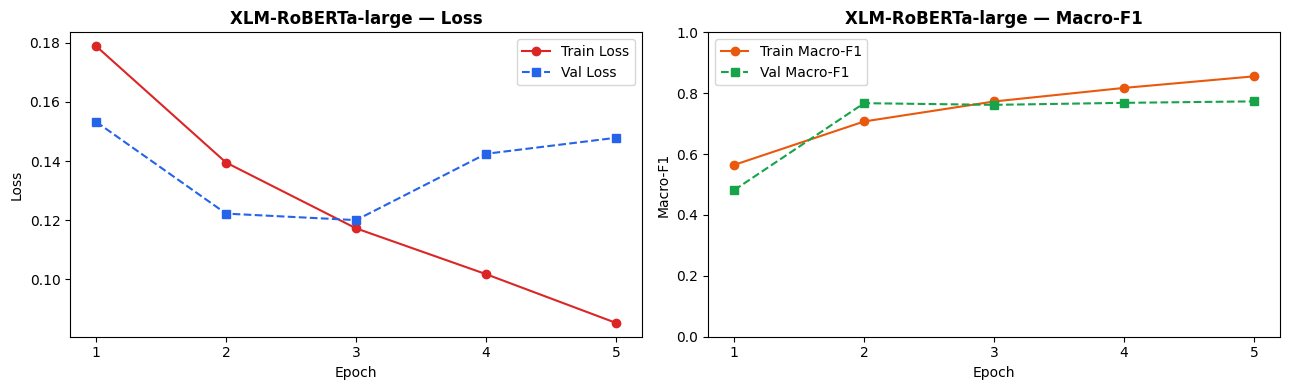

  Tuning decision threshold on validation set...
  Best threshold=0.58  →  Val Macro-F1=0.7968

  XLM-RoBERTa-large  (threshold=0.58)
               precision    recall  f1-score   support

Non-Clickbait       0.88      0.84      0.86      1941
    Clickbait       0.72      0.79      0.76      1047

     accuracy                           0.82      2988
    macro avg       0.80      0.82      0.81      2988
 weighted avg       0.83      0.82      0.82      2988

  ROC-AUC = 0.8911   PR-AUC (Avg. Precision) = 0.8295


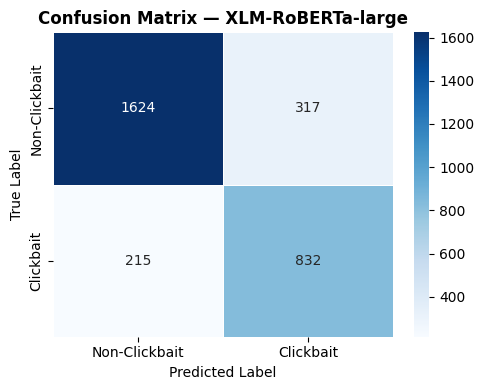

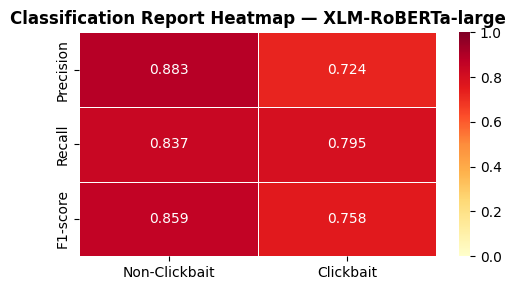

  GPU cleared after XLM-RoBERTa-large — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : BanglaBERT (csebuetnlp)
  ID    : csebuetnlp/banglabert
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 111 M


model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

  Batches — Train:294 | Val:33 | Test:94
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------
     1    0.5665    0.4795   0.6757   0.7816  [72s] ✅ saved
     2    0.3978    0.4558   0.8169   0.8024  [71s] ✅ saved
     3    0.2786    0.4812   0.8840   0.8073  [71s] ✅ saved
     4    0.1869    0.6411   0.9289   0.7862  [71s] (patience 1/3)
     5    0.1294    0.6855   0.9539   0.7962  [71s] (patience 2/3)

  Best Val Macro-F1 during training: 0.8073


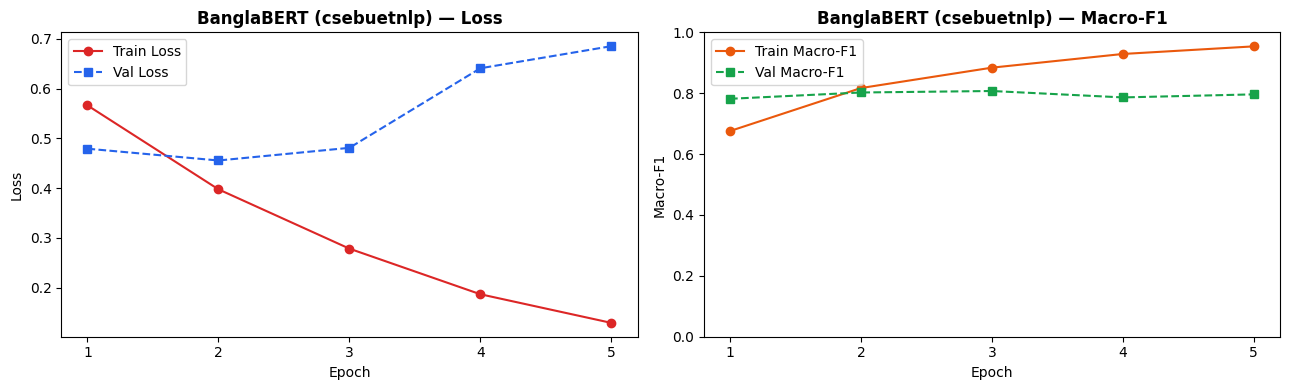

  Tuning decision threshold on validation set...
  Best threshold=0.44  →  Val Macro-F1=0.8084

  BanglaBERT (csebuetnlp)  (threshold=0.44)
               precision    recall  f1-score   support

Non-Clickbait       0.87      0.83      0.85      1941
    Clickbait       0.71      0.77      0.74      1047

     accuracy                           0.81      2988
    macro avg       0.79      0.80      0.80      2988
 weighted avg       0.82      0.81      0.81      2988

  ROC-AUC = 0.8893   PR-AUC (Avg. Precision) = 0.8154


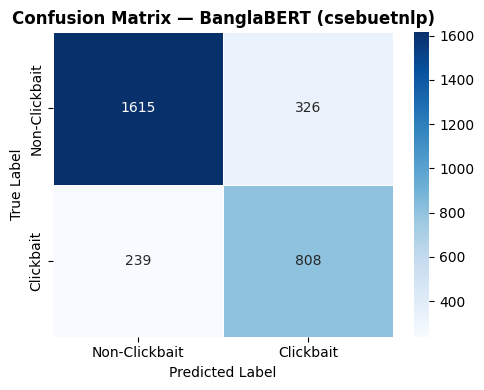

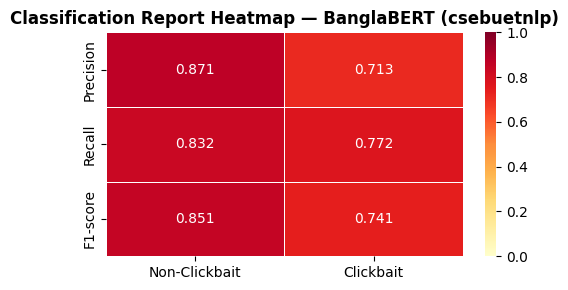

  GPU cleared after BanglaBERT (csebuetnlp) — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : BanglaBERT-large (csebuetnlp)
  ID    : csebuetnlp/banglabert_large
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/880 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.35G [00:00<?, ?B/s]

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 337 M


model.safetensors:   0%|          | 0.00/1.35G [00:00<?, ?B/s]

  Batches — Train:588 | Val:66 | Test:187
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------
     1    0.1536    0.1295   0.6058   0.7586  [350s] ✅ saved
     2    0.1135    0.1135   0.7923   0.7681  [347s] ✅ saved
     3    0.0738    0.1616   0.8873   0.8060  [347s] ✅ saved
     4    0.0431    0.2714   0.9487   0.7888  [347s] (patience 1/3)
     5    0.0259    0.4023   0.9731   0.7830  [347s] (patience 2/3)

  Best Val Macro-F1 during training: 0.8060


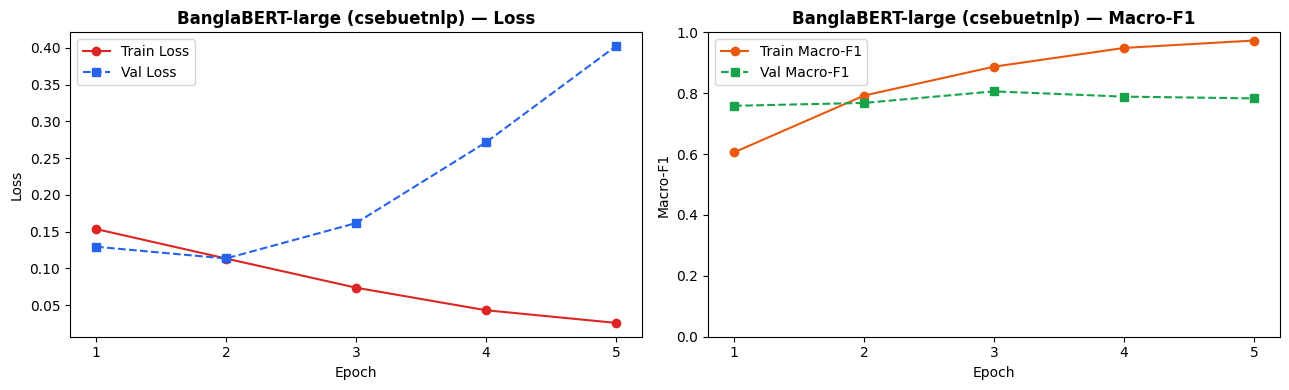

  Tuning decision threshold on validation set...
  Best threshold=0.46  →  Val Macro-F1=0.8076

  BanglaBERT-large (csebuetnlp)  (threshold=0.46)
               precision    recall  f1-score   support

Non-Clickbait       0.89      0.81      0.85      1941
    Clickbait       0.70      0.82      0.75      1047

     accuracy                           0.81      2988
    macro avg       0.79      0.81      0.80      2988
 weighted avg       0.82      0.81      0.81      2988

  ROC-AUC = 0.8947   PR-AUC (Avg. Precision) = 0.8202


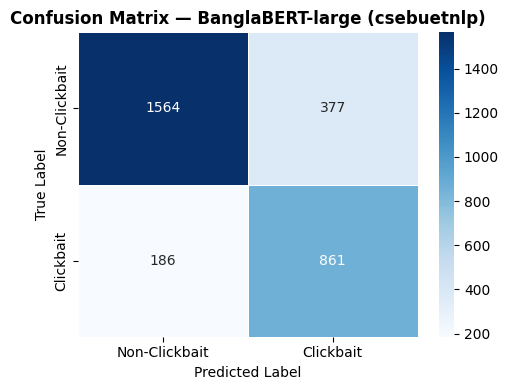

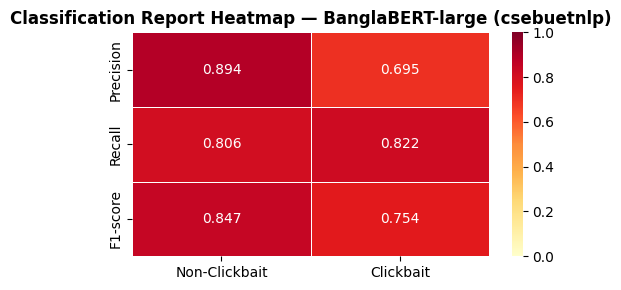

  GPU cleared after BanglaBERT-large (csebuetnlp) — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : Bangla-BERT-Base (sagorsarker)
  ID    : sagorsarker/bangla-bert-base
═════════════════════════════════════════════════════════════════


config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/660M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at sagorsarker/bangla-bert-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 164 M
  Batches — Train:294 | Val:33 | Test:94
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------
     1    0.5764    0.5315   0.6777   0.7042  [86s] ✅ saved
     2    0.4475    0.5194   0.7828   0.7420  [85s] ✅ saved
     3    0.3058    0.6116   0.8629   0.7477  [85s] ✅ saved
     4    0.1844    0.7042   0.9251   0.7525  [85s] ✅ saved
     5    0.1209    0.7914   0.9539   0.7542  [85s] ✅ saved

  Best Val Macro-F1 during training: 0.7542


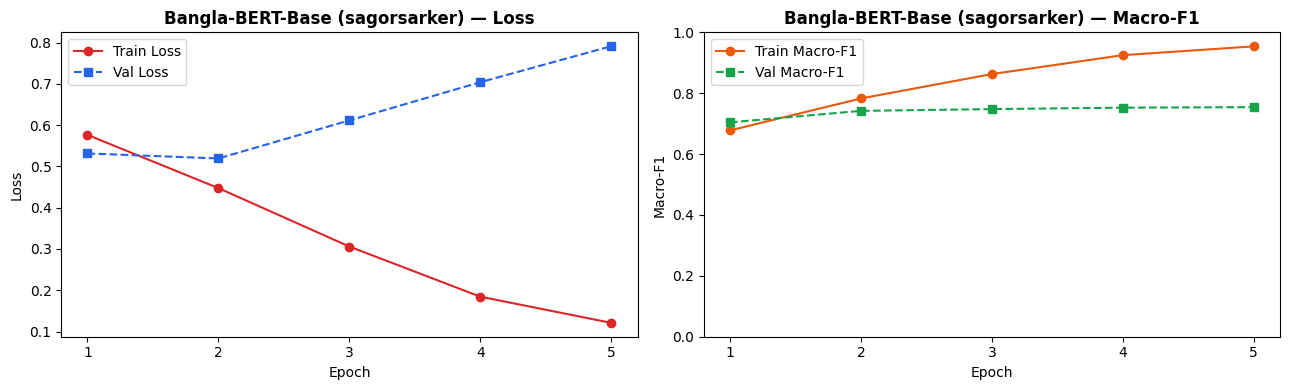

  Tuning decision threshold on validation set...
  Best threshold=0.48  →  Val Macro-F1=0.7580

  Bangla-BERT-Base (sagorsarker)  (threshold=0.48)
               precision    recall  f1-score   support

Non-Clickbait       0.84      0.82      0.83      1941
    Clickbait       0.68      0.72      0.70      1047

     accuracy                           0.78      2988
    macro avg       0.76      0.77      0.76      2988
 weighted avg       0.78      0.78      0.78      2988

  ROC-AUC = 0.8438   PR-AUC (Avg. Precision) = 0.7645


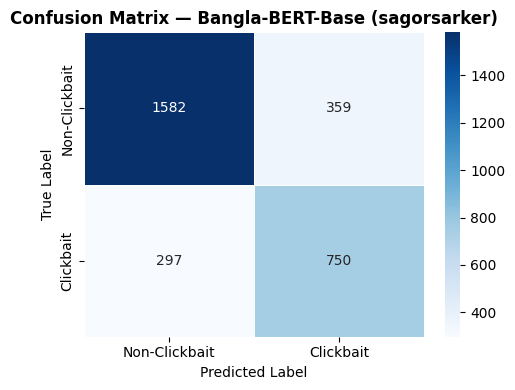

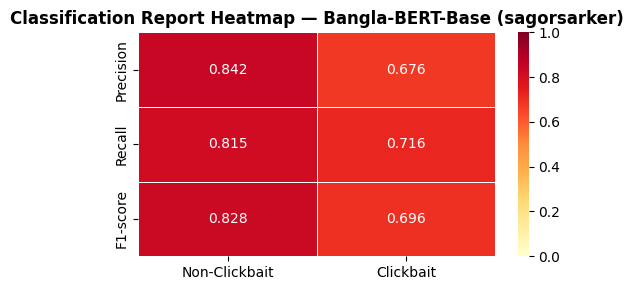

  GPU cleared after Bangla-BERT-Base (sagorsarker) — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : mDeBERTa-v3-base
  ID    : microsoft/mdeberta-v3-base
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 279 M
  Batches — Train:294 | Val:33 | Test:94
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------
     1    0.6085    0.5068   0.6173   0.7577  [155s] ✅ saved
     2    0.4659    0.4991   0.7777   0.7680  [149s] ✅ saved
     3    0.4086    0.5062   0.8065   0.7737  [149s] ✅ saved
     4    0.3480    0.5438   0.8420   0.7771  [149s] ✅ saved
     5    0.3210    0.5612   0.8563   0.7712  [149s] (patience 1/3)

  Best Val Macro-F1 during training: 0.7771


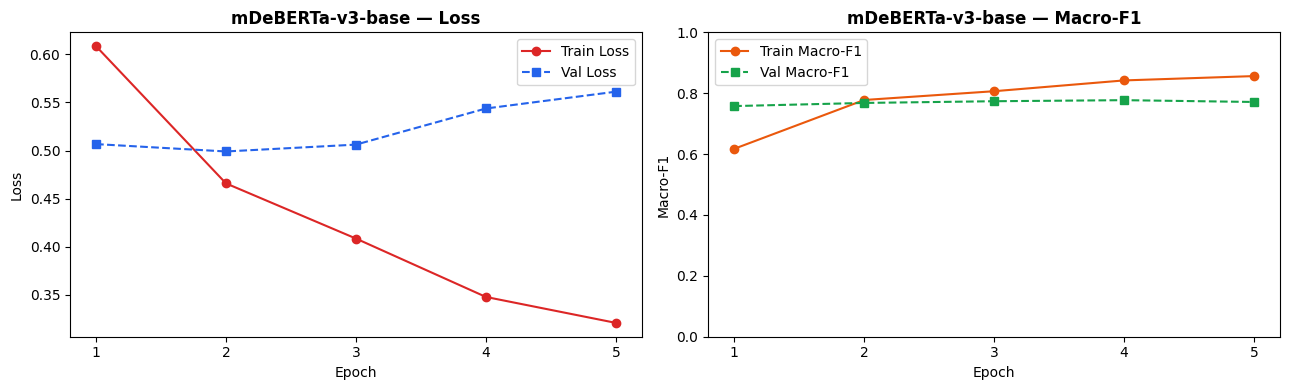

  Tuning decision threshold on validation set...
  Best threshold=0.44  →  Val Macro-F1=0.7805

  mDeBERTa-v3-base  (threshold=0.44)
               precision    recall  f1-score   support

Non-Clickbait       0.86      0.83      0.85      1941
    Clickbait       0.71      0.75      0.73      1047

     accuracy                           0.80      2988
    macro avg       0.78      0.79      0.79      2988
 weighted avg       0.81      0.80      0.80      2988

  ROC-AUC = 0.8713   PR-AUC (Avg. Precision) = 0.7819


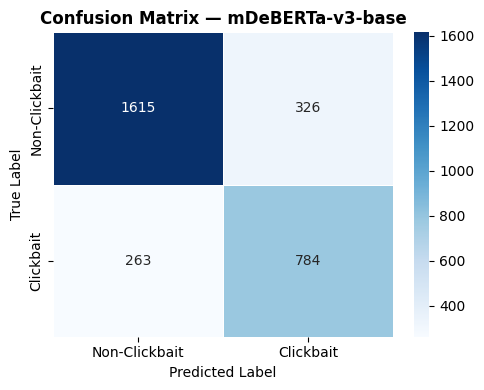

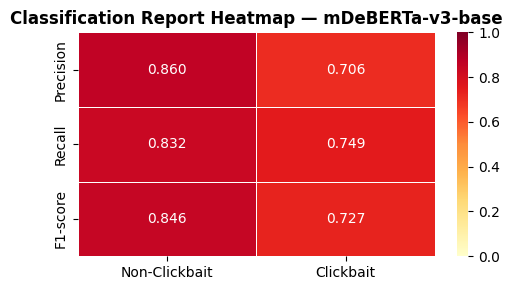

  GPU cleared after mDeBERTa-v3-base — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : MuRIL-base
  ID    : google/muril-base-cased
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/953M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 238 M
  Batches — Train:294 | Val:33 | Test:94
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------


model.safetensors:   0%|          | 0.00/953M [00:00<?, ?B/s]

     1    0.6165    0.5807   0.4081   0.7379  [116s] ✅ saved
     2    0.4646    0.5516   0.7790   0.7192  [111s] (patience 1/3)
     3    0.3709    0.5329   0.8364   0.7657  [111s] ✅ saved
     4    0.3257    0.5340   0.8728   0.7788  [111s] ✅ saved
     5    0.2911    0.5434   0.8891   0.7708  [111s] (patience 1/3)

  Best Val Macro-F1 during training: 0.7788


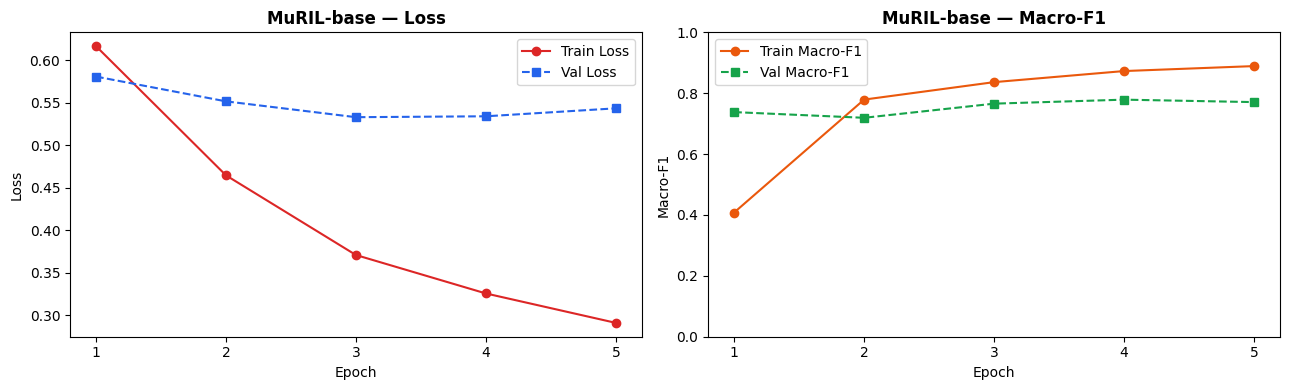

  Tuning decision threshold on validation set...
  Best threshold=0.50  →  Val Macro-F1=0.7788

  MuRIL-base  (threshold=0.50)
               precision    recall  f1-score   support

Non-Clickbait       0.85      0.84      0.84      1941
    Clickbait       0.71      0.73      0.72      1047

     accuracy                           0.80      2988
    macro avg       0.78      0.78      0.78      2988
 weighted avg       0.80      0.80      0.80      2988

  ROC-AUC = 0.8666   PR-AUC (Avg. Precision) = 0.7644


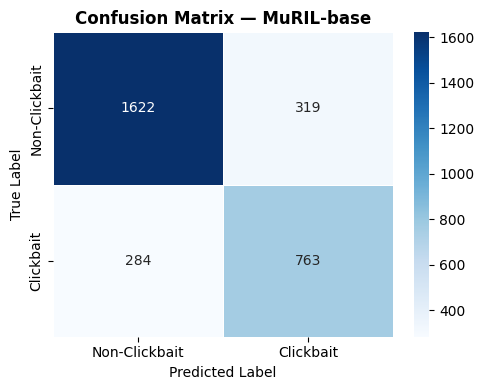

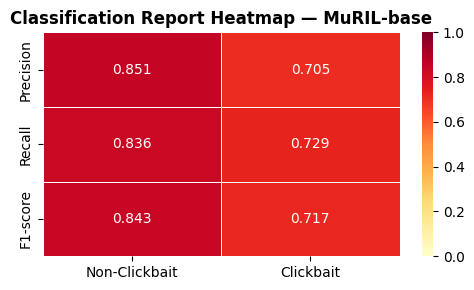

  GPU cleared after MuRIL-base — 15.37 GB free

═════════════════════════════════════════════════════════════════
  MODEL : IndicBERTv2
  ID    : ai4bharat/IndicBERTv2-MLM-Sam-TLM
═════════════════════════════════════════════════════════════════


tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.75M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ⚡ Using nn.DataParallel across 2 GPUs
  Parameters : 278 M
  Batches — Train:294 | Val:33 | Test:94
 Epoch    TrLoss    VlLoss     TrF1     VlF1
--------------------------------------------


model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

     1    0.5702    0.4584   0.6749   0.7588  [130s] ✅ saved
     2    0.4115    0.4359   0.8025   0.7835  [126s] ✅ saved
     3    0.3211    0.4642   0.8553   0.7979  [126s] ✅ saved
     4    0.2417    0.5316   0.8975   0.7934  [126s] (patience 1/3)
     5    0.1908    0.5536   0.9189   0.7990  [126s] ✅ saved

  Best Val Macro-F1 during training: 0.7990


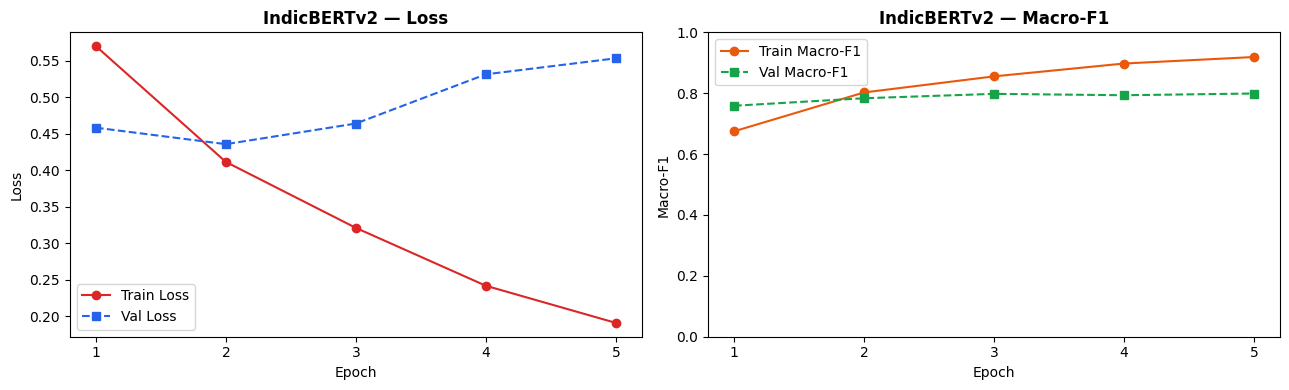

  Tuning decision threshold on validation set...
  Best threshold=0.36  →  Val Macro-F1=0.8098

  IndicBERTv2  (threshold=0.36)
               precision    recall  f1-score   support

Non-Clickbait       0.88      0.84      0.86      1941
    Clickbait       0.73      0.79      0.76      1047

     accuracy                           0.82      2988
    macro avg       0.80      0.82      0.81      2988
 weighted avg       0.83      0.82      0.82      2988

  ROC-AUC = 0.8910   PR-AUC (Avg. Precision) = 0.8173


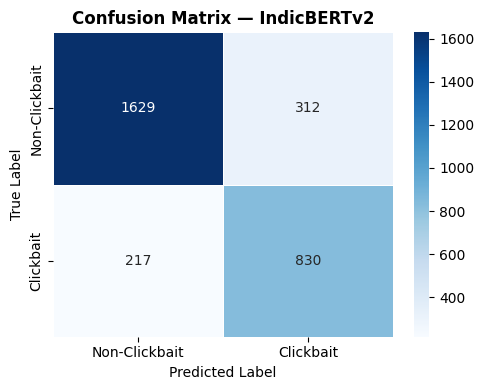

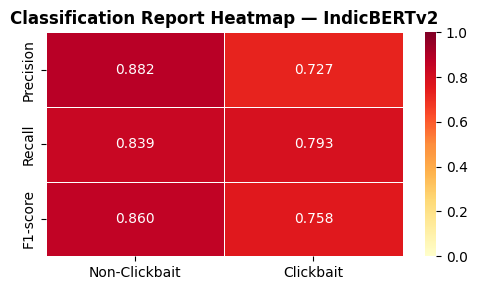

  GPU cleared after IndicBERTv2 — 15.37 GB free

✅ Training complete — 8 models evaluated in 132.9 min


In [21]:
ALL_RESULTS   = []   # will hold one metrics dict per model
ALL_HISTORIES = {}   # name → training history dict
ALL_PROBS     = {}   # name → (all_labels, all_probs)  — for ROC/PR curves
ALL_PREDS     = {}   # name → preds                     — for McNemar's test

_run_t0 = time.time()

for cfg in MODEL_REGISTRY:
    print("\n" + "═"*65)
    print(f"  MODEL : {cfg['name']}")
    print(f"  ID    : {cfg['model_id']}")
    print("═"*65)

    # ── Load tokenizer & model (safe — skips if unavailable) ─────
    try:
        tokenizer  = AutoTokenizer.from_pretrained(cfg["model_id"])
        base_model = AutoModelForSequenceClassification.from_pretrained(
            cfg["model_id"], num_labels=2)
    except Exception as e:
        print(f"  ⚠️  SKIPPED — could not load {cfg['model_id']}")
        print(f"  Reason : {type(e).__name__}: {str(e)[:200]}")
        continue   # skip to next model

    model = wrap_multi_gpu(base_model)
    if isinstance(model, nn.DataParallel):
        print(f"  ⚡ Using nn.DataParallel across {N_GPUS} GPUs")

    n_params = sum(p.numel() for p in base_model.parameters()) / 1e6
    print(f"  Parameters : {n_params:.0f} M")

    # ── Build DataLoaders ─────────────────────────────────────────
    tr_loader, vl_loader, ts_loader = make_loaders(
        X_tr, y_tr, X_vl, y_vl, X_ts, y_ts,
        tokenizer, cfg,
        use_weighted_sampler=cfg.get("use_wrs", False),
    )
    print(f"  Batches — Train:{len(tr_loader)} | Val:{len(vl_loader)} | Test:{len(ts_loader)}")

    # ── Train ─────────────────────────────────────────────────────
    history, best_vl_f1 = train_model(
        model, tr_loader, vl_loader, cfg,
        save_name=cfg["save_name"],
        y_train=y_tr,
        loss_type=cfg["loss_type"],
    )
    ALL_HISTORIES[cfg["name"]] = history
    print(f"\n  Best Val Macro-F1 during training: {best_vl_f1:.4f}")

    # ── Plot training curves ──────────────────────────────────────
    plot_training_curves(
        history, cfg["name"],
        save_path=f"{SAVE_DIR}/fig_training_{cfg['save_name']}.png",
    )

    # ── Threshold tuning on validation set ───────────────────────
    print("  Tuning decision threshold on validation set...")
    best_thr, _, _ = tune_threshold(
        model, vl_loader,
        model_path=f"{SAVE_DIR}/best_{cfg['save_name']}.pt",
    )

    # ── Test-set evaluation ───────────────────────────────────────
    metrics, probs, labels, preds = evaluate_model(
        model, ts_loader,
        model_path=f"{SAVE_DIR}/best_{cfg['save_name']}.pt",
        title=cfg["name"],
        threshold=best_thr,
    )
    ALL_PROBS[cfg["name"]] = (labels, probs)
    ALL_PREDS[cfg["name"]] = preds

    # Augment metrics with config info
    metrics.update({
        "model_id"   : cfg["model_id"],
        "lr"         : cfg["lr"],
        "batch_size" : cfg["batch_size"],
        "epochs_run" : len(history["tr_loss"]),
        "max_len"    : cfg["max_len"],
        "loss_type"  : cfg["loss_type"],
        "best_val_f1": best_vl_f1,
        "n_params_m" : n_params,
    })
    ALL_RESULTS.append(metrics)

    # ── Confusion matrix & heatmap ────────────────────────────────
    plot_confusion_matrix(
        metrics["confusion_matrix"], cfg["name"],
        save_path=f"{SAVE_DIR}/fig_cm_{cfg['save_name']}.png",
    )
    plot_classification_heatmap(
        metrics, cfg["name"],
        save_path=f"{SAVE_DIR}/fig_heatmap_{cfg['save_name']}.png",
    )

    # ── Release memory ────────────────────────────────────────────
    del model, base_model, tokenizer, tr_loader, vl_loader, ts_loader
    gpu_clear(f"after {cfg['name']} ")

elapsed_total = (time.time() - _run_t0) / 60
print(f"\n✅ Training complete — {len(ALL_RESULTS)} models evaluated in {elapsed_total:.1f} min")
if len(ALL_RESULTS) < len(MODEL_REGISTRY):
    skipped = len(MODEL_REGISTRY) - len(ALL_RESULTS)
    print(f"  ⚠️  {skipped} model(s) were skipped (see BLOCKED above)")


## 📐 Section 8 — Classical ML Baselines (TF-IDF)

For a research-quality comparison, it's standard practice to show how much
the transformer models actually improve over simple, fast, non-neural
baselines. These take seconds to train on CPU and give useful context for
the final results table and plots.


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# FIX: scikit-learn's default token_pattern r"(?u)\b\w\w+\b" treats Bangla vowel signs (ি, ু, ে …) and the
# virama (্) as NON-word characters, so every Bangla word was being chopped into meaningless fragments.
# This pattern keeps whole Bangla words (U+0980–U+09FF) together with ordinary \w tokens.
BN_TOKEN_PATTERN = r"(?u)[\u0980-\u09FF\w]{2,}"
tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), sublinear_tf=True,
                        token_pattern=BN_TOKEN_PATTERN)
Xtr_tfidf = tfidf.fit_transform(X_tr)
Xts_tfidf = tfidf.transform(X_ts)

classical_models = {
    "TF-IDF + LogisticRegression": LogisticRegression(
        max_iter=2000, class_weight="balanced", C=2.0, random_state=SEED),
    "TF-IDF + LinearSVC": LinearSVC(
        class_weight="balanced", C=1.0, random_state=SEED),
}

for name, clf in classical_models.items():
    t0 = time.time()
    clf.fit(Xtr_tfidf, y_tr)
    preds = clf.predict(Xts_tfidf)

    # Decision scores for ROC/PR curves — LogisticRegression has predict_proba,
    # LinearSVC only has decision_function (both work fine with roc_auc_score /
    # average_precision_score, which accept arbitrary monotonic scores).
    if hasattr(clf, "predict_proba"):
        scores = clf.predict_proba(Xts_tfidf)[:, 1]
    else:
        scores = clf.decision_function(Xts_tfidf)

    acc  = accuracy_score(y_ts, preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_ts, preds, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
        y_ts, preds, average="weighted", zero_division=0)
    per_class = classification_report(y_ts, preds, target_names=LABEL_NAMES,
                                       output_dict=True, zero_division=0)
    cm = confusion_matrix(y_ts, preds)
    try:
        roc_auc = roc_auc_score(y_ts, scores)
        pr_auc  = average_precision_score(y_ts, scores)
    except ValueError:
        roc_auc, pr_auc = float("nan"), float("nan")

    print(f"\n{'='*60}\n  {name}\n{'='*60}")
    print(classification_report(y_ts, preds, target_names=LABEL_NAMES, zero_division=0))
    print(f"  ROC-AUC={roc_auc:.4f}  PR-AUC={pr_auc:.4f}  ({time.time()-t0:.1f}s)")

    ALL_RESULTS.append(dict(
        title=name, threshold=0.5, accuracy=acc,
        macro_precision=prec_macro, macro_recall=rec_macro, macro_f1=f1_macro,
        weighted_precision=prec_w, weighted_recall=rec_w, weighted_f1=f1_w,
        cb_precision=per_class["Clickbait"]["precision"],
        cb_recall=per_class["Clickbait"]["recall"],
        cb_f1=per_class["Clickbait"]["f1-score"],
        nc_precision=per_class["Non-Clickbait"]["precision"],
        nc_recall=per_class["Non-Clickbait"]["recall"],
        nc_f1=per_class["Non-Clickbait"]["f1-score"],
        roc_auc=roc_auc, pr_auc=pr_auc,
        confusion_matrix=cm,
        model_id="scikit-learn (TF-IDF)", lr="—", batch_size="—",
        epochs_run="—", max_len="—", loss_type="—", best_val_f1=f1_macro,
        n_params_m=0,
    ))
    ALL_PROBS[name] = (list(y_ts), list(scores))
    ALL_PREDS[name] = list(preds)

print("\n✅ Classical baselines done")



  TF-IDF + LogisticRegression
               precision    recall  f1-score   support

Non-Clickbait       0.83      0.79      0.81      1941
    Clickbait       0.64      0.69      0.66      1047

     accuracy                           0.76      2988
    macro avg       0.73      0.74      0.74      2988
 weighted avg       0.76      0.76      0.76      2988

  ROC-AUC=0.8166  PR-AUC=0.7151  (0.8s)

  TF-IDF + LinearSVC
               precision    recall  f1-score   support

Non-Clickbait       0.81      0.80      0.81      1941
    Clickbait       0.64      0.66      0.65      1047

     accuracy                           0.75      2988
    macro avg       0.73      0.73      0.73      2988
 weighted avg       0.75      0.75      0.75      2988

  ROC-AUC=0.8087  PR-AUC=0.7055  (0.1s)

✅ Classical baselines done


## 🤝 Section 9 — Logit-Averaging Ensemble (Top-3 Transformer Models)

Averages the predicted probabilities of the top-3 transformer models
(by validation Macro-F1) and re-evaluates on the test set. Classical
baselines and TigerLLM are excluded from ensembling since they use
fundamentally different scoring mechanisms.


Top-3 models selected for ensembling (by validation Macro-F1):
  • BanglaBERT (csebuetnlp)  (val Macro-F1=0.8073)
  • BanglaBERT-large (csebuetnlp)  (val Macro-F1=0.8060)
  • IndicBERTv2  (val Macro-F1=0.7990)

  Re-running inference for ensemble member: BanglaBERT (csebuetnlp)


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 15.37 GB free

  Re-running inference for ensemble member: BanglaBERT-large (csebuetnlp)


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 15.37 GB free

  Re-running inference for ensemble member: IndicBERTv2


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 15.37 GB free

  Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)
               precision    recall  f1-score   support

Non-Clickbait       0.88      0.86      0.87      1941
    Clickbait       0.75      0.77      0.76      1047

     accuracy                           0.83      2988
    macro avg       0.81      0.82      0.81      2988
 weighted avg       0.83      0.83      0.83      2988

  ROC-AUC=0.9033  PR-AUC=0.8392


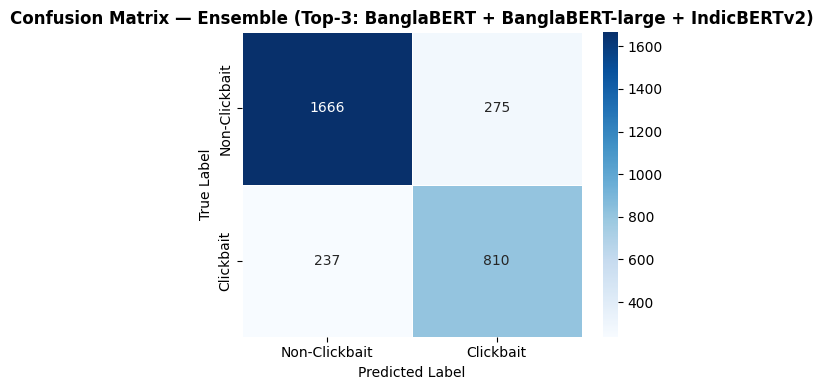

In [23]:
N_ENSEMBLE = 3

# Only consider models that are actually in MODEL_REGISTRY (i.e. transformer
# encoders trained in Section 7) — this excludes classical baselines from
# being (silently) selected here.
registry_names   = {m["name"] for m in MODEL_REGISTRY}
transformer_rows = [r for r in ALL_RESULTS if r["title"] in registry_names]
top_rows         = sorted(transformer_rows, key=lambda r: r["best_val_f1"], reverse=True)[:N_ENSEMBLE]
top_names        = [r["title"] for r in top_rows]

print(f"Top-{N_ENSEMBLE} models selected for ensembling (by validation Macro-F1):")
for r in top_rows:
    print(f"  • {r['title']}  (val Macro-F1={r['best_val_f1']:.4f})")

ensemble_probs_sum = None
ensemble_labels    = None

for cfg in MODEL_REGISTRY:
    if cfg["name"] not in top_names:
        continue
    print(f"\n  Re-running inference for ensemble member: {cfg['name']}")
    try:
        tokenizer  = AutoTokenizer.from_pretrained(cfg["model_id"])
        base_model = AutoModelForSequenceClassification.from_pretrained(
            cfg["model_id"], num_labels=2)
    except Exception as e:
        print(f"  ⚠️  Could not reload {cfg['model_id']} for ensembling — skipping")
        continue

    model = wrap_multi_gpu(base_model)
    _, _, ts_loader = make_loaders(X_tr, y_tr, X_vl, y_vl, X_ts, y_ts, tokenizer, cfg)

    get_base_model(model).load_state_dict(
        torch.load(f"{SAVE_DIR}/best_{cfg['save_name']}.pt", map_location=DEVICE))
    model.eval()

    probs_this, labels_this = [], []
    with torch.no_grad():
        for batch in ts_loader:
            ids  = batch["input_ids"].to(DEVICE, non_blocking=True)
            mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = forward_logits(model, ids, mask)
            probs_this  += torch.softmax(logits.float(), dim=-1)[:, 1].cpu().tolist()
            labels_this += batch["labels"].tolist()

    probs_this = np.array(probs_this)
    if ensemble_probs_sum is None:
        ensemble_probs_sum = probs_this
        ensemble_labels    = labels_this
    else:
        ensemble_probs_sum += probs_this

    del model, base_model, tokenizer, ts_loader
    gpu_clear()

if ensemble_probs_sum is not None:
    ensemble_probs = ensemble_probs_sum / len(top_names)
    ensemble_preds = [1 if p >= 0.5 else 0 for p in ensemble_probs]

    acc  = accuracy_score(ensemble_labels, ensemble_preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        ensemble_labels, ensemble_preds, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
        ensemble_labels, ensemble_preds, average="weighted", zero_division=0)
    per_class = classification_report(ensemble_labels, ensemble_preds,
                                       target_names=LABEL_NAMES,
                                       output_dict=True, zero_division=0)
    cm = confusion_matrix(ensemble_labels, ensemble_preds)
    roc_auc = roc_auc_score(ensemble_labels, ensemble_probs)
    pr_auc  = average_precision_score(ensemble_labels, ensemble_probs)

    ensemble_name = f"Ensemble (Top-{len(top_names)}: " + " + ".join(
        n.split(" (")[0] for n in top_names) + ")"

    print(f"\n{'='*60}\n  {ensemble_name}\n{'='*60}")
    print(classification_report(ensemble_labels, ensemble_preds,
                                 target_names=LABEL_NAMES, zero_division=0))
    print(f"  ROC-AUC={roc_auc:.4f}  PR-AUC={pr_auc:.4f}")

    ALL_RESULTS.append(dict(
        title=ensemble_name, threshold=0.5, accuracy=acc,
        macro_precision=prec_macro, macro_recall=rec_macro, macro_f1=f1_macro,
        weighted_precision=prec_w, weighted_recall=rec_w, weighted_f1=f1_w,
        cb_precision=per_class["Clickbait"]["precision"],
        cb_recall=per_class["Clickbait"]["recall"],
        cb_f1=per_class["Clickbait"]["f1-score"],
        nc_precision=per_class["Non-Clickbait"]["precision"],
        nc_recall=per_class["Non-Clickbait"]["recall"],
        nc_f1=per_class["Non-Clickbait"]["f1-score"],
        roc_auc=roc_auc, pr_auc=pr_auc, confusion_matrix=cm,
        model_id="ensemble", lr="—", batch_size="—", epochs_run="—",
        max_len="—", loss_type="—", best_val_f1=f1_macro, n_params_m=0,
    ))
    ALL_PROBS[ensemble_name] = (ensemble_labels, list(ensemble_probs))
    ALL_PREDS[ensemble_name] = ensemble_preds
    plot_confusion_matrix(cm, ensemble_name, save_path=f"{SAVE_DIR}/fig_cm_ensemble.png")
else:
    print("⚠️  Ensemble skipped — no top models were available to reload.")


## 🐯 Section 10 — TigerLLM (QLoRA Fine-tuning)

**FIX vs. the original notebook:** the original used
`TigerResearch/tigerbot-7b-chat-v3`, which is **TigerBot** — an unrelated
**Chinese** LLM from a different "Tiger" project. It has no connection to
Bangla at all.

This version uses the real Bangla LLM: **[TigerLLM-1B-it](https://huggingface.co/md-nishat-008/TigerLLM-1B-it)**
(Nishat Raihan et al., *"TigerLLM — A Family of Bangla Large Language
Models"*, ACL 2025). At 1B parameters it fine-tunes quickly with QLoRA
even on a single T4, and it's an actually-relevant baseline for a Bangla
NLP paper.


In [24]:
# ── 10.1  Install LoRA / bitsandbytes ─────────────────────────────
from peft import (LoraConfig, get_peft_model, TaskType,
                  PeftModel, prepare_model_for_kbit_training)
from transformers import (AutoModelForCausalLM, BitsAndBytesConfig,
                          TrainingArguments, Trainer, default_data_collator)
print("✅ PEFT / bitsandbytes ready")


def build_training_args(**kwargs):
    """Version-safe TrainingArguments builder.
    `evaluation_strategy` was renamed to `eval_strategy` in newer
    `transformers` releases; this works with either."""
    sig = inspect.signature(TrainingArguments.__init__)
    strategy_val = kwargs.pop("evaluation_strategy", kwargs.pop("eval_strategy", "epoch"))
    if "eval_strategy" in sig.parameters:
        kwargs["eval_strategy"] = strategy_val
    else:
        kwargs["evaluation_strategy"] = strategy_val
    return TrainingArguments(**kwargs)


✅ PEFT / bitsandbytes ready


In [25]:
# ── 10.2  Model config ─────────────────────────────────────────────
TIGER_MODEL_ID = "md-nishat-008/TigerLLM-1B-it"

# TigerLLM-1B-it is a Gemma-3 model.  Gemma-3 is happiest in bf16; T4 (Turing) has no native bf16, so it falls
# back to fp16.  If the pre-flight check in Section 10.5 reports a NaN/inf loss under fp16, set
# TIGER_FORCE_FP32 = True here and re-run from this cell (slower but numerically safe).
TIGER_FORCE_FP32 = False
_cc_major = torch.cuda.get_device_capability()[0] if torch.cuda.is_available() else 0
if TIGER_FORCE_FP32 or not torch.cuda.is_available():
    TIGER_COMPUTE_DTYPE = torch.float32
elif _cc_major >= 8:                         # Ampere or newer → native bf16
    TIGER_COMPUTE_DTYPE = torch.bfloat16
else:                                        # T4 / P100
    TIGER_COMPUTE_DTYPE = torch.float16
TIGER_USE_FP16 = TIGER_COMPUTE_DTYPE == torch.float16
TIGER_USE_BF16 = TIGER_COMPUTE_DTYPE == torch.bfloat16
print(f"TigerLLM compute dtype: {TIGER_COMPUTE_DTYPE}")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=TIGER_COMPUTE_DTYPE,
    bnb_4bit_use_double_quant=True,
)

TIGER_MAX_LEN        = 256   # prompt + answer token budget (the old 96 truncated the label for many rows)
TIGER_MAX_NEW_TOKENS = 12    # "ক্লিকবেইট নয়" needs more than the old 6 new tokens
TIGER_ANSWERS = {1: "ক্লিকবেইট", 0: "ক্লিকবেইট নয়"}

def build_prompt(title):
    return (
        "নিচের বাংলা শিরোনামটি ক্লিকবেইট (Clickbait) নাকি ক্লিকবেইট নয় "
        "(Non-Clickbait) তা নির্ধারণ করুন।\n"
        f"শিরোনাম: {title}\n"
        "উত্তর:"
    )

def build_full_example(title, label):
    return build_prompt(title) + " " + TIGER_ANSWERS[int(label)]


TigerLLM compute dtype: torch.float16


In [26]:
# ── 10.3  Dataset for causal-LM fine-tuning ───────────────────────
class TigerDataset(Dataset):
    """Prompt → answer examples for causal-LM fine-tuning.

    FIXES vs. the previous version:
      • Bangla prompts tokenise to well over 96 tokens; padding="max_length"/truncation at 96 cut the
        answer off for many rows, so the model never saw the label for them.  Now: max_len=256, dynamic
        padding (see tiger_data_collator) and the title is shortened if it ever still overflows.
      • pad_token == eos_token, and every pad-id position was masked from the loss — which also masked the
        real <eos>.  The model therefore never learned to stop, and the later `"নয়" in generation` test could be
        polluted by trailing text.  An explicit <eos> is now appended to the answer and trained on.
      • Loss is computed on the answer tokens only (prompt positions are -100)."""
    def __init__(self, texts, labels, tokenizer, max_len=TIGER_MAX_LEN):
        self.texts, self.labels = list(texts), list(labels)
        self.tokenizer, self.max_len = tokenizer, max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        tok   = self.tokenizer
        title = str(self.texts[idx])
        ans_ids    = tok(" " + TIGER_ANSWERS[int(self.labels[idx])], add_special_tokens=False)["input_ids"] \
                     + [tok.eos_token_id]
        prompt_ids = tok(build_prompt(title), add_special_tokens=True)["input_ids"]
        while len(prompt_ids) + len(ans_ids) > self.max_len and len(title) > 10:
            title      = title[: int(len(title) * 0.85)]
            prompt_ids = tok(build_prompt(title), add_special_tokens=True)["input_ids"]
        return {
            "input_ids": torch.tensor(prompt_ids + ans_ids, dtype=torch.long),
            "labels":    torch.tensor([-100] * len(prompt_ids) + ans_ids, dtype=torch.long),
        }


def tiger_data_collator(batch):
    """Right-pad to the longest sequence in the batch (labels padded with -100)."""
    pad_id = tiger_tokenizer.pad_token_id
    L = max(len(b["input_ids"]) for b in batch)
    ids  = torch.full((len(batch), L), pad_id, dtype=torch.long)
    lab  = torch.full((len(batch), L), -100,   dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n], lab[i, :n], mask[i, :n] = b["input_ids"], b["labels"], 1
    return {"input_ids": ids, "attention_mask": mask, "labels": lab}


In [27]:
# ── 10.4  Load TigerLLM in 4-bit + attach LoRA adapters ───────────
try:
    tiger_tokenizer = AutoTokenizer.from_pretrained(TIGER_MODEL_ID)
    if tiger_tokenizer.pad_token is None:
        tiger_tokenizer.pad_token = tiger_tokenizer.eos_token

    # FIX: device_map="auto" lets accelerate shard the model across BOTH T4s,
    # but Trainer expects a single-device model per process → the "can't
    # train a model loaded in 4-bit on a different device" error.
    # TigerLLM-1B is small enough to fit on one T4, so pin it to one GPU.
    current_device = torch.cuda.current_device() if torch.cuda.is_available() else 0
    tiger_base = AutoModelForCausalLM.from_pretrained(
        TIGER_MODEL_ID, quantization_config=bnb_config,
        device_map={"": current_device},
        attn_implementation="eager")   # Gemma-3 recommends eager attention for training
    tiger_base = prepare_model_for_kbit_training(tiger_base, use_gradient_checkpointing=True)
    tiger_base.enable_input_require_grads()

    lora_config = LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
        task_type=TaskType.CAUSAL_LM,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    )
    tiger_model = get_peft_model(tiger_base, lora_config)
    tiger_model.print_trainable_parameters()
    TIGER_AVAILABLE = True
except Exception as e:
    print(f"⚠️  TigerLLM unavailable — skipping this section. Reason: {type(e).__name__}: {str(e)[:200]}")
    TIGER_AVAILABLE = False

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/197 [00:00<?, ?B/s]

trainable params: 2,981,888 || all params: 1,002,867,840 || trainable%: 0.2973


In [28]:
# ── 10.5  Build train/val datasets & fine-tune ────────────────────
if TIGER_AVAILABLE:
    tiger_tr_ds = TigerDataset(X_tr, y_tr, tiger_tokenizer)
    tiger_vl_ds = TigerDataset(X_vl, y_vl, tiger_tokenizer)

    tiger_args = build_training_args(
        output_dir=f"{SAVE_DIR}/tigerllm_checkpoints",
        # Gemma-3 has a 262k-token vocabulary, so the logits tensor is huge: use a small micro-batch and
        # accumulate to the same effective batch size of 16 (4 x 4).
        per_device_train_batch_size=4,
        per_device_eval_batch_size=4,
        gradient_accumulation_steps=4,
        num_train_epochs=3,
        learning_rate=2e-4,
        weight_decay=0.01,
        warmup_ratio=0.1,
        logging_steps=25,
        evaluation_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        fp16=TIGER_USE_FP16,
        bf16=TIGER_USE_BF16,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        optim="paged_adamw_8bit",
        remove_unused_columns=False,
        report_to="none",
        seed=SEED,
    )

    # FIX (CUBLAS_STATUS_EXECUTION_FAILED / "Caught RuntimeError in replica 0"):
    # With 2 visible GPUs the HF Trainer silently wraps the model in torch.nn.DataParallel. A 4-bit (bitsandbytes)
    # model that is pinned to ONE device (Section 10.4) cannot be replicated across GPUs, so the replica crashes
    # inside lm_head.  Force the Trainer to treat this as single-GPU training.
    _ = tiger_args.device            # make sure the Trainer's device setup has run
    tiger_args._n_gpu = 1

    tiger_trainer = Trainer(
        model=tiger_model,
        args=tiger_args,
        train_dataset=tiger_tr_ds,
        eval_dataset=tiger_vl_ds,
        data_collator=tiger_data_collator,
    )
    assert tiger_trainer.args.n_gpu == 1, "Trainer still sees >1 GPU — DataParallel would be re-enabled"

    # Pre-flight: one forward/backward-free pass to make sure the loss is finite under this precision
    # (Gemma-3 can overflow in fp16) — fails fast with a clear message instead of 40 minutes into training.
    tiger_model.train()
    _probe = tiger_data_collator([tiger_tr_ds[k] for k in range(min(4, len(tiger_tr_ds)))])
    _probe = {k: v.to(tiger_model.device) for k, v in _probe.items()}
    with torch.autocast("cuda", dtype=TIGER_COMPUTE_DTYPE, enabled=TIGER_COMPUTE_DTYPE != torch.float32):
        _probe_loss = tiger_model(**_probe).loss
    print(f"Pre-flight loss: {_probe_loss.item():.4f}  (dtype {TIGER_COMPUTE_DTYPE})")
    if not torch.isfinite(_probe_loss):
        raise RuntimeError("Non-finite loss in the pre-flight check — set TIGER_FORCE_FP32 = True in Section 10.2, "
                           "re-run Sections 10.2-10.4, then run this cell again.")
    del _probe, _probe_loss
    gc.collect(); torch.cuda.empty_cache()

    print("🐯 Fine-tuning TigerLLM-1B-it with QLoRA ...")
    tiger_trainer.train()
    tiger_model.save_pretrained(f"{SAVE_DIR}/tigerllm_lora_adapter")
    print("✅ TigerLLM fine-tuning complete — LoRA adapter saved")
else:
    print("Skipped fine-tuning (model unavailable).")


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Pre-flight loss: 2.9142  (dtype torch.float16)
🐯 Fine-tuning TigerLLM-1B-it with QLoRA ...


Epoch,Training Loss,Validation Loss
1,0.098500,0.117159
2,0.093000,0.089824
3,0.066400,0.093594


✅ TigerLLM fine-tuning complete — LoRA adapter saved


In [29]:
# ── 10.5b  Persist TigerLLM's Trainer log history before cleanup ──
# (Needed later for a real fine-tuning loss curve — Section 19 / Audit Item 1.
#  Captured here, immediately after training, because tiger_trainer is
#  deleted for GPU memory right after evaluation in the next cell.)
if TIGER_AVAILABLE:
    tiger_log_history = tiger_trainer.state.log_history
    with open(f"{SAVE_DIR}/tigerllm_log_history.json", "w", encoding="utf-8") as f:
        json.dump(tiger_log_history, f, indent=2)
    print(f"✅ Saved TigerLLM Trainer log history ({len(tiger_log_history)} logged entries)")
else:
    tiger_log_history = []
    print("Skipped (TigerLLM unavailable).")

✅ Saved TigerLLM Trainer log history (74 logged entries)


The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


  Inference on 2988 test titles took 1448s
               precision    recall  f1-score   support

Non-Clickbait       0.82      0.87      0.85      1941
    Clickbait       0.74      0.65      0.69      1047

     accuracy                           0.80      2988
    macro avg       0.78      0.76      0.77      2988
 weighted avg       0.79      0.80      0.79      2988



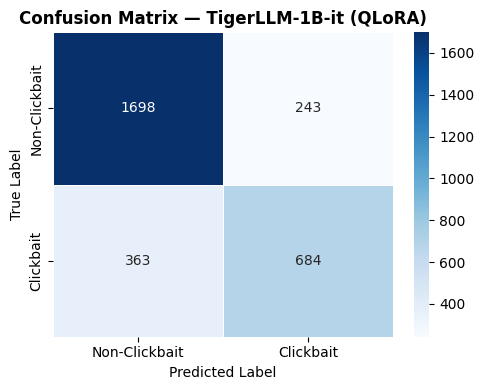

  GPU cleared after TigerLLM — 14.15 GB free


In [30]:
# ── 10.6  Inference & evaluation on test set ──────────────────────
if TIGER_AVAILABLE:
    tiger_model.eval()
    tiger_model.config.use_cache = True
    tiger_preds = []
    t0 = time.time()
    with torch.no_grad():
        for title in X_ts:
            prompt = build_prompt(title)
            inputs = tiger_tokenizer(prompt, return_tensors="pt").to(tiger_model.device)
            out = tiger_model.generate(
                **inputs, max_new_tokens=TIGER_MAX_NEW_TOKENS, do_sample=False,
                pad_token_id=tiger_tokenizer.pad_token_id,
                eos_token_id=tiger_tokenizer.eos_token_id,
                use_cache=True)   # the Trainer switched the config to use_cache=False for gradient checkpointing
            gen_text = tiger_tokenizer.decode(
                out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
            gen_text = gen_text.splitlines()[0] if gen_text else gen_text   # answer = first line only
            # "ক্লিকবেইট নয়" (non-clickbait) contains "নয়"; plain "ক্লিকবেইট" = clickbait
            pred = 0 if "নয়" in gen_text else 1
            tiger_preds.append(pred)
    print(f"  Inference on {len(X_ts)} test titles took {time.time()-t0:.0f}s")

    acc  = accuracy_score(y_ts, tiger_preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_ts, tiger_preds, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
        y_ts, tiger_preds, average="weighted", zero_division=0)
    per_class = classification_report(y_ts, tiger_preds, target_names=LABEL_NAMES,
                                       output_dict=True, zero_division=0)
    cm = confusion_matrix(y_ts, tiger_preds)

    print(classification_report(y_ts, tiger_preds, target_names=LABEL_NAMES, zero_division=0))

    ALL_RESULTS.append(dict(
        title="TigerLLM-1B-it (QLoRA)", threshold="—", accuracy=acc,
        macro_precision=prec_macro, macro_recall=rec_macro, macro_f1=f1_macro,
        weighted_precision=prec_w, weighted_recall=rec_w, weighted_f1=f1_w,
        cb_precision=per_class["Clickbait"]["precision"],
        cb_recall=per_class["Clickbait"]["recall"],
        cb_f1=per_class["Clickbait"]["f1-score"],
        nc_precision=per_class["Non-Clickbait"]["precision"],
        nc_recall=per_class["Non-Clickbait"]["recall"],
        nc_f1=per_class["Non-Clickbait"]["f1-score"],
        roc_auc=float("nan"), pr_auc=float("nan"),  # generation-based: no continuous score
        confusion_matrix=cm,
        model_id=TIGER_MODEL_ID, lr=2e-4, batch_size=16, epochs_run=3,
        max_len=TIGER_MAX_LEN, loss_type="causal-lm", best_val_f1=f1_macro, n_params_m=1000,
    ))
    ALL_PREDS["TigerLLM-1B-it (QLoRA)"] = tiger_preds
    plot_confusion_matrix(cm, "TigerLLM-1B-it (QLoRA)",
                          save_path=f"{SAVE_DIR}/fig_cm_tigerllm.png")

    del tiger_model, tiger_base, tiger_tokenizer, tiger_trainer
    gpu_clear("after TigerLLM ")
else:
    print("Skipped evaluation (model unavailable).")


## 📈 Section 11 — Comparative Visualizations

In [31]:
# ── 11.1  Build summary DataFrame ────────────────────────────────
rows = []
for r in ALL_RESULTS:
    rows.append({
        "Model"              : r["title"],
        "Accuracy"           : round(r["accuracy"],    4),
        "Macro-F1"           : round(r["macro_f1"],    4),
        "Weighted-F1"        : round(r["weighted_f1"], 4),
        "Macro Precision"    : round(r["macro_precision"], 4),
        "Macro Recall"       : round(r["macro_recall"],    4),
        "CB Precision"       : round(r["cb_precision"],    4),
        "CB Recall"          : round(r["cb_recall"],       4),
        "CB F1"              : round(r["cb_f1"],           4),
        "NC Precision"       : round(r["nc_precision"],    4),
        "NC Recall"          : round(r["nc_recall"],       4),
        "NC F1"              : round(r["nc_f1"],           4),
        "ROC-AUC"            : round(r["roc_auc"], 4) if not pd.isna(r["roc_auc"]) else np.nan,
        "PR-AUC"             : round(r["pr_auc"],  4) if not pd.isna(r["pr_auc"])  else np.nan,
    })

results_df = pd.DataFrame(rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print(results_df.to_string(index=False))


                                                        Model  Accuracy  Macro-F1  Weighted-F1  Macro Precision  Macro Recall  CB Precision  CB Recall  CB F1  NC Precision  NC Recall  NC F1  ROC-AUC  PR-AUC
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)    0.8286    0.8133       0.8293           0.8110        0.8160        0.7465     0.7736 0.7598        0.8755     0.8583 0.8668   0.9033  0.8392
                                                  IndicBERTv2    0.8230    0.8093       0.8246           0.8046        0.8160        0.7268     0.7927 0.7583        0.8824     0.8393 0.8603   0.8910  0.8173
                                            XLM-RoBERTa-large    0.8220    0.8085       0.8237           0.8036        0.8157        0.7241     0.7947 0.7577        0.8831     0.8367 0.8593   0.8911  0.8295
                                BanglaBERT-large (csebuetnlp)    0.8116    0.8005       0.8146           0.7946        0.8141        0.6955     0.8223 0.7536        0.8937 

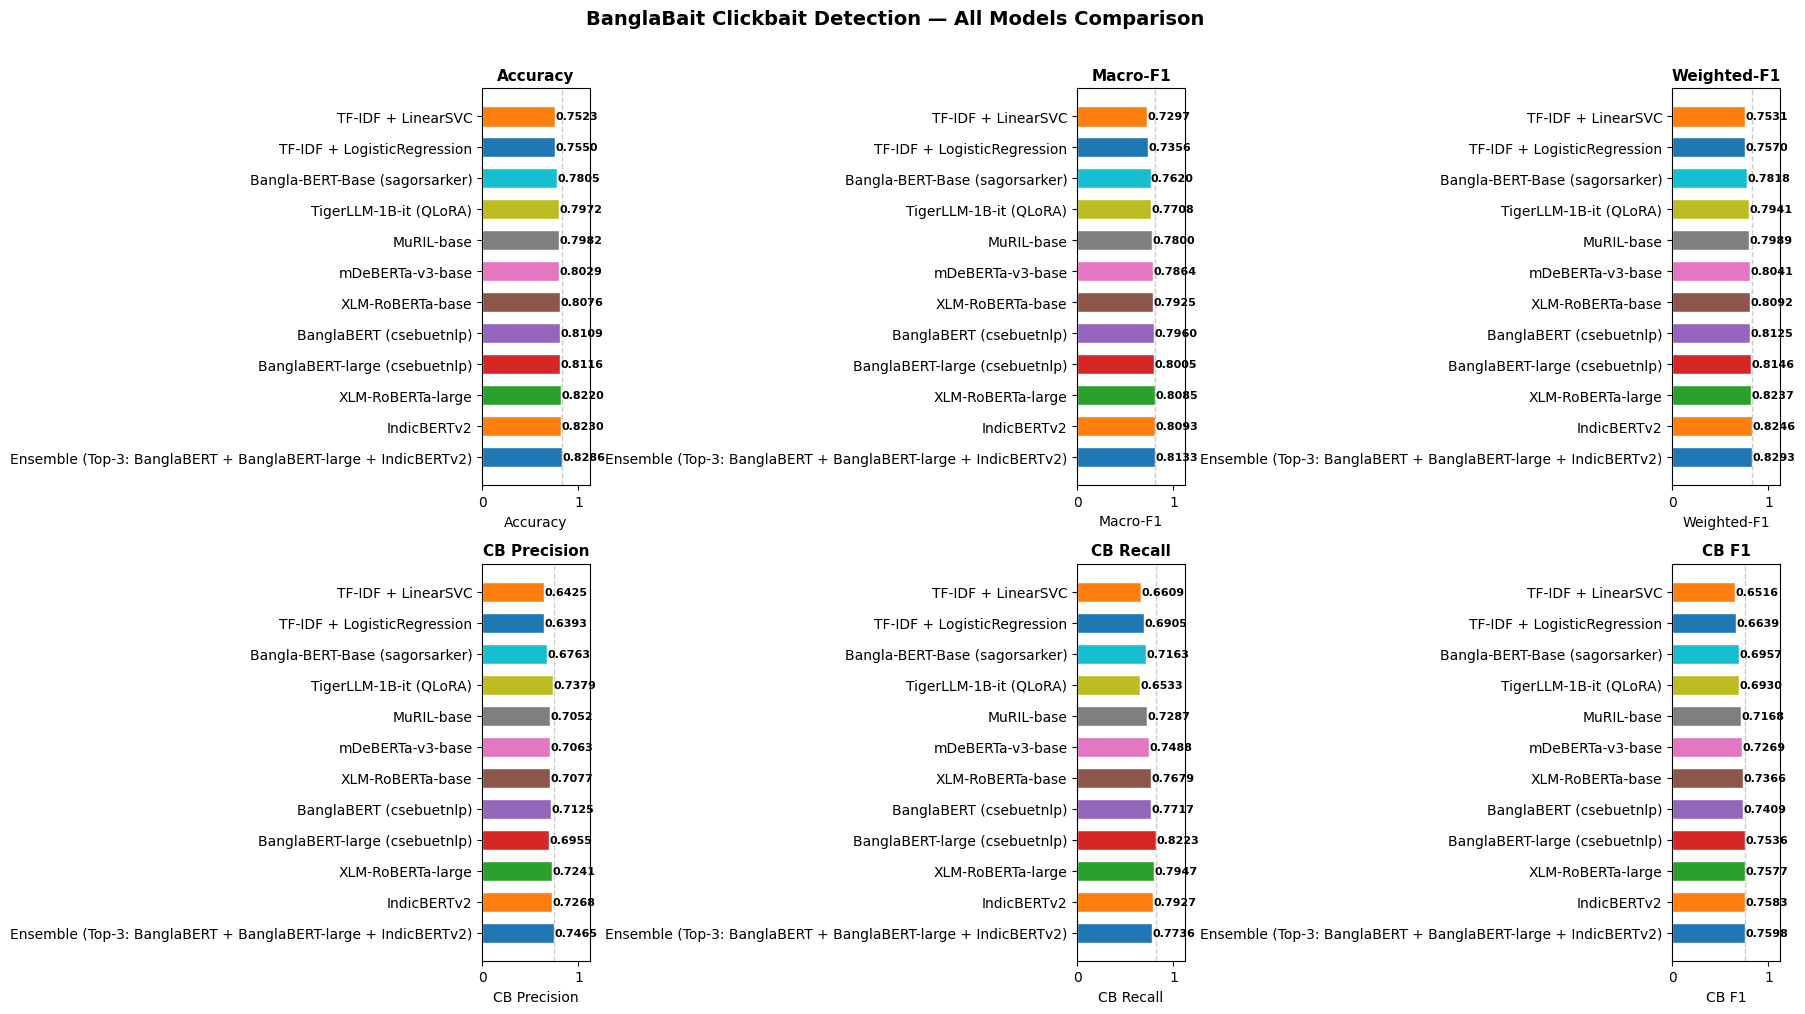

In [32]:
# ── 11.2  Overall comparison bar charts ──────────────────────────
metrics_to_plot = ["Accuracy", "Macro-F1", "Weighted-F1",
                   "CB Precision", "CB Recall", "CB F1"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
palette = sns.color_palette("tab10", n_colors=len(results_df))

for ax, metric in zip(axes, metrics_to_plot):
    bars = ax.barh(results_df["Model"], results_df[metric],
                   color=palette, edgecolor="white", height=0.65)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel(metric, fontsize=10)
    ax.set_title(metric, fontsize=11, fontweight="bold")
    ax.axvline(x=results_df[metric].max(), color="gray",
               linestyle="--", alpha=0.4, linewidth=1)
    for bar, val in zip(bars, results_df[metric]):
        ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                f"{val:.4f}", va="center", fontsize=8, fontweight="bold")

plt.suptitle("BanglaBait Clickbait Detection — All Models Comparison",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_10_comparison_all_metrics.png", dpi=150, bbox_inches="tight")
plt.show()


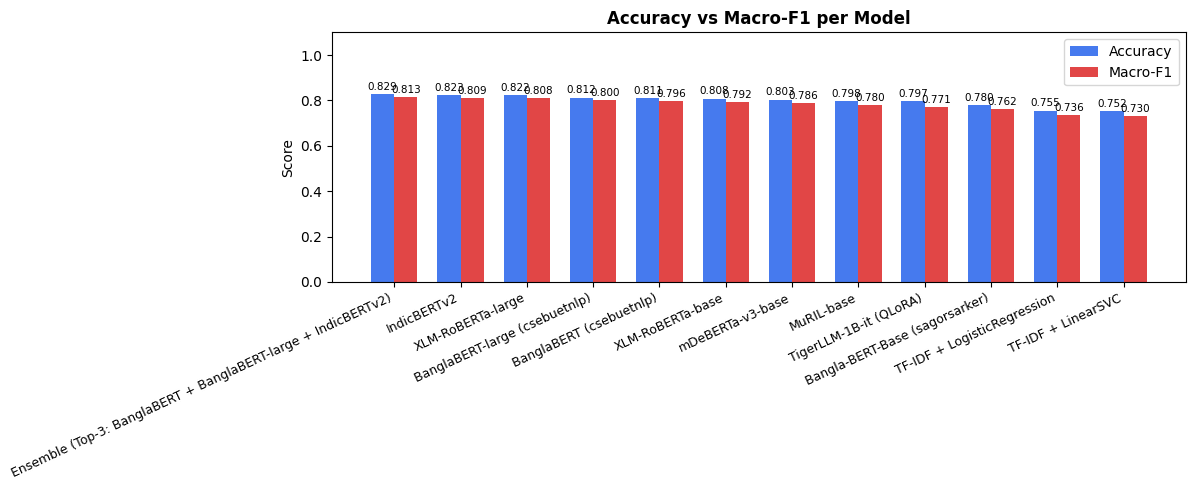

In [33]:
# ── 11.3  Grouped bar: Macro-F1 vs Accuracy side-by-side ─────────
fig, ax = plt.subplots(figsize=(12, 5))
x   = np.arange(len(results_df))
w   = 0.35
b1  = ax.bar(x - w/2, results_df["Accuracy"], width=w,
             label="Accuracy", color="#2563EB", alpha=0.85)
b2  = ax.bar(x + w/2, results_df["Macro-F1"], width=w,
             label="Macro-F1", color="#DC2626", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=25, ha="right", fontsize=9)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Accuracy vs Macro-F1 per Model", fontweight="bold", fontsize=12)
ax.legend()
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=7.5)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_11_accuracy_vs_macroF1.png", dpi=150, bbox_inches="tight")
plt.show()


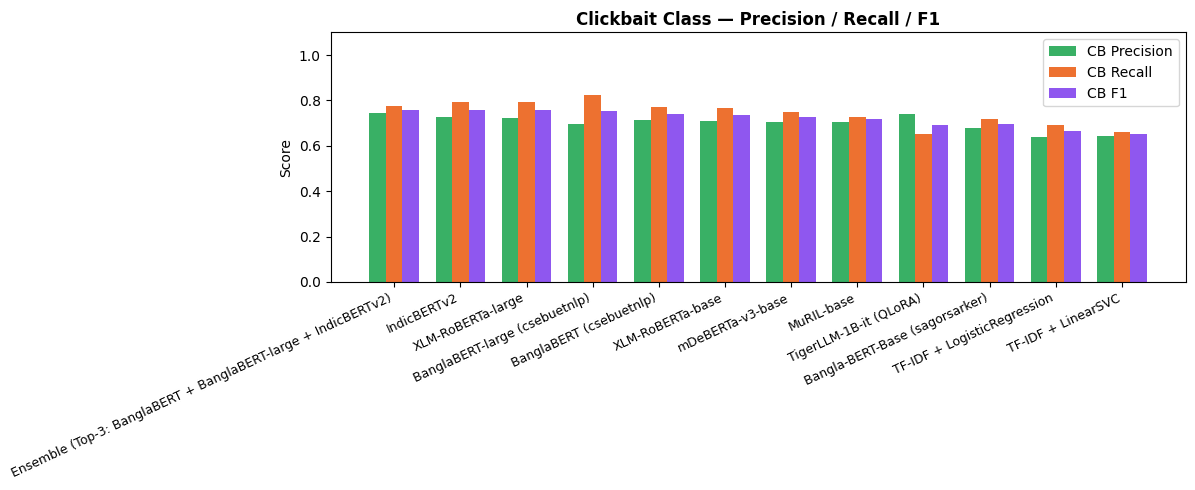

In [34]:
# ── 11.4  Clickbait class: precision / recall / F1 comparison ────
fig, ax = plt.subplots(figsize=(12, 5))
x  = np.arange(len(results_df))
w  = 0.25
ax.bar(x - w,   results_df["CB Precision"], width=w,
       label="CB Precision", color="#16A34A", alpha=0.85)
ax.bar(x,        results_df["CB Recall"],    width=w,
       label="CB Recall",    color="#EA580C", alpha=0.85)
ax.bar(x + w,   results_df["CB F1"],        width=w,
       label="CB F1",        color="#7C3AED", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=25, ha="right", fontsize=9)
ax.set_ylim(0, 1.1); ax.set_ylabel("Score")
ax.set_title("Clickbait Class — Precision / Recall / F1", fontweight="bold", fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_12_clickbait_prf.png", dpi=150, bbox_inches="tight")
plt.show()


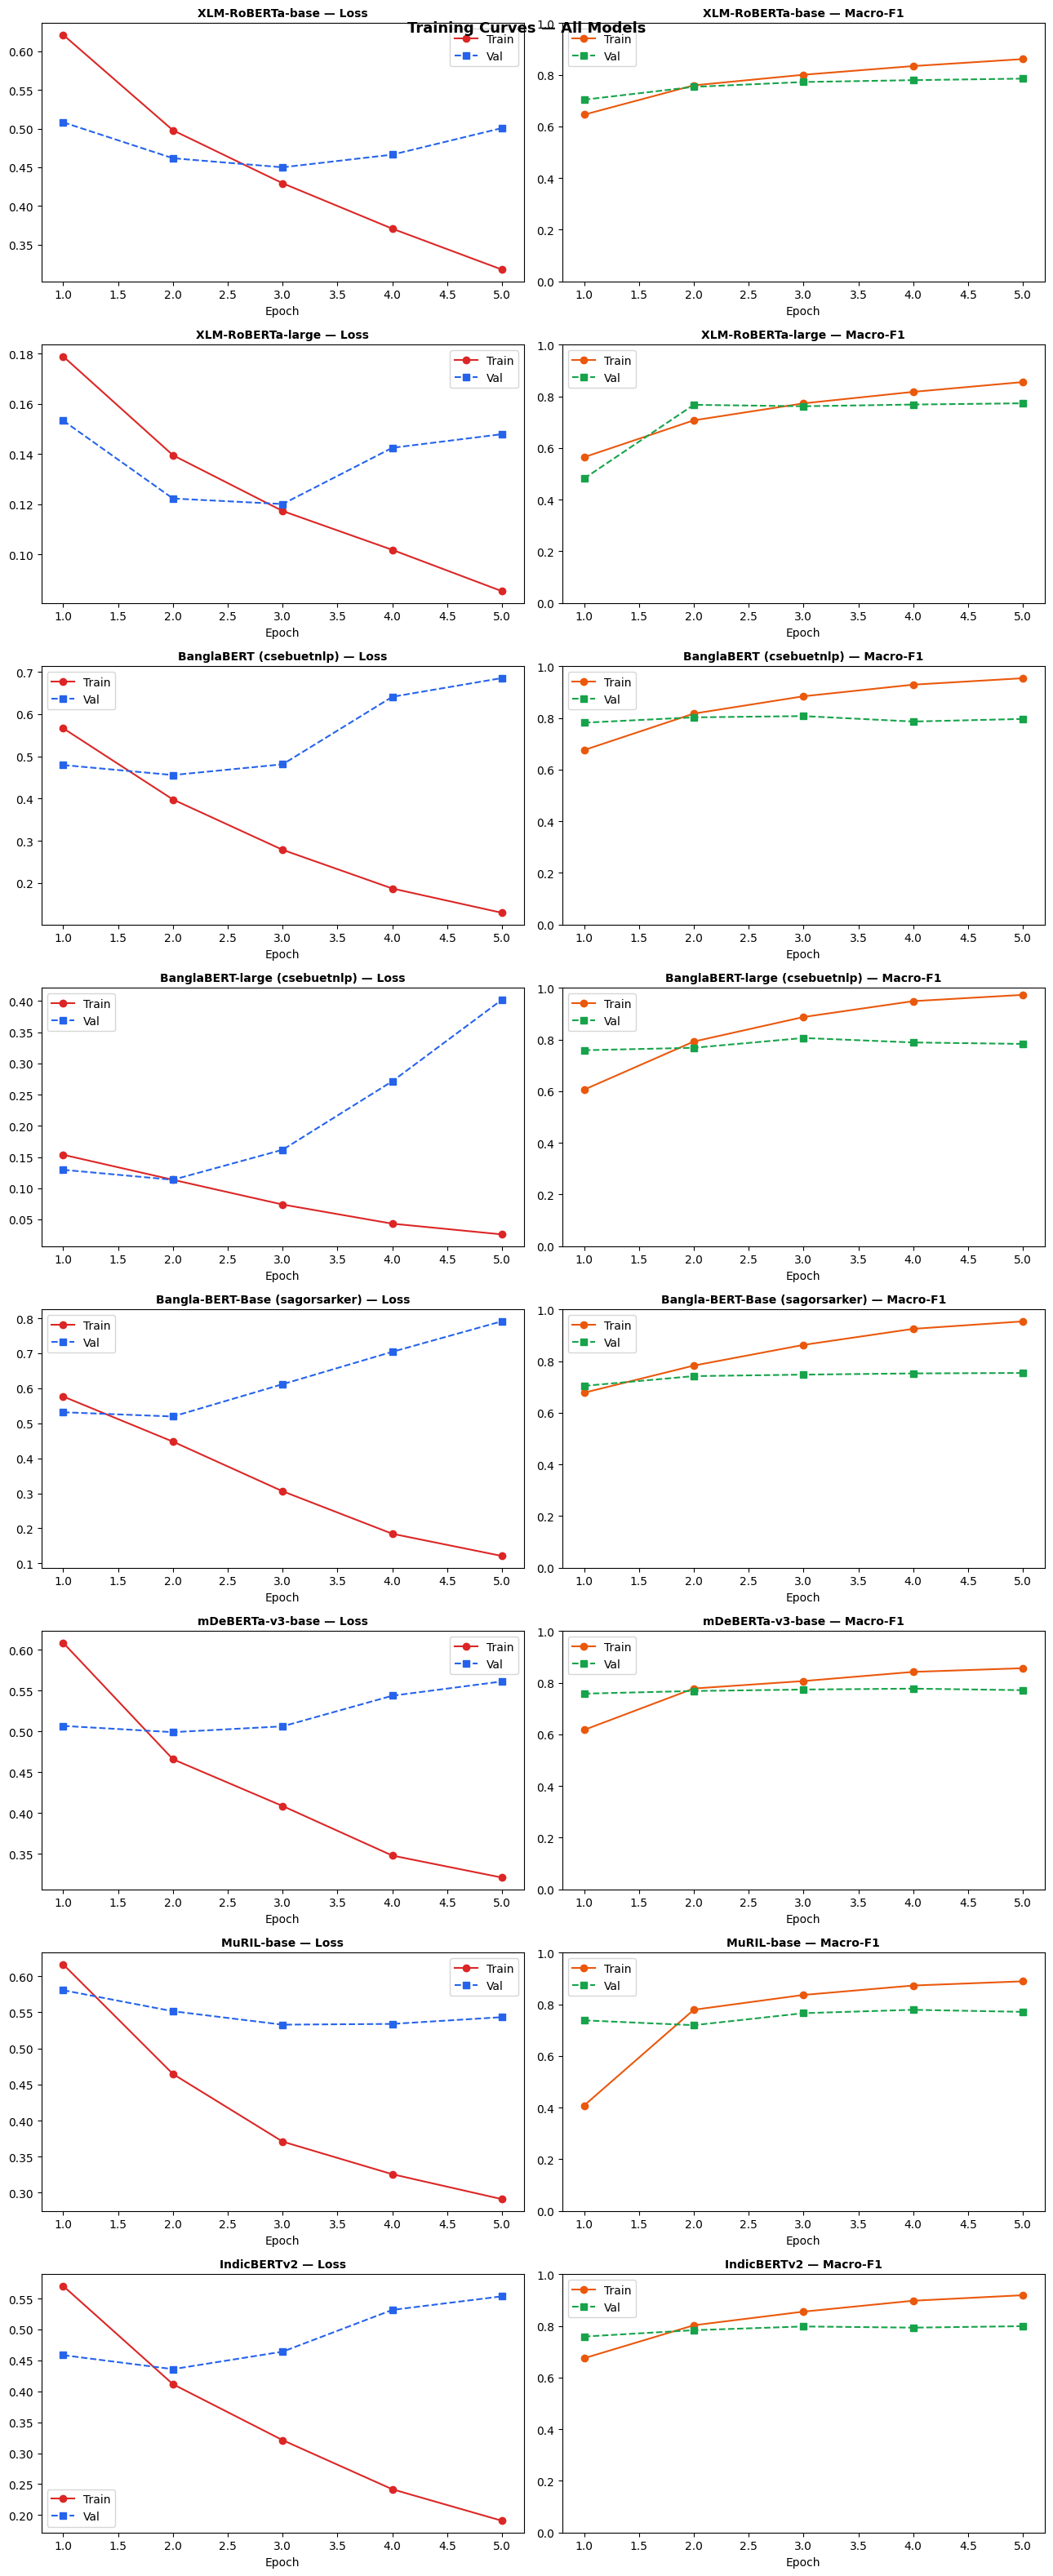

In [35]:
# ── 11.5  All training curves on one figure ───────────────────────
n_models = len(ALL_HISTORIES)
if n_models > 0:
    fig, axes = plt.subplots(n_models, 2, figsize=(13, 4 * n_models))
    if n_models == 1:
        axes = [axes]

    for ax_row, (model_name, history) in zip(axes, ALL_HISTORIES.items()):
        epochs = range(1, len(history["tr_loss"]) + 1)
        ax_row[0].plot(epochs, history["tr_loss"], "o-", color="#DC2626", label="Train")
        ax_row[0].plot(epochs, history["vl_loss"], "s--", color="#2563EB", label="Val")
        ax_row[0].set_title(f"{model_name} — Loss", fontsize=10, fontweight="bold")
        ax_row[0].set_xlabel("Epoch"); ax_row[0].legend()

        ax_row[1].plot(epochs, history["tr_f1"], "o-", color="#EA580C", label="Train")
        ax_row[1].plot(epochs, history["vl_f1"], "s--", color="#16A34A", label="Val")
        ax_row[1].set_title(f"{model_name} — Macro-F1", fontsize=10, fontweight="bold")
        ax_row[1].set_xlabel("Epoch"); ax_row[1].set_ylim(0, 1); ax_row[1].legend()

    plt.suptitle("Training Curves — All Models", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/fig_13_all_training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()


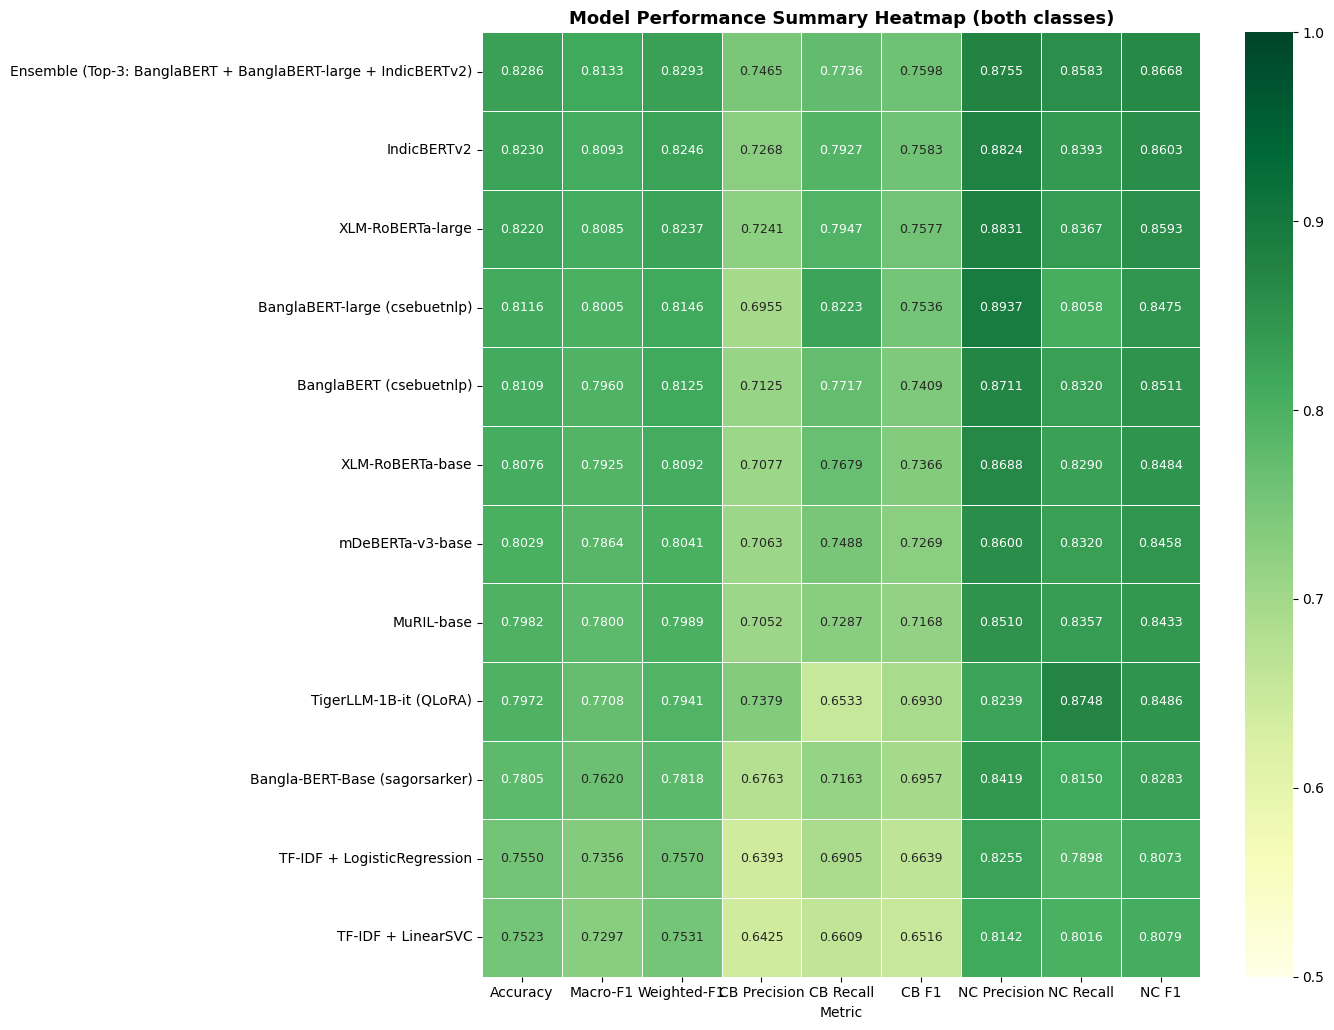

In [36]:
# ── 11.6  Heatmap summary table (all models × all metrics) ───────
heat_cols = ["Accuracy","Macro-F1","Weighted-F1",
             "CB Precision","CB Recall","CB F1",
             "NC Precision","NC Recall","NC F1"]
heat_df   = results_df.set_index("Model")[heat_cols]

fig, ax = plt.subplots(figsize=(14, max(4, len(heat_df) * 0.7 + 2)))
sns.heatmap(heat_df, annot=True, fmt=".4f", cmap="YlGn",
            vmin=0.5, vmax=1.0, linewidths=0.5, ax=ax,
            annot_kws={"size": 9})
ax.set_title("Model Performance Summary Heatmap (both classes)", fontsize=13, fontweight="bold")
ax.set_xlabel("Metric"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_14_summary_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


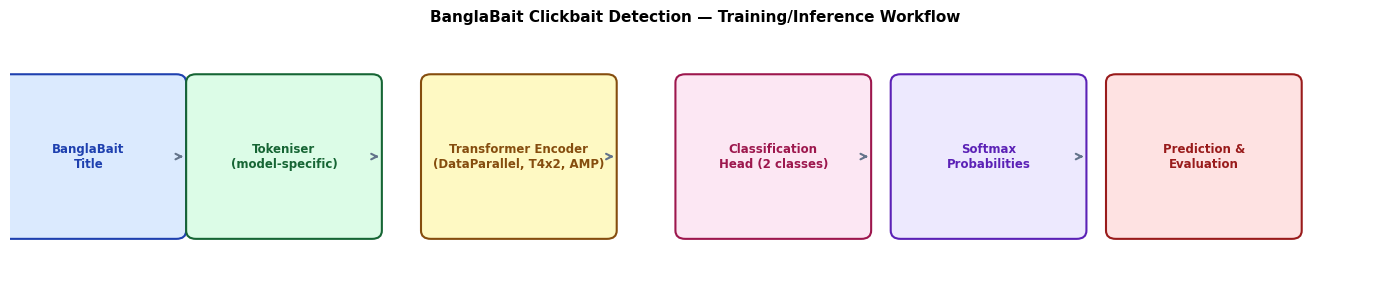

In [37]:
# ── 11.7  Workflow diagram (text-based, matplotlib) ───────────────
from matplotlib.patches import FancyBboxPatch   # FIX: was plt.FancyBboxPatch (doesn't exist)

fig, ax = plt.subplots(figsize=(14, 3))
ax.set_xlim(0, 14); ax.set_ylim(0, 3); ax.axis("off")
ax.set_facecolor("#F8FAFC")

steps = [
    ("BanglaBait\nTitle", 0.8,  "#DBEAFE", "#1E40AF"),
    ("Tokeniser\n(model-specific)", 2.8,  "#DCFCE7", "#166534"),
    ("Transformer Encoder\n(DataParallel, T4x2, AMP)", 5.2,  "#FEF9C3", "#854D0E"),
    ("Classification\nHead (2 classes)", 7.8,  "#FCE7F3", "#9D174D"),
    ("Softmax\nProbabilities", 10.0,  "#EDE9FE", "#5B21B6"),
    ("Prediction &\nEvaluation", 12.2, "#FEE2E2", "#991B1B"),
]

for label, x, bg, fg in steps:
    ax.add_patch(FancyBboxPatch((x - 0.9, 0.6), 1.8, 1.8,
                 boxstyle="round,pad=0.1", facecolor=bg,
                 edgecolor=fg, linewidth=1.5))
    ax.text(x, 1.5, label, ha="center", va="center",
            fontsize=8.5, fontweight="bold", color=fg)
    if x < 12.2:
        ax.annotate("", xy=(x + 1.0, 1.5), xytext=(x + 0.9, 1.5),
                    arrowprops=dict(arrowstyle="->", color="#64748B", lw=1.5))

ax.set_title("BanglaBait Clickbait Detection — Training/Inference Workflow",
             fontsize=11, fontweight="bold", pad=8)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_15_workflow_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

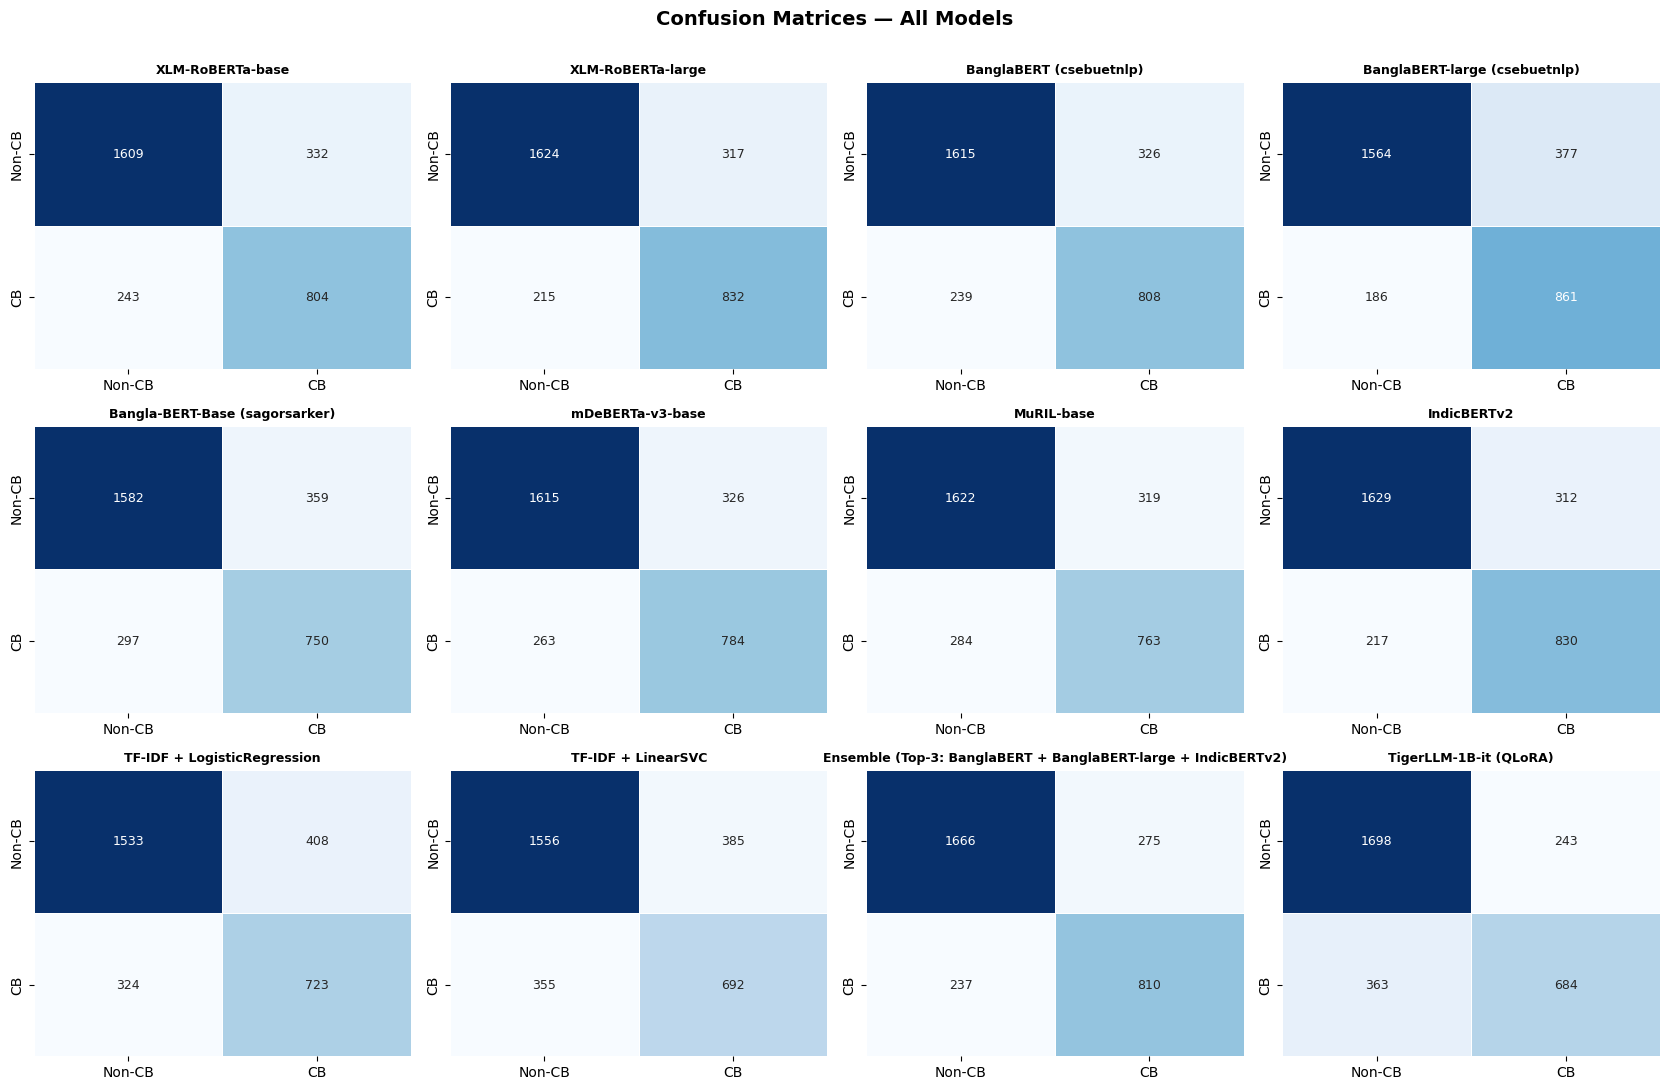

In [38]:
# ── 11.8  NEW: Confusion matrix grid (all models side-by-side) ───
n_models  = len(ALL_RESULTS)
n_cols    = 4
n_rows    = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.6 * n_rows))
axes = np.array(axes).flatten()

for ax, r in zip(axes, ALL_RESULTS):
    sns.heatmap(r["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
                xticklabels=["Non-CB", "CB"], yticklabels=["Non-CB", "CB"],
                cbar=False, ax=ax, linewidths=0.5, annot_kws={"size": 9})
    ax.set_title(r["title"], fontsize=9, fontweight="bold")
    ax.set_xlabel(""); ax.set_ylabel("")

for ax in axes[len(ALL_RESULTS):]:
    ax.axis("off")

plt.suptitle("Confusion Matrices — All Models", fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_16_confusion_matrix_grid.png", dpi=150, bbox_inches="tight")
plt.show()


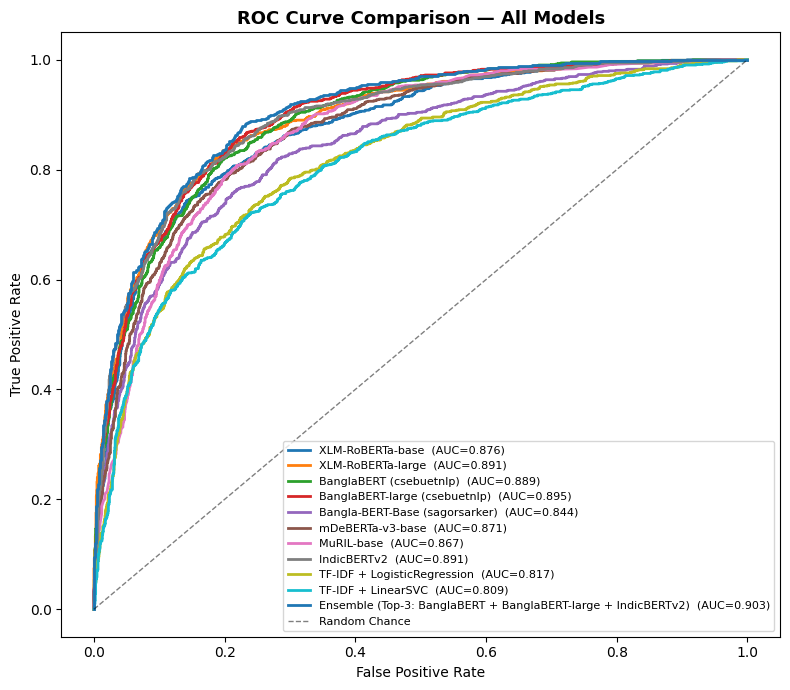

In [39]:
# ── 11.9  NEW: ROC curve comparison (all models with continuous scores) ──
fig, ax = plt.subplots(figsize=(8, 7))
for name, (labels, probs) in ALL_PROBS.items():
    try:
        fpr, tpr, _ = roc_curve(labels, probs)
        auc_val = roc_auc_score(labels, probs)
        ax.plot(fpr, tpr, lw=2, label=f"{name}  (AUC={auc_val:.3f})")
    except ValueError:
        continue
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison — All Models", fontweight="bold", fontsize=13)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_17_roc_curve_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


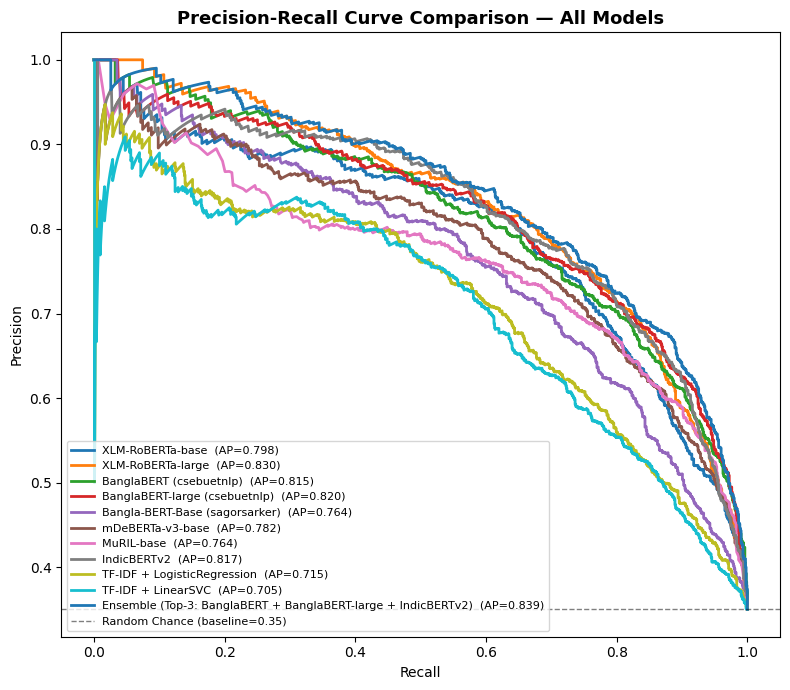

In [40]:
# ── 11.10  NEW: Precision-Recall curve comparison ─────────────────
fig, ax = plt.subplots(figsize=(8, 7))
for name, (labels, probs) in ALL_PROBS.items():
    try:
        prec, rec, _ = precision_recall_curve(labels, probs)
        ap_val = average_precision_score(labels, probs)
        ax.plot(rec, prec, lw=2, label=f"{name}  (AP={ap_val:.3f})")
    except ValueError:
        continue
baseline_rate = np.mean(y_ts)
ax.axhline(y=baseline_rate, color="k", linestyle="--", lw=1, alpha=0.5,
           label=f"Random Chance (baseline={baseline_rate:.2f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve Comparison — All Models", fontweight="bold", fontsize=13)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_18_pr_curve_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


In [41]:
# ── 11.11  NEW: McNemar's statistical significance test ───────────
# Tests whether the top-2 models (by Macro-F1) differ significantly on the
# SAME test examples — important for claiming one model is "better" in a paper.
def mcnemar_test(y_true, pred_a, pred_b):
    y_true  = np.array(y_true)
    pred_a  = np.array(pred_a)
    pred_b  = np.array(pred_b)
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    b_wins = int(np.sum(correct_b & ~correct_a))   # B correct, A wrong
    a_wins = int(np.sum(correct_a & ~correct_b))   # A correct, B wrong
    n = a_wins + b_wins
    if n == 0:
        return 0.0, 1.0, a_wins, b_wins
    stat = (abs(a_wins - b_wins) - 1) ** 2 / n     # with continuity correction
    p    = 1 - chi2.cdf(stat, df=1)
    return stat, p, a_wins, b_wins

top2 = results_df.head(2)["Model"].tolist()
if len(top2) == 2 and all(m in ALL_PREDS for m in top2):
    model_a, model_b = top2
    stat, p, a_wins, b_wins = mcnemar_test(y_ts, ALL_PREDS[model_a], ALL_PREDS[model_b])
    print(f"McNemar's test: '{model_a}' vs '{model_b}'")
    print(f"  Cases only '{model_a}' got right : {a_wins}")
    print(f"  Cases only '{model_b}' got right : {b_wins}")
    print(f"  Chi-square statistic             : {stat:.4f}")
    print(f"  p-value                          : {p:.4f}")
    if p < 0.05:
        print(f"  → Statistically significant difference (p < 0.05) between the two top models.")
    else:
        print(f"  → No statistically significant difference (p ≥ 0.05) — the two top models "
              f"perform comparably on this test set.")
else:
    print("Not enough models with stored predictions to run McNemar's test.")


McNemar's test: 'Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)' vs 'IndicBERTv2'
  Cases only 'Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)' got right : 102
  Cases only 'IndicBERTv2' got right : 85
  Chi-square statistic             : 1.3690
  p-value                          : 0.2420
  → No statistically significant difference (p ≥ 0.05) — the two top models perform comparably on this test set.


## 📋 Section 12 — Final Result Summary Table
Complete comparison of all models with full configuration details, including
ROC-AUC / PR-AUC. This table is saved as a CSV file.


In [42]:
summary_rows = []
for r in ALL_RESULTS:
    summary_rows.append({
        "Model"              : r["title"],
        "Model ID"           : r.get("model_id", "—"),
        "Learning Rate"      : r.get("lr", "—"),
        "Batch Size"         : r.get("batch_size", "—"),
        "Epochs Run"         : r.get("epochs_run", "—"),
        "Max Seq Len"        : r.get("max_len", "—"),
        "Loss Function"      : r.get("loss_type", "—"),
        "Params (M)"         : r.get("n_params_m", 0),
        "Threshold"          : r.get("threshold", 0.5),
        "Accuracy"           : round(r["accuracy"],         4),
        "Macro Precision"    : round(r["macro_precision"],  4),
        "Macro Recall"       : round(r["macro_recall"],     4),
        "Macro-F1"           : round(r["macro_f1"],         4),
        "Weighted-F1"        : round(r["weighted_f1"],      4),
        "CB Precision"       : round(r["cb_precision"],     4),
        "CB Recall"          : round(r["cb_recall"],        4),
        "CB F1"              : round(r["cb_f1"],            4),
        "ROC-AUC"            : round(r["roc_auc"], 4) if not pd.isna(r["roc_auc"]) else np.nan,
        "PR-AUC"             : round(r["pr_auc"],  4) if not pd.isna(r["pr_auc"])  else np.nan,
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Macro-F1", ascending=False)
summary_df.to_csv(f"{SAVE_DIR}/final_results_summary.csv", index=False)
print("✅ Saved to", f"{SAVE_DIR}/final_results_summary.csv")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:.4f}".format)
print("\n" + "="*130)
print("FINAL RESULT SUMMARY — BanglaBait Bangla Clickbait Detection (Title-based Binary Classification)")
print("="*130)
print(summary_df.to_string(index=False))


✅ Saved to /kaggle/working/banglabait_results/final_results_summary.csv

FINAL RESULT SUMMARY — BanglaBait Bangla Clickbait Detection (Title-based Binary Classification)
                                                        Model                          Model ID Learning Rate Batch Size Epochs Run Max Seq Len Loss Function  Params (M) Threshold  Accuracy  Macro Precision  Macro Recall  Macro-F1  Weighted-F1  CB Precision  CB Recall  CB F1  ROC-AUC  PR-AUC
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)                          ensemble             —          —          —           —             —      0.0000    0.5000    0.8286           0.8110        0.8160    0.8133       0.8293        0.7465     0.7736 0.7598   0.9033  0.8392
                                                  IndicBERTv2 ai4bharat/IndicBERTv2-MLM-Sam-TLM        0.0000         32          5         128   ce_weighted    278.0429    0.3600    0.8230           0.8046        0.8160    0.8093       0.8246 

## 🏆 Section 13 — Best Model Analysis & Findings
Identify the best models across multiple criteria and discuss the trade-offs
between accuracy, macro-F1, ROC-AUC, and Clickbait recall.


In [43]:
print("="*70)
print("BEST MODEL ANALYSIS")
print("="*70)

best_acc  = summary_df.loc[summary_df["Accuracy"].idxmax()]
best_mf1  = summary_df.loc[summary_df["Macro-F1"].idxmax()]
best_cbr  = summary_df.loc[summary_df["CB Recall"].idxmax()]
best_cbf1 = summary_df.loc[summary_df["CB F1"].idxmax()]
best_roc  = summary_df.loc[summary_df["ROC-AUC"].idxmax()] if summary_df["ROC-AUC"].notna().any() else None
summary_df["Balance Score"] = (summary_df["Macro-F1"] + summary_df["CB F1"]) / 2
best_bal  = summary_df.loc[summary_df["Balance Score"].idxmax()]

print(f"\n🥇 Best by Accuracy    : {best_acc['Model']:<40}  Acc={best_acc['Accuracy']:.4f}")
print(f"🥇 Best by Macro-F1    : {best_mf1['Model']:<40}  F1={best_mf1['Macro-F1']:.4f}")
print(f"🥇 Best CB Recall      : {best_cbr['Model']:<40}  CB-Recall={best_cbr['CB Recall']:.4f}")
print(f"🥇 Best CB F1          : {best_cbf1['Model']:<40}  CB-F1={best_cbf1['CB F1']:.4f}")
if best_roc is not None:
    print(f"🥇 Best ROC-AUC        : {best_roc['Model']:<40}  ROC-AUC={best_roc['ROC-AUC']:.4f}")
print(f"⚖️  Most Balanced       : {best_bal['Model']:<40}  Balance={best_bal['Balance Score']:.4f}")

baseline = summary_df[summary_df["Model"] == "XLM-RoBERTa-base"]
if not baseline.empty:
    baseline = baseline.iloc[0]
    print(f"\n── Improvement over XLM-RoBERTa-base baseline ──────────────────")
    for _, row in summary_df.iterrows():
        if row["Model"] == "XLM-RoBERTa-base":
            continue
        delta_mf1 = row["Macro-F1"] - baseline["Macro-F1"]
        delta_acc = row["Accuracy"] - baseline["Accuracy"]
        sign = "▲" if delta_mf1 > 0 else "▼"
        print(f"  {row['Model']:<40}  ΔMacro-F1={delta_mf1:+.4f} {sign}  ΔAcc={delta_acc:+.4f}")

print("\n── Imbalanced Dataset Note ──────────────────────────────────────")
print("  The dataset is imbalanced. Models are ranked primarily by Macro-F1")
print("  and Clickbait F1, not accuracy alone. A model with high accuracy")
print("  but low CB Recall is biased toward the majority (Non-Clickbait) class.")
print("\n── Statistical Significance ──────────────────────────────────────")
print("  See the McNemar's test result in Section 11.11 for whether the top")
print("  two models' performance difference is statistically significant.")


BEST MODEL ANALYSIS

🥇 Best by Accuracy    : Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)  Acc=0.8286
🥇 Best by Macro-F1    : Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)  F1=0.8133
🥇 Best CB Recall      : BanglaBERT-large (csebuetnlp)             CB-Recall=0.8223
🥇 Best CB F1          : Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)  CB-F1=0.7598
🥇 Best ROC-AUC        : Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)  ROC-AUC=0.9033
⚖️  Most Balanced       : Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)  Balance=0.7866

── Improvement over XLM-RoBERTa-base baseline ──────────────────
  Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)  ΔMacro-F1=+0.0208 ▲  ΔAcc=+0.0210
  IndicBERTv2                               ΔMacro-F1=+0.0168 ▲  ΔAcc=+0.0154
  XLM-RoBERTa-large                         ΔMacro-F1=+0.0160 ▲  ΔAcc=+0.0144
  BanglaBERT-large (csebuetnlp)             ΔMacro-F1=+0.0080 ▲  ΔAcc=+0.0

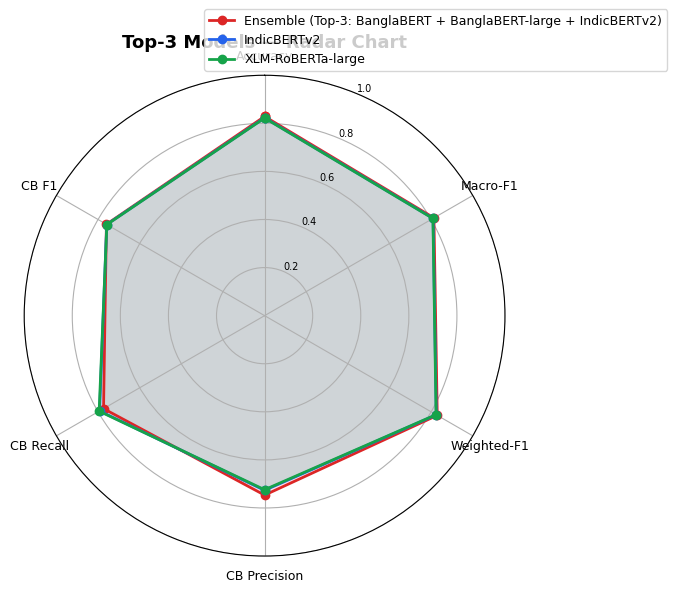

In [44]:
# ── Radar / spider chart for top-3 models ────────────────────────
top3 = summary_df.head(3)
metrics_radar = ["Accuracy", "Macro-F1", "Weighted-F1",
                 "CB Precision", "CB Recall", "CB F1"]
N = len(metrics_radar)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
colors = ["#DC2626", "#2563EB", "#16A34A"]

for (_, row), color in zip(top3.iterrows(), colors):
    vals = row[metrics_radar].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, "o-", linewidth=2, color=color, label=row["Model"])
    ax.fill(angles, vals, alpha=0.1, color=color)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics_radar, fontsize=9)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2","0.4","0.6","0.8","1.0"], fontsize=7)
ax.set_title("Top-3 Models — Radar Chart", fontsize=13, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_19_radar_top3.png", dpi=150, bbox_inches="tight")
plt.show()


## 💾 Section 14 — Save All Results & Export Best Model
Saves the complete results JSON/CSV and exports the best-performing
**single transformer encoder** (weights + tokenizer) to a ready-to-reuse
folder — useful for deployment or attaching to a paper/demo.


In [45]:
# ── Save JSON (excluding non-serialisable numpy arrays) ──────────
json_results = []
for r in ALL_RESULTS:
    row = {k: v for k, v in r.items() if k != "confusion_matrix"}
    for k, v in row.items():
        if isinstance(v, (np.floating, np.integer)):
            row[k] = float(v)
    json_results.append(row)

with open(f"{SAVE_DIR}/all_results.json", "w", encoding="utf-8") as f:
    json.dump(json_results, f, indent=2, ensure_ascii=False)

print("✅ All results saved.")
print(f"\nOutput directory : {SAVE_DIR}")
print("Files saved:")
for fname in sorted(os.listdir(SAVE_DIR)):
    fpath = f"{SAVE_DIR}/{fname}"
    if os.path.isfile(fpath):
        size = os.path.getsize(fpath)
        print(f"  {fname:<50}  {size/1024:.1f} KB")


✅ All results saved.

Output directory : /kaggle/working/banglabait_results
Files saved:
  all_results.json                                    10.2 KB
  best_banglabert.pt                                  432188.0 KB
  best_banglabert_large.pt                            1315232.6 KB
  best_indicbert_v2.pt                                1086187.1 KB
  best_mdeberta.pt                                    1089189.2 KB
  best_muril.pt                                       928040.7 KB
  best_sagor_banglabert.pt                            642262.9 KB
  best_xlmr_base.pt                                   1086196.8 KB
  best_xlmr_large.pt                                  2187242.2 KB
  fig_00_font_smoke_test.png                          35.3 KB
  fig_01_class_distribution.png                       74.5 KB
  fig_02_top_words.png                                78.5 KB
  fig_02b_wordclouds.png                              776.2 KB
  fig_10_comparison_all_metrics.png                   273.2 KB
  fi

In [46]:
# ── Export the best single transformer encoder for reuse ─────────
registry_names = {m["name"] for m in MODEL_REGISTRY}
best_encoder_row = summary_df[summary_df["Model"].isin(registry_names)].iloc[0]
best_cfg = next(c for c in MODEL_REGISTRY if c["name"] == best_encoder_row["Model"])

print(f"Best single encoder model: {best_cfg['name']}  (Macro-F1={best_encoder_row['Macro-F1']:.4f})")

export_dir = f"{SAVE_DIR}/best_model_export"
os.makedirs(export_dir, exist_ok=True)

best_tokenizer = AutoTokenizer.from_pretrained(best_cfg["model_id"])
best_model     = AutoModelForSequenceClassification.from_pretrained(
    best_cfg["model_id"], num_labels=2)
best_model.load_state_dict(
    torch.load(f"{SAVE_DIR}/best_{best_cfg['save_name']}.pt", map_location="cpu"))

best_model.save_pretrained(export_dir)
best_tokenizer.save_pretrained(export_dir)
with open(f"{export_dir}/model_card.json", "w", encoding="utf-8") as f:
    json.dump({
        "base_model_id": best_cfg["model_id"],
        "task": "Bangla clickbait title binary classification",
        "labels": {"0": "Non-Clickbait", "1": "Clickbait"},
        "max_seq_len": best_cfg["max_len"],
        "needs_bn_norm": bool(best_cfg.get("needs_bn_norm", False)),
        "decision_threshold": float(best_encoder_row["Threshold"]) if best_encoder_row["Threshold"] != "—" else 0.5,
        "test_macro_f1": float(best_encoder_row["Macro-F1"]),
        "test_accuracy": float(best_encoder_row["Accuracy"]),
    }, f, indent=2, ensure_ascii=False)

print(f"✅ Exported best model to: {export_dir}")
print("   (contains config.json, model weights, tokenizer files, model_card.json)")

del best_model
gpu_clear()


Best single encoder model: IndicBERTv2  (Macro-F1=0.8093)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Exported best model to: /kaggle/working/banglabait_results/best_model_export
   (contains config.json, model weights, tokenizer files, model_card.json)
  GPU cleared — 14.15 GB free


In [47]:
# ── 14.x  EXTENSION: also persist raw per-sample predictions ──────
# The cells above already save aggregate metrics (all_results.json).
# The audit items below (error diagnostics, calibration, statistical
# significance testing) need the raw per-sample probabilities / predictions
# for all 12 models, so we persist those too. This makes Sections 16-28
# below re-runnable from this checkpoint alone, without repeating the
# full GPU training run every time.
import pickle

raw_predictions_path = f"{SAVE_DIR}/raw_predictions.pkl"
with open(raw_predictions_path, "wb") as f:
    pickle.dump({
        "ALL_PROBS": ALL_PROBS,     # {model_name: (y_true_list, prob_of_class1_list)}
        "ALL_PREDS": ALL_PREDS,     # {model_name: pred_label_list}
        "y_ts": list(y_ts),
        "X_ts": list(X_ts),
        "model_registry_names": [m["name"] for m in MODEL_REGISTRY],
    }, f)

print(f"✅ Raw per-sample predictions/probabilities saved to {raw_predictions_path}")
print(f"   Models with stored probabilities : {len(ALL_PROBS)}  {list(ALL_PROBS.keys())}")
print(f"   Models with stored predictions   : {len(ALL_PREDS)}  {list(ALL_PREDS.keys())}")

✅ Raw per-sample predictions/probabilities saved to /kaggle/working/banglabait_results/raw_predictions.pkl
   Models with stored probabilities : 11  ['XLM-RoBERTa-base', 'XLM-RoBERTa-large', 'BanglaBERT (csebuetnlp)', 'BanglaBERT-large (csebuetnlp)', 'Bangla-BERT-Base (sagorsarker)', 'mDeBERTa-v3-base', 'MuRIL-base', 'IndicBERTv2', 'TF-IDF + LogisticRegression', 'TF-IDF + LinearSVC', 'Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)']
   Models with stored predictions   : 12  ['XLM-RoBERTa-base', 'XLM-RoBERTa-large', 'BanglaBERT (csebuetnlp)', 'BanglaBERT-large (csebuetnlp)', 'Bangla-BERT-Base (sagorsarker)', 'mDeBERTa-v3-base', 'MuRIL-base', 'IndicBERTv2', 'TF-IDF + LogisticRegression', 'TF-IDF + LinearSVC', 'Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)', 'TigerLLM-1B-it (QLoRA)']


## 🔍 Section 15 — Qualitative Inference Demo
A quick sanity check of the exported best model on a handful of example
Bangla titles — useful for the qualitative-analysis section of a paper.


The tokenizer you are loading from '/kaggle/working/banglabait_results/best_model_export' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Title                                                   Prediction      P(Clickbait)
------------------------------------------------------------------------------------------
দেখুন কী ঘটল, বিশ্বাস করতে পারবেন না!                   Clickbait       0.9981
ঢাকায় আজ সকালে হালকা বৃষ্টিপাতের সম্ভাবনা              Non-Clickbait   0.0024
এই ৫টি অভ্যাস আপনার জীবন বদলে দিতে পারে, ৪ নম্বরটি সবচেয়ে চমকপ্রদ Clickbait       0.9921
বাংলাদেশ ব্যাংক নতুন মুদ্রানীতি ঘোষণা করেছে             Non-Clickbait   0.0040
সে কী করল দেখে পুরো ইন্টারনেট হতবাক!                    Clickbait       0.9982


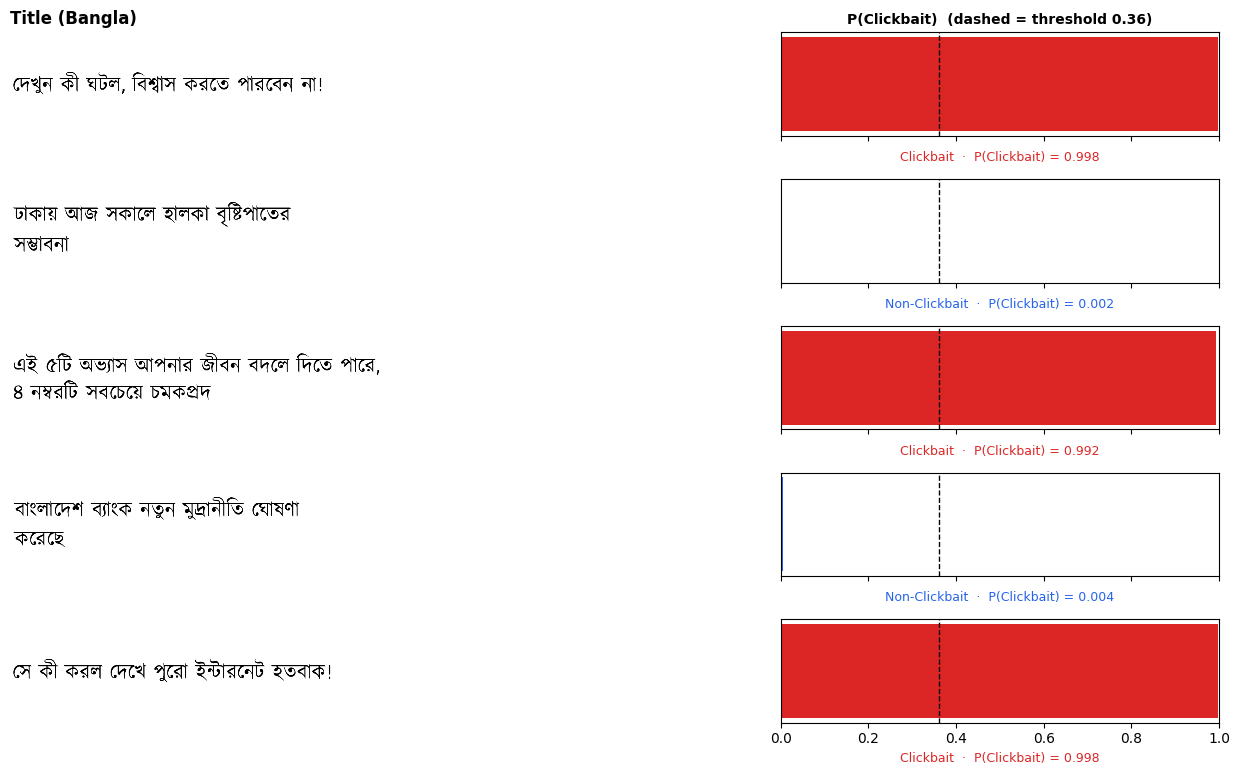

  GPU cleared — 14.15 GB free


In [48]:
demo_tokenizer = AutoTokenizer.from_pretrained(export_dir)
demo_model     = AutoModelForSequenceClassification.from_pretrained(export_dir).to(DEVICE)
demo_model.eval()
_demo_card      = json.load(open(f"{export_dir}/model_card.json"))
demo_threshold  = _demo_card["decision_threshold"]
# FIX: BanglaBERT-family checkpoints were trained on csebuetnlp-normalized text, so the demo must
# normalize its inputs too (otherwise train/inference text differ). Flag saved in model_card.json.
demo_needs_norm = bool(_demo_card.get("needs_bn_norm", False))

# A small, illustrative mix of stereotypically clickbait-style and neutral,
# informational-style Bangla titles (not from the dataset).
demo_titles = [
    "দেখুন কী ঘটল, বিশ্বাস করতে পারবেন না!",
    "ঢাকায় আজ সকালে হালকা বৃষ্টিপাতের সম্ভাবনা",
    "এই ৫টি অভ্যাস আপনার জীবন বদলে দিতে পারে, ৪ নম্বরটি সবচেয়ে চমকপ্রদ",
    "বাংলাদেশ ব্যাংক নতুন মুদ্রানীতি ঘোষণা করেছে",
    "সে কী করল দেখে পুরো ইন্টারনেট হতবাক!",
]

def predict_titles(titles, threshold=0.5):
    results = []
    with torch.no_grad():
        for t in titles:
            t_in = bn_normalize(t) if demo_needs_norm else t
            enc = demo_tokenizer(t_in, max_length=128, padding="max_length",
                                 truncation=True, return_tensors="pt").to(DEVICE)
            logits = demo_model(**enc, return_dict=False)[0]
            prob_cb = torch.softmax(logits.float(), dim=-1)[0, 1].item()
            pred = "Clickbait" if prob_cb >= threshold else "Non-Clickbait"
            results.append((t, pred, prob_cb))
    return results

demo_results = predict_titles(demo_titles, demo_threshold)
print(f"{'Title':<55} {'Prediction':<15} {'P(Clickbait)'}")
print("-" * 90)
for title, pred, prob in demo_results:
    print(f"{title:<55} {pred:<15} {prob:.4f}")

# ── Qualitative figure: shaped Bengali titles + predicted probability ──
n_demo = len(demo_results)
fig, axes = plt.subplots(n_demo, 2, figsize=(12.5, 1.25 * n_demo + 1.6),
                         gridspec_kw={"width_ratios": [1.7, 1]})
for r, (ax_t, ax_p) in enumerate(axes):
    title, pred, prob = demo_results[r]
    color = "#DC2626" if pred == "Clickbait" else "#2563EB"
    ax_t.axis("off")
    draw_bengali_text(ax_t, 0.0, 0.5, wrap_bengali_text(title, width=40), fontsize=15,
                      ha="left", va="center", transform=ax_t.transAxes)
    ax_p.barh([0], [prob], color=color, height=0.55)
    ax_p.axvline(demo_threshold, color="black", linestyle="--", linewidth=1)
    ax_p.set_xlim(0, 1); ax_p.set_yticks([])
    ax_p.set_xlabel(f"{pred}  ·  P(Clickbait) = {prob:.3f}", fontsize=9, color=color)
    if r < n_demo - 1:
        ax_p.set_xticklabels([])
axes[0, 0].set_title("Title (Bangla)", loc="left", fontweight="bold")
axes[0, 1].set_title(f"P(Clickbait)  (dashed = threshold {demo_threshold:.2f})", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_15_qualitative_inference_demo.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

del demo_model
gpu_clear()


## 📏 Section 16 — Title Length Distribution Analysis
Character-count and word-count distributions for **Clickbait vs. Non-Clickbait**
titles (combined train + test splits), shown as overlaid KDE plots and boxplots
(median, IQR, outliers) for both metrics.

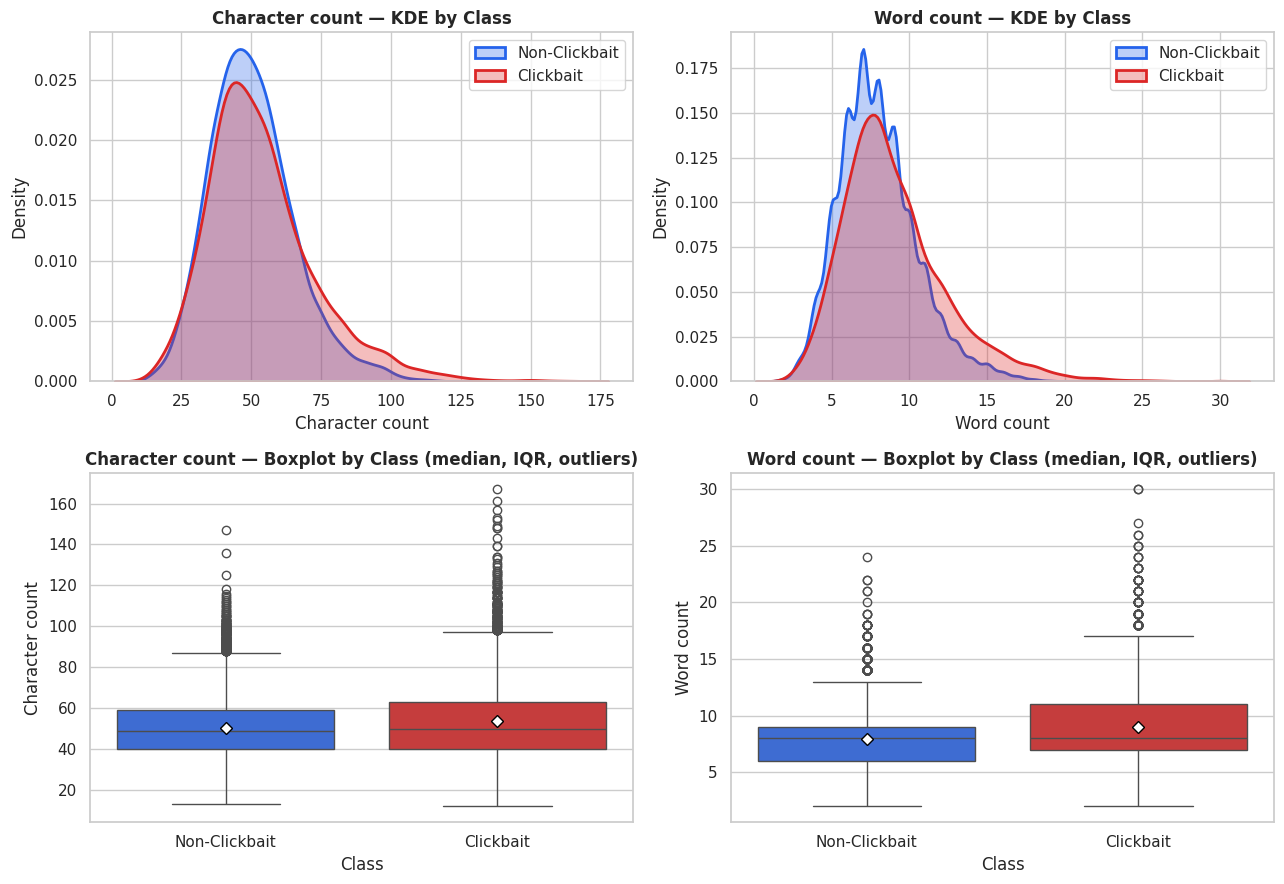

Summary statistics (character count / word count) by class:
              char_count                                                          word_count                                                   
                   count    mean     std     min     25%     50%     75%      max      count   mean    std    min    25%    50%     75%     max
Class                                                                                                                                          
Clickbait      4608.0000 53.6500 19.5300 12.0000 40.0000 50.0000 63.0000 167.0000  4608.0000 9.0200 3.3900 2.0000 7.0000 8.0000 11.0000 30.0000
Non-Clickbait  8849.0000 50.3500 15.2800 13.0000 40.0000 49.0000 59.0000 147.0000  8849.0000 7.9800 2.5500 2.0000 6.0000 8.0000  9.0000 24.0000


In [49]:
# ── 16.1  Character & word counts, split by class ─────────────────
sns.set_theme(style="whitegrid")
apply_bengali_rc()   # seaborn resets rcParams; re-register the Bengali fallback font (Section 1B)

len_df = pd.concat([
    bn_train_full[[TEXT_COL, LABEL_COL]].assign(split="train"),
    bn_test[[TEXT_COL, LABEL_COL]].assign(split="test"),
], ignore_index=True)
len_df["char_count"] = len_df[TEXT_COL].str.len()
len_df["word_count"] = len_df[TEXT_COL].str.split().str.len()
len_df["Class"] = len_df[LABEL_COL].map(dict(enumerate(LABEL_NAMES)))

palette = {"Non-Clickbait": "#2563EB", "Clickbait": "#DC2626"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, metric, xlabel in [(axes[0, 0], "char_count", "Character count"),
                            (axes[0, 1], "word_count", "Word count")]:
    for cls in LABEL_NAMES:
        sns.kdeplot(len_df.loc[len_df["Class"] == cls, metric], ax=ax, label=cls,
                    color=palette[cls], fill=True, alpha=0.3, linewidth=2)
    ax.set_title(f"{xlabel} — KDE by Class", fontweight="bold")
    ax.set_xlabel(xlabel); ax.legend()

for ax, metric, ylabel in [(axes[1, 0], "char_count", "Character count"),
                            (axes[1, 1], "word_count", "Word count")]:
    sns.boxplot(data=len_df, x="Class", y=metric, ax=ax, hue="Class", order=LABEL_NAMES,
                palette=palette, showmeans=True, legend=False,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
    ax.set_title(f"{ylabel} — Boxplot by Class (median, IQR, outliers)", fontweight="bold")
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_16_title_length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("Summary statistics (character count / word count) by class:")
print(len_df.groupby("Class")[["char_count", "word_count"]]
      .describe(percentiles=[.25, .5, .75]).round(2).to_string())

## ❗ Section 17 — Punctuation Frequency Analysis
Mean frequency of exclamation marks, question marks, brackets and parentheses
per title, **normalized by title character length**, compared across classes.
Uses the Bangla-aware punctuation set from `bnlp_toolkit` in addition to the four
target marks so the counting logic is consistent with the rest of the corpus.

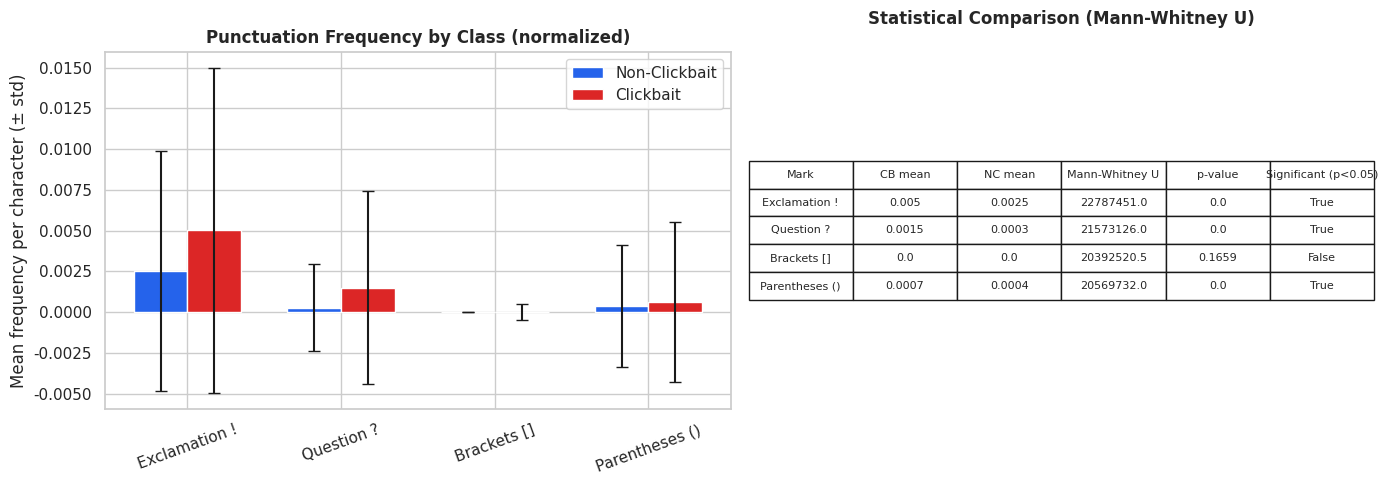

          Mark  CB mean  NC mean  Mann-Whitney U  p-value  Significant (p<0.05)
 Exclamation !   0.0050   0.0025   22787451.0000   0.0000                  True
    Question ?   0.0015   0.0003   21573126.0000   0.0000                  True
   Brackets []   0.0000   0.0000   20392520.5000   0.1659                 False
Parentheses ()   0.0007   0.0004   20569732.0000   0.0000                  True


In [50]:
# ── 17.1  Punctuation counts, normalized per title length ──────────
def punctuation_features(s):
    length = max(len(s), 1)
    return pd.Series({
        "excl_norm":    s.count("!") / length,
        "question_norm": s.count("?") / length,
        "bracket_norm": (s.count("[") + s.count("]")) / length,
        "paren_norm":   (s.count("(") + s.count(")")) / length,
    })

punct_df = len_df.copy()
punct_df = pd.concat([punct_df, punct_df[TEXT_COL].apply(punctuation_features)], axis=1)

punct_cols   = ["excl_norm", "question_norm", "bracket_norm", "paren_norm"]
punct_labels = ["Exclamation !", "Question ?", "Brackets []", "Parentheses ()"]

grp_mean = punct_df.groupby("Class")[punct_cols].mean()
grp_std  = punct_df.groupby("Class")[punct_cols].std()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(punct_cols))
width = 0.35
for i, cls in enumerate(LABEL_NAMES):
    axes[0].bar(x + (i - 0.5) * width, grp_mean.loc[cls, punct_cols].values, width,
                yerr=grp_std.loc[cls, punct_cols].values, capsize=4,
                label=cls, color=palette[cls])
axes[0].set_xticks(x); axes[0].set_xticklabels(punct_labels, rotation=20)
axes[0].set_ylabel("Mean frequency per character (± std)")
axes[0].set_title("Punctuation Frequency by Class (normalized)", fontweight="bold")
axes[0].legend()

# Statistical comparison: Mann-Whitney U per punctuation mark (non-parametric,
# appropriate since these frequency distributions are heavily zero-inflated)
from scipy.stats import mannwhitneyu
rows = []
for col, label in zip(punct_cols, punct_labels):
    cb_vals = punct_df.loc[punct_df["Class"] == "Clickbait", col]
    nc_vals = punct_df.loc[punct_df["Class"] == "Non-Clickbait", col]
    stat, p = mannwhitneyu(cb_vals, nc_vals, alternative="two-sided")
    rows.append({"Mark": label, "CB mean": cb_vals.mean(), "NC mean": nc_vals.mean(),
                 "Mann-Whitney U": stat, "p-value": p,
                 "Significant (p<0.05)": p < 0.05})
punct_stats_df = pd.DataFrame(rows)

axes[1].axis("off")
tbl = axes[1].table(cellText=punct_stats_df.round(4).astype(str).values,
                     colLabels=punct_stats_df.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1, 1.8)
axes[1].set_title("Statistical Comparison (Mann-Whitney U)", fontweight="bold", pad=20)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_17_punctuation_frequency.png", dpi=150, bbox_inches="tight")
plt.show()
print(punct_stats_df.to_string(index=False))

## 🎯 Section 18 — Clickbait Trigger Words Extraction
Top-15 sensational/exaggeration n-grams, ranked by **add-one-smoothed log-odds ratio**
between classes (Monroe et al.-style informative-prior log-odds, simplified),
computed on the same TF-IDF vocabulary fit in Section 8. Color encodes which
class each n-gram is associated with.

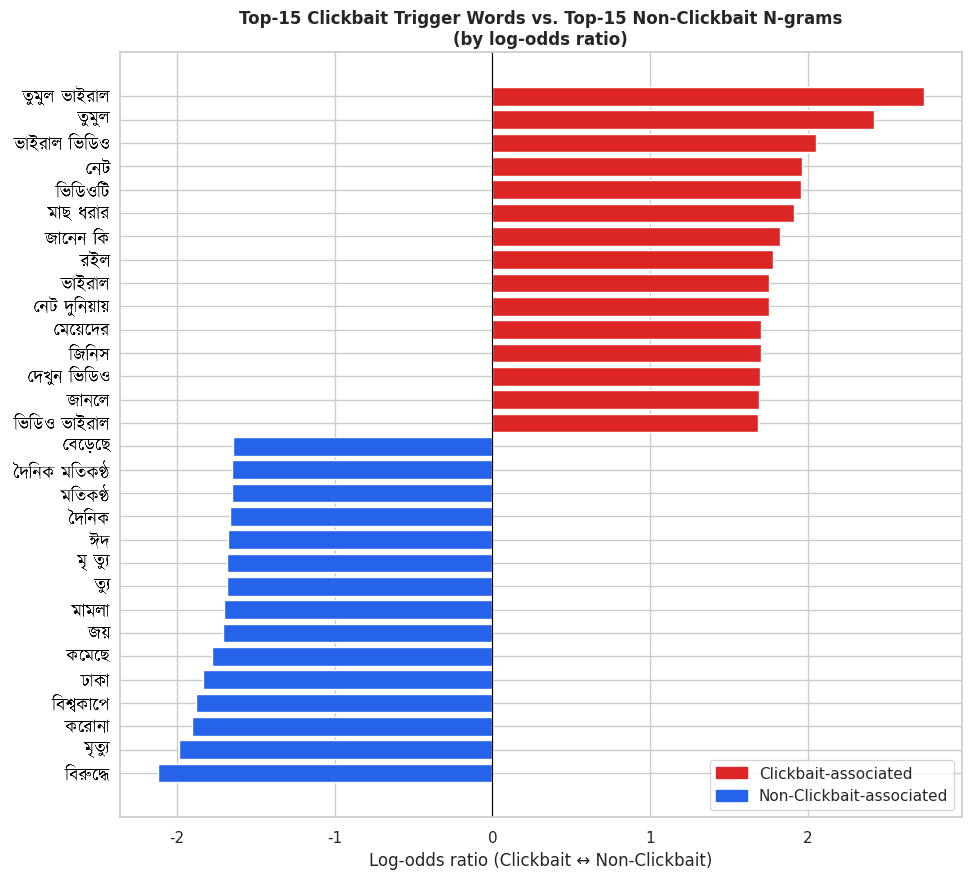

Top-15 Clickbait-associated n-grams (by log-odds ratio):
       ngram  log_odds
তুমুল ভাইরাল    2.7324
       তুমুল    2.4182
ভাইরাল ভিডিও    2.0504
         নেট    1.9605
     ভিডিওটি    1.9545
    মাছ ধরার    1.9103
    জানেন কি    1.8200
         রইল    1.7790
      ভাইরাল    1.7554
 নেট দুনিয়ায়    1.7535
     মেয়েদের    1.7034
       জিনিস    1.7034
 দেখুন ভিডিও    1.6979
       জানলে    1.6879
ভিডিও ভাইরাল    1.6806


In [51]:
# ── 18.1  Log-odds ratio trigger-word extraction ────────────────────
vocab = np.array(tfidf.get_feature_names_out())
cb_mask = (y_tr == 1)

counts_cb = np.asarray(Xtr_tfidf[cb_mask].sum(axis=0)).ravel() + 1     # add-one smoothing
counts_nc = np.asarray(Xtr_tfidf[~cb_mask].sum(axis=0)).ravel() + 1
log_odds  = np.log(counts_cb / counts_cb.sum()) - np.log(counts_nc / counts_nc.sum())

top_pos_idx = np.argsort(log_odds)[::-1][:15]     # most Clickbait-associated
top_neg_idx = np.argsort(log_odds)[:15]           # most Non-Clickbait-associated

trigger_df = pd.DataFrame({
    "ngram": np.concatenate([vocab[top_pos_idx], vocab[top_neg_idx]]),
    "log_odds": np.concatenate([log_odds[top_pos_idx], log_odds[top_neg_idx]]),
    "association": ["Clickbait"] * 15 + ["Non-Clickbait"] * 15,
})

fig, ax = plt.subplots(figsize=(10, 9))
plot_df = trigger_df.sort_values("log_odds")
colors = [palette[a] for a in plot_df["association"]]
ax.barh(range(len(plot_df)), plot_df["log_odds"], color=colors)
label_w = set_bengali_yticklabels(ax, plot_df["ngram"], fontsize=13)    # shaped Bengali n-grams
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Log-odds ratio (Clickbait ↔ Non-Clickbait)")
ax.set_title("Top-15 Clickbait Trigger Words vs. Top-15 Non-Clickbait N-grams\n(by log-odds ratio)",
             fontweight="bold")
import matplotlib.patches as mpatches
ax.legend(handles=[mpatches.Patch(color=palette["Clickbait"], label="Clickbait-associated"),
                    mpatches.Patch(color=palette["Non-Clickbait"], label="Non-Clickbait-associated")],
          loc="lower right")
reserve_left_margin(fig, label_w, top=0.92, bottom=0.07)
plt.savefig(f"{SAVE_DIR}/fig_18_trigger_words.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Top-15 Clickbait-associated n-grams (by log-odds ratio):")
print(trigger_df[trigger_df["association"] == "Clickbait"]
      .sort_values("log_odds", ascending=False)[["ngram", "log_odds"]].to_string(index=False))


## 📉 Section 19 — Loss & Macro-F1 Curves — 4 Headline Models
Combined training diagnostics for **TF-IDF + LogReg**, **TF-IDF + LinearSVC**,
**Ensemble Top-3**, and **TigerLLM-1B-it**. Neither classical model has a native
per-epoch loss, and the ensemble has no gradient-based training step at all, so
each gets an honest, real analogue instead of an invented curve:
- **LogReg** — real refits at increasing `max_iter` via `warm_start=True` (log-loss + Macro-F1 at each step).
- **LinearSVC** — real refits at increasing `max_iter` (mean hinge loss, computed from the real decision function, + Macro-F1 at each step).
- **Ensemble Top-3** — Macro-F1 as members are added one-by-one (N=1→3); an averaging ensemble has no training loss to plot.
- **TigerLLM-1B-it** — its real QLoRA fine-tuning train/eval loss from the HF `Trainer` log history (no per-epoch Macro-F1 is tracked for this generation-based model — only the single end-of-training test value from Section 10.6).

In [52]:
# ── 19.0  Resolve the 4 headline model names to their actual keys ──
from sklearn.metrics import log_loss
import warnings as _warnings

HEADLINE_MODELS = ["TF-IDF + LogReg", "TF-IDF + LinearSVC", "Ensemble Top-3", "TigerLLM-1B-it"]

def resolve_model_key(friendly_name, keys):
    """Map one of the 4 headline names used in this audit to whatever key
    ALL_RESULTS / ALL_PROBS / ALL_PREDS actually used (the ensemble name
    embeds its member models, so it isn't fixed in advance)."""
    alias_prefix = {
        "TF-IDF + LogReg":    "TF-IDF + LogisticRegression",
        "TF-IDF + LinearSVC": "TF-IDF + LinearSVC",
        "Ensemble Top-3":     "Ensemble (Top-",
        "TigerLLM-1B-it":     "TigerLLM-1B-it",
    }.get(friendly_name, friendly_name)
    for k in keys:
        if k.startswith(alias_prefix):
            return k
    return None

# FIX: the "Val" curves below used to be computed on the TEST set; use the real validation split.
Xvl_tfidf = tfidf.transform(X_vl)

_all_result_keys = [r["title"] for r in ALL_RESULTS]
HEADLINE_KEYS = {name: resolve_model_key(name, _all_result_keys) for name in HEADLINE_MODELS}
print("Resolved headline-model keys (blank = not found in ALL_RESULTS — re-run the relevant section):")
for k, v in HEADLINE_KEYS.items():
    print(f"  {k!r:22s} -> {v!r}")

Resolved headline-model keys (blank = not found in ALL_RESULTS — re-run the relevant section):
  'TF-IDF + LogReg'      -> 'TF-IDF + LogisticRegression'
  'TF-IDF + LinearSVC'   -> 'TF-IDF + LinearSVC'
  'Ensemble Top-3'       -> 'Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)'
  'TigerLLM-1B-it'       -> 'TigerLLM-1B-it (QLoRA)'


In [53]:
# ── 19.1(a)  TF-IDF + LogReg — pseudo-epoch curve via warm_start ──
def logreg_pseudo_epochs(iters=(1, 5, 10, 20, 40, 80, 160, 320)):
    tr_loss, vl_loss, tr_f1, vl_f1 = [], [], [], []
    clf = LogisticRegression(max_iter=1, warm_start=True, class_weight="balanced",
                              C=2.0, random_state=SEED)
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        for it in iters:
            clf.max_iter = it
            clf.fit(Xtr_tfidf, y_tr)
            p_tr, p_vl = clf.predict_proba(Xtr_tfidf), clf.predict_proba(Xvl_tfidf)
            tr_loss.append(log_loss(y_tr, p_tr, labels=[0, 1]))
            vl_loss.append(log_loss(y_vl, p_vl, labels=[0, 1]))
            tr_f1.append(f1_score(y_tr, clf.predict(Xtr_tfidf), average="macro", zero_division=0))
            vl_f1.append(f1_score(y_vl, clf.predict(Xvl_tfidf), average="macro", zero_division=0))
    return dict(step=list(iters), tr_loss=tr_loss, vl_loss=vl_loss, tr_f1=tr_f1, vl_f1=vl_f1)

logreg_curve = logreg_pseudo_epochs()
print("TF-IDF + LogReg — real refits at increasing max_iter:")
print(pd.DataFrame(logreg_curve).round(4).to_string(index=False))

TF-IDF + LogReg — real refits at increasing max_iter:
 step  tr_loss  vl_loss  tr_f1  vl_f1
    1   0.6578   0.6679 0.7191 0.6421
    5   0.4509   0.5396 0.8064 0.7073
   10   0.4039   0.5257 0.8850 0.7294
   20   0.3433   0.5161 0.9334 0.7345
   40   0.3438   0.5166 0.9329 0.7348
   80   0.3438   0.5166 0.9329 0.7348
  160   0.3438   0.5166 0.9329 0.7348
  320   0.3438   0.5166 0.9329 0.7348


In [54]:
# ── 19.1(b)  TF-IDF + LinearSVC — pseudo-epoch curve via max_iter sweep ──
def linearsvc_pseudo_epochs(iters=(1, 5, 10, 20, 50, 100, 200, 400)):
    tr_hinge, vl_hinge, tr_f1, vl_f1 = [], [], [], []
    y_tr_signed, y_vl_signed = np.where(y_tr == 1, 1, -1), np.where(y_vl == 1, 1, -1)
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        for it in iters:
            svc = LinearSVC(class_weight="balanced", C=1.0, random_state=SEED, max_iter=it)
            svc.fit(Xtr_tfidf, y_tr)
            d_tr, d_vl = svc.decision_function(Xtr_tfidf), svc.decision_function(Xvl_tfidf)
            tr_hinge.append(float(np.mean(np.maximum(0, 1 - y_tr_signed * d_tr))))
            vl_hinge.append(float(np.mean(np.maximum(0, 1 - y_vl_signed * d_vl))))
            tr_f1.append(f1_score(y_tr, svc.predict(Xtr_tfidf), average="macro", zero_division=0))
            vl_f1.append(f1_score(y_vl, svc.predict(Xvl_tfidf), average="macro", zero_division=0))
    return dict(step=list(iters), tr_loss=tr_hinge, vl_loss=vl_hinge, tr_f1=tr_f1, vl_f1=vl_f1)

linearsvc_curve = linearsvc_pseudo_epochs()
print("TF-IDF + LinearSVC — real refits; loss = mean hinge loss on the real decision function:")
print(pd.DataFrame(linearsvc_curve).round(4).to_string(index=False))

TF-IDF + LinearSVC — real refits; loss = mean hinge loss on the real decision function:
 step  tr_loss  vl_loss  tr_f1  vl_f1
    1   0.6204   0.8210 0.7827 0.6385
    5   0.2979   0.6458 0.9907 0.7331
   10   0.2840   0.6438 0.9932 0.7322
   20   0.2882   0.6492 0.9926 0.7282
   50   0.2882   0.6492 0.9926 0.7282
  100   0.2882   0.6492 0.9926 0.7282
  200   0.2882   0.6492 0.9926 0.7282
  400   0.2882   0.6492 0.9926 0.7282


In [55]:
# ── 19.1(c)  Ensemble Top-3 — Macro-F1 as members are added ──────
# No gradient-based training loss exists for an averaging ensemble; instead we
# recompute, for real, how Macro-F1 evolves as each top-ranked member is added.
def ensemble_growth_curve(top_n=3):
    registry_names   = {m["name"] for m in MODEL_REGISTRY}
    transformer_rows = [r for r in ALL_RESULTS if r["title"] in registry_names]
    top_rows  = sorted(transformer_rows, key=lambda r: r["best_val_f1"], reverse=True)[:top_n]
    top_names = [r["title"] for r in top_rows]
    cfg_by_name = {m["name"]: m for m in MODEL_REGISTRY}

    probs_sum, labels_ref, growth = None, None, []
    for name in top_names:
        cfg = cfg_by_name[name]
        tokenizer  = AutoTokenizer.from_pretrained(cfg["model_id"])
        base_model = AutoModelForSequenceClassification.from_pretrained(cfg["model_id"], num_labels=2)
        model = wrap_multi_gpu(base_model)
        _, _, ts_loader = make_loaders(X_tr, y_tr, X_vl, y_vl, X_ts, y_ts, tokenizer, cfg)
        get_base_model(model).load_state_dict(
            torch.load(f"{SAVE_DIR}/best_{cfg['save_name']}.pt", map_location=DEVICE))
        model.eval()
        probs_this, labels_this = [], []
        with torch.no_grad():
            for batch in ts_loader:
                ids  = batch["input_ids"].to(DEVICE, non_blocking=True)
                mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=USE_AMP):
                    logits = forward_logits(model, ids, mask)
                probs_this  += torch.softmax(logits.float(), dim=-1)[:, 1].cpu().tolist()
                labels_this += batch["labels"].tolist()
        probs_this = np.array(probs_this)
        probs_sum  = probs_this if probs_sum is None else probs_sum + probs_this
        labels_ref = labels_this
        n_so_far = len(growth) + 1
        preds_so_far = [1 if p >= 0.5 else 0 for p in (probs_sum / n_so_far)]
        growth.append({"n_models": n_so_far, "added": name,
                        "macro_f1": f1_score(labels_ref, preds_so_far, average="macro", zero_division=0)})
        del model, base_model, tokenizer, ts_loader
        gpu_clear()
    return pd.DataFrame(growth)

ensemble_curve_df = ensemble_growth_curve(top_n=3)
print("\nEnsemble Top-3 — Macro-F1 as members are added (real re-inference per step):")
print(ensemble_curve_df.to_string(index=False))

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 14.13 GB free


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 14.13 GB free


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 14.13 GB free

Ensemble Top-3 — Macro-F1 as members are added (real re-inference per step):
 n_models                         added  macro_f1
        1       BanglaBERT (csebuetnlp)    0.7972
        2 BanglaBERT-large (csebuetnlp)    0.8054
        3                   IndicBERTv2    0.8133


In [56]:
# ── 19.1(d)  TigerLLM-1B-it — real fine-tuning loss curve ─────────
tiger_log_path = f"{SAVE_DIR}/tigerllm_log_history.json"
try:
    _tiger_hist = tiger_log_history
except NameError:
    _tiger_hist = None
if not _tiger_hist and os.path.exists(tiger_log_path):
    with open(tiger_log_path) as f:
        _tiger_hist = json.load(f)

if _tiger_hist:
    tiger_tr_steps = [(e["step"], e["loss"])      for e in _tiger_hist if "loss" in e]
    tiger_vl_steps = [(e["step"], e["eval_loss"]) for e in _tiger_hist if "eval_loss" in e]
    tiger_curve_available = len(tiger_tr_steps) > 0
else:
    tiger_tr_steps, tiger_vl_steps, tiger_curve_available = [], [], False

if tiger_curve_available:
    print(f"TigerLLM-1B-it — {len(tiger_tr_steps)} logged train-loss points, "
          f"{len(tiger_vl_steps)} logged eval-loss points (real Trainer log_history).")
else:
    print("⚠️  No TigerLLM training log found — re-run Section 10 in this session to "
          "populate it (TIGER_AVAILABLE was False, or the kernel restarted since then). "
          "The TigerLLM panel below will show 'no data' rather than an invented curve.")

TigerLLM-1B-it — 70 logged train-loss points, 3 logged eval-loss points (real Trainer log_history).


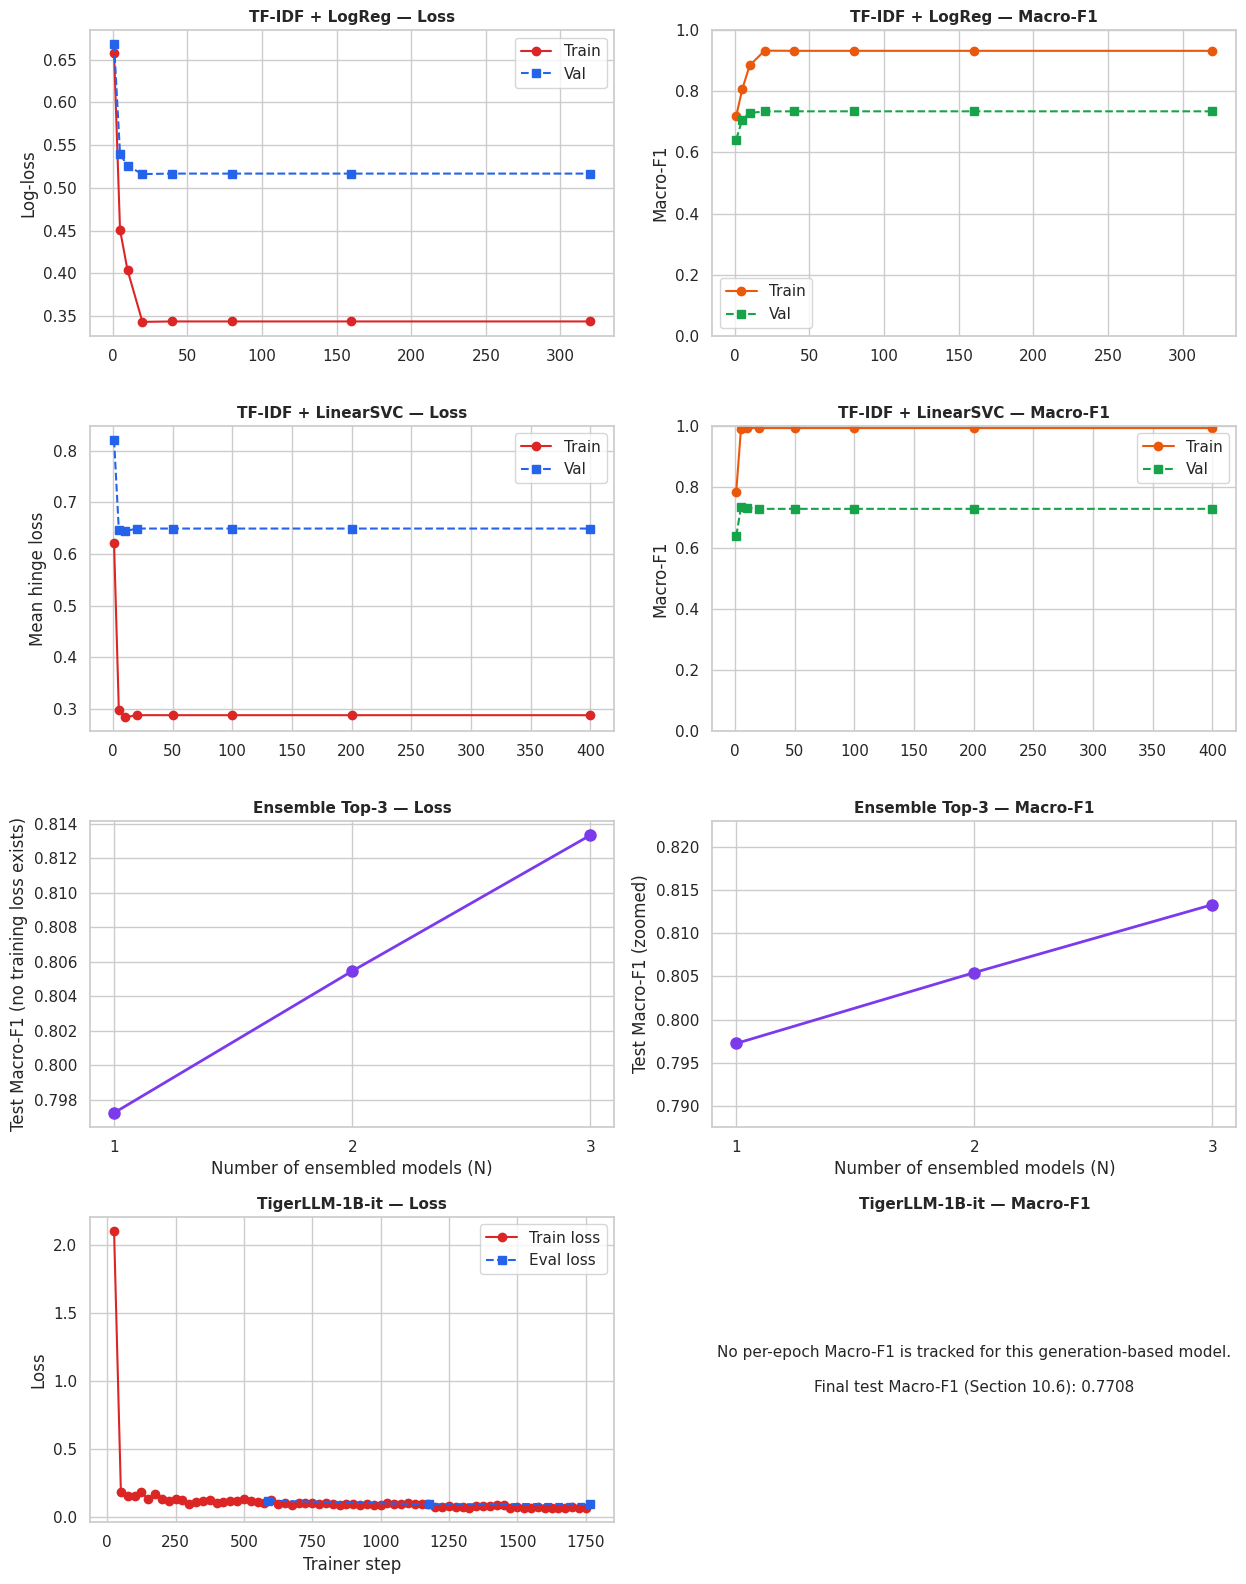

In [57]:
# ── 19.2  Combined 4-model × (Loss | Macro-F1) figure ─────────────
fig, axes = plt.subplots(4, 2, figsize=(13, 16))
row_titles = HEADLINE_MODELS

# Row 0: LogReg
axes[0,0].plot(logreg_curve["step"], logreg_curve["tr_loss"], "o-", color="#DC2626", label="Train")
axes[0,0].plot(logreg_curve["step"], logreg_curve["vl_loss"], "s--", color="#2563EB", label="Val")
axes[0,0].set_ylabel("Log-loss"); axes[0,0].legend()
axes[0,1].plot(logreg_curve["step"], logreg_curve["tr_f1"], "o-", color="#EA580C", label="Train")
axes[0,1].plot(logreg_curve["step"], logreg_curve["vl_f1"], "s--", color="#16A34A", label="Val")
axes[0,1].set_ylabel("Macro-F1"); axes[0,1].set_ylim(0,1); axes[0,1].legend()

# Row 1: LinearSVC
axes[1,0].plot(linearsvc_curve["step"], linearsvc_curve["tr_loss"], "o-", color="#DC2626", label="Train")
axes[1,0].plot(linearsvc_curve["step"], linearsvc_curve["vl_loss"], "s--", color="#2563EB", label="Val")
axes[1,0].set_ylabel("Mean hinge loss"); axes[1,0].legend()
axes[1,1].plot(linearsvc_curve["step"], linearsvc_curve["tr_f1"], "o-", color="#EA580C", label="Train")
axes[1,1].plot(linearsvc_curve["step"], linearsvc_curve["vl_f1"], "s--", color="#16A34A", label="Val")
axes[1,1].set_ylabel("Macro-F1"); axes[1,1].set_ylim(0,1); axes[1,1].legend()

# Row 2: Ensemble growth (spans both columns conceptually — same data both panels,
# left = raw values, right = zoomed y-axis, to keep the 4x2 grid uniform)
for col in (0, 1):
    axes[2,col].plot(ensemble_curve_df["n_models"], ensemble_curve_df["macro_f1"],
                      "o-", color="#7C3AED", linewidth=2, markersize=8)
    axes[2,col].set_xticks(ensemble_curve_df["n_models"])
    axes[2,col].set_xlabel("Number of ensembled models (N)")
axes[2,0].set_ylabel("Test Macro-F1 (no training loss exists)")
axes[2,1].set_ylabel("Test Macro-F1 (zoomed)")
lo, hi = ensemble_curve_df["macro_f1"].min(), ensemble_curve_df["macro_f1"].max()
pad = max(hi - lo, 0.01) * 0.6
axes[2,1].set_ylim(lo - pad, hi + pad)

# Row 3: TigerLLM
if tiger_curve_available:
    if tiger_tr_steps:
        s, v = zip(*tiger_tr_steps); axes[3,0].plot(s, v, "o-", color="#DC2626", label="Train loss")
    if tiger_vl_steps:
        s, v = zip(*tiger_vl_steps); axes[3,0].plot(s, v, "s--", color="#2563EB", label="Eval loss")
    axes[3,0].set_xlabel("Trainer step"); axes[3,0].set_ylabel("Loss"); axes[3,0].legend()
    tiger_key = HEADLINE_KEYS["TigerLLM-1B-it"]
    final_f1 = next((r["macro_f1"] for r in ALL_RESULTS if r["title"] == tiger_key), None)
    axes[3,1].axis("off")
    msg = ("No per-epoch Macro-F1 is tracked for this generation-based model.\n\n"
           f"Final test Macro-F1 (Section 10.6): {final_f1:.4f}" if final_f1 is not None
           else "No per-epoch Macro-F1 is tracked for this generation-based model.")
    axes[3,1].text(0.5, 0.5, msg, ha="center", va="center", fontsize=11, wrap=True)
else:
    for col in (0, 1):
        axes[3,col].axis("off")
        axes[3,col].text(0.5, 0.5, "No TigerLLM training log available in this session\n"
                                    "(re-run Section 10 to populate it)",
                          ha="center", va="center", fontsize=10, color="gray")

for row, title in enumerate(row_titles):
    axes[row,0].set_title(f"{title} — Loss", fontweight="bold", fontsize=11)
    axes[row,1].set_title(f"{title} — Macro-F1", fontweight="bold", fontsize=11)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_19_headline_loss_f1_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 🟧 Section 20 — Classification Report Heatmaps — 4 Headline Models
Precision / Recall / F1 for each class (3×2 layout each), for the same four
models, laid out side-by-side for direct comparison. Values come straight from
`ALL_RESULTS`, i.e. whatever the live kernel actually evaluated in Sections 8–10.

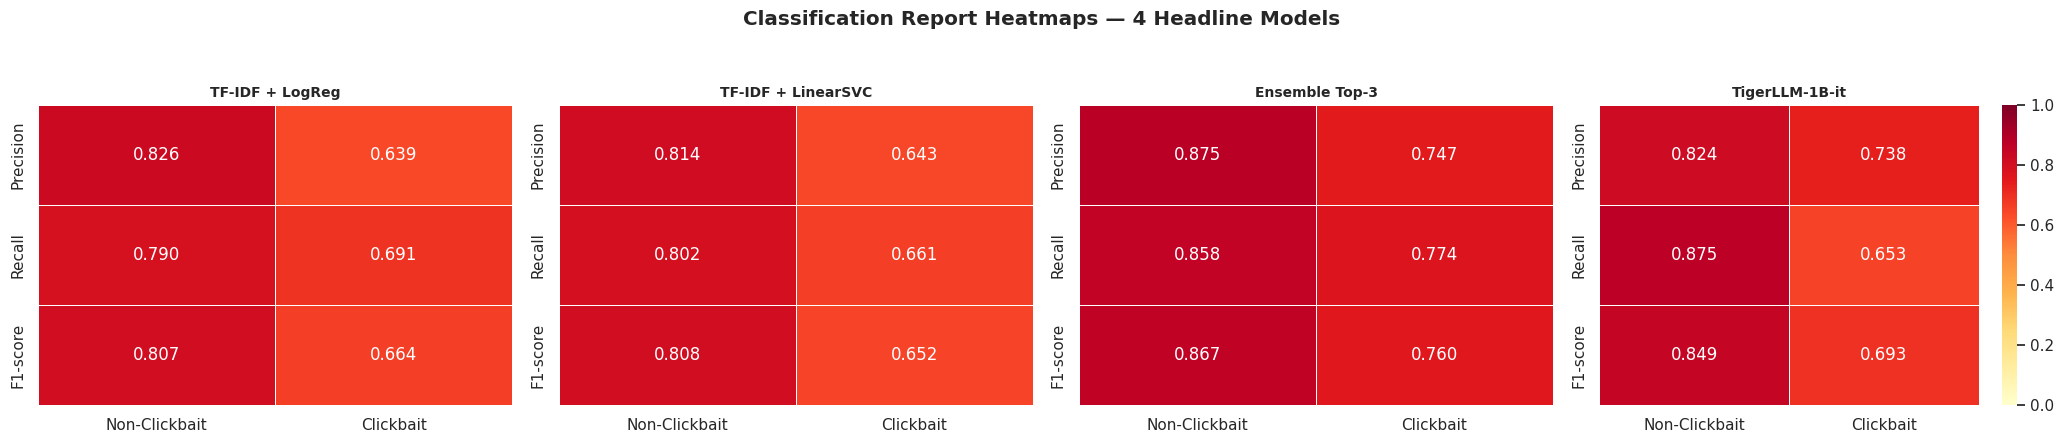

In [58]:
# ── 20.1  3×2 classification-report heatmap, 4 models side-by-side ──
results_by_key = {r["title"]: r for r in ALL_RESULTS}

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
for ax, friendly_name in zip(axes, HEADLINE_MODELS):
    key = HEADLINE_KEYS.get(friendly_name)
    if key is None or key not in results_by_key:
        ax.axis("off")
        ax.text(0.5, 0.5, f"'{friendly_name}'\nnot found in ALL_RESULTS\n(re-run the relevant section)",
                ha="center", va="center", fontsize=9, color="gray")
        continue
    m = results_by_key[key]
    data = pd.DataFrame({
        "Non-Clickbait": [m["nc_precision"], m["nc_recall"], m["nc_f1"]],
        "Clickbait":     [m["cb_precision"], m["cb_recall"], m["cb_f1"]],
    }, index=["Precision", "Recall", "F1-score"])
    sns.heatmap(data, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=1,
                linewidths=0.5, ax=ax, cbar=(ax is axes[-1]))
    ax.set_title(friendly_name, fontweight="bold", fontsize=10)

plt.suptitle("Classification Report Heatmaps — 4 Headline Models", fontweight="bold", y=1.05)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_20_headline_classification_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

## 🔬 Section 21 — LIME / SHAP Interpretability — Top-Performing Model
Uses whichever model is actually ranked #1 by Macro-F1 in `results_df` at
run-time (not hardcoded), via a generic `predict_proba`-style wrapper that
works for classical, transformer, ensemble, and TigerLLM architectures alike.
Produces word-level attributions for **2 correctly-classified Clickbait (TP)**
and **2 correctly-classified Non-Clickbait (TN)** test samples.

*Note on TigerLLM:* it is a generation-based classifier with no native class
probability. If it is ever the top model, its probabilities are approximated
via length-normalized sequence log-likelihood of the two candidate label
strings ("ক্লিকবেইট" vs. "ক্লিকবেইট নয়") — a standard technique for scoring
generative LMs as classifiers, not a fabricated number. This is flagged
explicitly in the output whenever it applies.

In [59]:
# ── 21.1  Generic predict_proba dispatcher for ANY of the 12 models ──
def get_predict_proba_fn(model_name):
    """Return fn(list[str]) -> np.ndarray[n,2] of [P(Non-Clickbait), P(Clickbait)]
    for any trained model in this notebook, resolved by its ALL_RESULTS key."""

    # (a) Classical TF-IDF models — already fitted & in memory, cheapest path
    if model_name in classical_models:
        clf = classical_models[model_name]
        def fn(texts):
            Xv = tfidf.transform(texts)
            if hasattr(clf, "predict_proba"):
                return clf.predict_proba(Xv)
            d = clf.decision_function(Xv)             # LinearSVC: logistic-squash the margin
            p1 = 1 / (1 + np.exp(-d))
            return np.column_stack([1 - p1, p1])
        return fn

    registry_by_name = {m["name"]: m for m in MODEL_REGISTRY}

    # (b) Single transformer encoder from MODEL_REGISTRY
    if model_name in registry_by_name:
        member_cfgs = [registry_by_name[model_name]]
    # (c) Ensemble — average over its member transformer models
    elif model_name.startswith("Ensemble ("):
        member_names = [n.strip() for n in model_name.split(":", 1)[1].rstrip(")").split("+")]
        member_cfgs = [m for m in MODEL_REGISTRY if m["name"].split(" (")[0].strip() in member_names]
    else:
        member_cfgs = []

    if member_cfgs:
        loaded = []
        for cfg in member_cfgs:
            tok  = AutoTokenizer.from_pretrained(cfg["model_id"])
            base = AutoModelForSequenceClassification.from_pretrained(cfg["model_id"], num_labels=2)
            mdl  = wrap_multi_gpu(base)
            get_base_model(mdl).load_state_dict(
                torch.load(f"{SAVE_DIR}/best_{cfg['save_name']}.pt", map_location=DEVICE))
            mdl.eval()
            loaded.append((mdl, tok, cfg))

        def fn(texts, batch_size=16):
            texts = list(texts)
            total = np.zeros((len(texts), 2))
            for mdl, tok, cfg in loaded:
                norm = bn_normalize if cfg.get("needs_bn_norm", False) else (lambda s: s)
                probs_this = np.empty((len(texts), 2))
                for start in range(0, len(texts), batch_size):   # chunked — a full-test-set
                    chunk = texts[start:start + batch_size]      # single batch OOMs on mDeBERTa
                    enc = tok([norm(t) for t in chunk], truncation=True, padding=True,
                              max_length=cfg["max_len"], return_tensors="pt").to(DEVICE)
                    with torch.no_grad(), torch.cuda.amp.autocast(enabled=USE_AMP):
                        logits = forward_logits(mdl, enc["input_ids"], enc["attention_mask"])
                    probs_this[start:start + batch_size] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
                total += probs_this
            return total / len(loaded)
        return fn

    # (d) TigerLLM-1B-it — generation-only model, no native probability head.
    #     Proxy: softmax over the summed log-likelihood of the two label strings,
    #     conditioned on the same classification prompt used in Section 10.
    if model_name.startswith("TigerLLM"):
        def _reload_tiger():
            base = AutoModelForCausalLM.from_pretrained(
                TIGER_MODEL_ID, quantization_config=bnb_config,
                device_map={"": torch.cuda.current_device() if torch.cuda.is_available() else 0},
                attn_implementation="eager")
            tok = AutoTokenizer.from_pretrained(TIGER_MODEL_ID)
            if tok.pad_token is None:
                tok.pad_token = tok.eos_token
            mdl = PeftModel.from_pretrained(base, f"{SAVE_DIR}/tigerllm_lora_adapter")
            mdl.eval()
            return mdl, tok
        try:
            _tiger_mdl, _tiger_tok = (tiger_model, tiger_tokenizer) if TIGER_AVAILABLE and "tiger_model" in globals() \
                                      else _reload_tiger()
        except Exception as e:
            print(f"⚠️  Could not load TigerLLM for interpretability: {type(e).__name__}: {str(e)[:150]}")
            return None

        def _seq_logprob(prompt, continuation):
            full = prompt + " " + continuation
            prompt_ids = _tiger_tok(prompt, return_tensors="pt").input_ids.to(_tiger_mdl.device)
            full_ids   = _tiger_tok(full,   return_tensors="pt").input_ids.to(_tiger_mdl.device)
            with torch.no_grad():
                logits = _tiger_mdl(full_ids).logits[0]
            logp = torch.log_softmax(logits.float(), dim=-1)
            n_prompt = prompt_ids.shape[1]
            target = full_ids[0, n_prompt:]
            tok_logp = logp[n_prompt-1:-1, :].gather(1, target.unsqueeze(1)).squeeze(1)
            return tok_logp.sum().item()

        def fn(texts):
            out = []
            for t in texts:
                prompt = build_prompt(t)
                lp_cb, lp_ncb = _seq_logprob(prompt, "ক্লিকবেইট"), _seq_logprob(prompt, "ক্লিকবেইট নয়")
                m = max(lp_cb, lp_ncb)
                p_cb, p_ncb = np.exp(lp_cb - m), np.exp(lp_ncb - m)
                z = p_cb + p_ncb
                out.append([p_ncb / z, p_cb / z])
            return np.array(out)
        return fn

    return None

print("✅ get_predict_proba_fn() ready — dispatches across classical / transformer / ensemble / TigerLLM")

✅ get_predict_proba_fn() ready — dispatches across classical / transformer / ensemble / TigerLLM


In [60]:
# ── 21.2  Pick the #1 model by Macro-F1, then 2 TP + 2 TN samples ──
top_model_name = results_df.iloc[0]["Model"]
top_key = next((k for k in results_by_key if k == top_model_name), top_model_name)
print(f"Top-performing model (by Macro-F1): {top_key}")

predict_proba_fn = get_predict_proba_fn(top_key)
if predict_proba_fn is None:
    print(f"⚠️  Could not build a predict_proba wrapper for '{top_key}' — "
          f"skipping Sections 21-22 for this model.")
else:
    preds_top = np.array(ALL_PREDS[top_key])
    y_arr = np.array(y_ts)
    tp_idx = np.where((preds_top == 1) & (y_arr == 1))[0][:2]   # correctly-predicted Clickbait
    tn_idx = np.where((preds_top == 0) & (y_arr == 0))[0][:2]   # correctly-predicted Non-Clickbait
    sample_idx = list(tp_idx) + list(tn_idx)
    sample_labels = (["True Positive (Clickbait)"] * len(tp_idx) +
                      ["True Negative (Non-Clickbait)"] * len(tn_idx))
    print(f"Selected {len(tp_idx)} TP + {len(tn_idx)} TN sample(s) for local interpretability.")

Top-performing model (by Macro-F1): Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream ta

Selected 2 TP + 2 TN sample(s) for local interpretability.


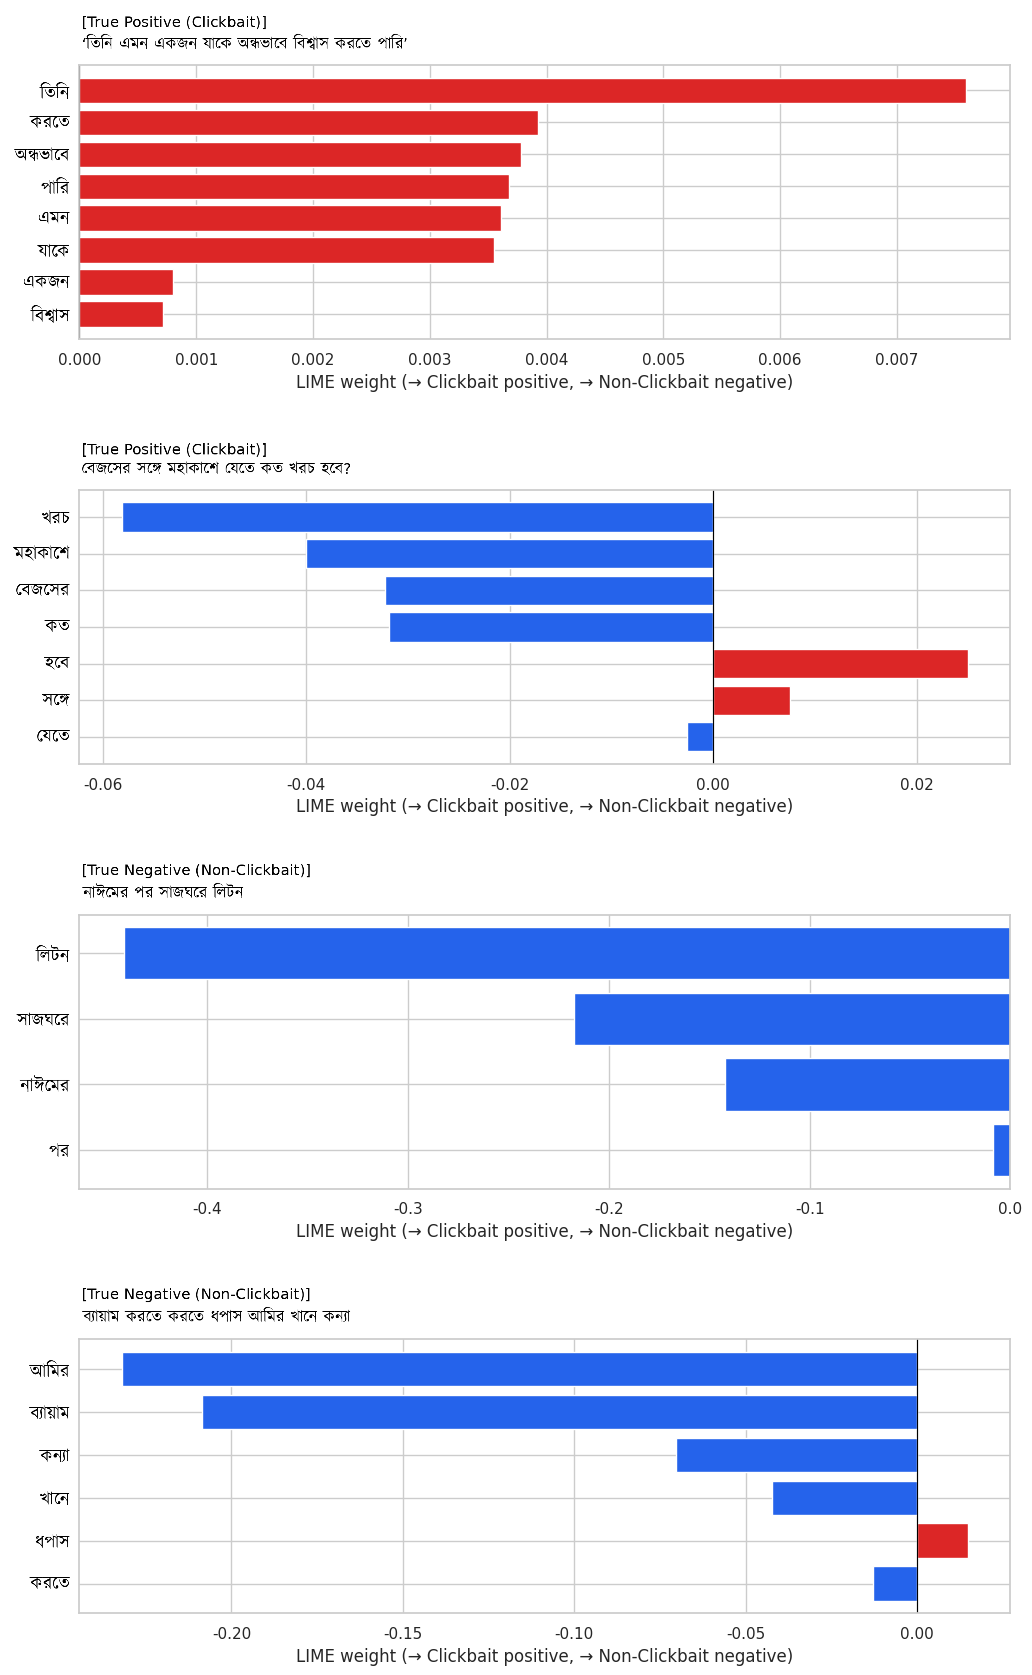

In [61]:
# ── 21.3  LIME local explanations for the selected samples ────────
from lime.lime_text import LimeTextExplainer

# FIX: LIME's default split_expression r"\W+" treats Bangla vowel signs / virama as
# non-word characters and shreds words into fragments (e.g. "দেখুন" → "দ", "খ", "ন").
# Split on whitespace and punctuation only, so whole Bangla words are the explained features.
LIME_SPLIT_EXPR = r"[\s।,;:!?()\[\]{}\"'‘’“”]+"

def make_lime_explainer():
    return LimeTextExplainer(class_names=LABEL_NAMES, split_expression=LIME_SPLIT_EXPR,
                             random_state=SEED)

if predict_proba_fn is not None and sample_idx:
    explainer = make_lime_explainer()
    lime_explanations = []
    for i, kind in zip(sample_idx, sample_labels):
        text = X_ts[i]
        exp = explainer.explain_instance(text, predict_proba_fn, num_features=10, num_samples=300)
        lime_explanations.append((text, kind, exp))

    n_exp = len(lime_explanations)
    fig, axes = plt.subplots(n_exp, 1, figsize=(10.5, 4.3 * n_exp))
    axes = np.atleast_1d(axes)
    widest = 0.0
    for ax, (text, kind, exp) in zip(axes, lime_explanations):
        weights = exp.as_list()
        words  = [w for w, _ in weights][::-1]
        scores = [s for _, s in weights][::-1]
        colors = ["#DC2626" if s > 0 else "#2563EB" for s in scores]
        ax.barh(range(len(words)), scores, color=colors)
        widest = max(widest, set_bengali_yticklabels(ax, words, fontsize=13))    # shaped Bengali words
        ax.axvline(0, color="black", linewidth=0.8)
        # Bengali title (wrapped, mixed with English tag) drawn as shaped text above the axes
        draw_bengali_text(ax, 0.0, 1.04, f"[{kind}]\n" + wrap_bengali_text(text, width=60),
                          fontsize=12, ha="left", va="bottom", transform=ax.transAxes)
        ax.set_xlabel("LIME weight (→ Clickbait positive, → Non-Clickbait negative)")
    reserve_left_margin(fig, widest, top=0.94, bottom=0.04, hspace=0.55)
    plt.savefig(f"{SAVE_DIR}/fig_21_lime_local_explanations.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("Skipped — no predict_proba wrapper / no qualifying samples available.")


In [62]:
# ── 21.4  SHAP local explanations (text masker + KernelExplainer-style) ──
import shap

if predict_proba_fn is not None and sample_idx:
    masker = shap.maskers.Text(tokenizer=r"\s+")  # whitespace-only split; \W+ shreds Bangla conjuncts/matras
    shap_explainer = shap.Explainer(lambda x: predict_proba_fn(list(x)), masker,
                                     output_names=LABEL_NAMES)
    shap_values = shap_explainer([X_ts[i] for i in sample_idx], silent=True)
    for j, (i, kind) in enumerate(zip(sample_idx, sample_labels)):
        print(f"\n[{kind}]  {X_ts[i]}")
        # class-1 (Clickbait) attribution per token, real SHAP values
        vals = shap_values[j, :, 1].values
        toks = shap_values[j, :, 1].data
        for tok, val in sorted(zip(toks, vals), key=lambda t: -abs(t[1]))[:8]:
            print(f"    {tok!r:20s}  shap={val:+.4f}")
else:
    print("Skipped — no predict_proba wrapper / no qualifying samples available.")


[True Positive (Clickbait)]  ‘তিনি এমন একজন যাকে অন্ধভাবে বিশ্বাস করতে পারি’
    '‘তিনি '              shap=+0.0317
    'করতে '               shap=+0.0284
    'পারি’'               shap=+0.0251
    'যাকে '               shap=+0.0216
    'এমন '                shap=+0.0188
    'অন্ধভাবে '           shap=+0.0168
    'একজন '               shap=+0.0127
    'বিশ্বাস '            shap=+0.0029

[True Positive (Clickbait)]  বেজসের সঙ্গে মহাকাশে যেতে কত খরচ হবে?
    'খরচ '                shap=-0.0300
    'হবে?'                shap=+0.0142
    'কত '                 shap=+0.0109
    'মহাকাশে '            shap=-0.0101
    'সঙ্গে '              shap=+0.0077
    'বেজসের '             shap=-0.0011
    'যেতে '               shap=-0.0005

[True Negative (Non-Clickbait)]  নাঈমের পর সাজঘরে লিটন
    'লিটন'                shap=-0.3057
    'সাজঘরে '             shap=-0.2108
    'নাঈমের '             shap=-0.1335
    'পর '                 shap=-0.0614

[True Negative (Non-Clickbait)]  ব্যায়াম করতে করতে ধপাস 

## 🌐 Section 22 — Global Feature Importance — Top-Performing Model
For a **linear** top model (TF-IDF + LogReg/LinearSVC), this reports the
model's **exact learned coefficients** — no approximation needed. For a
**black-box** top model (transformer / ensemble / TigerLLM), exact global
coefficients don't exist, so global importance is approximated by
**averaging LIME attributions over a random sample of test instances** —
a standard, documented aggregation-of-local-explanations technique, reported
here as an approximation, not as exact model internals.

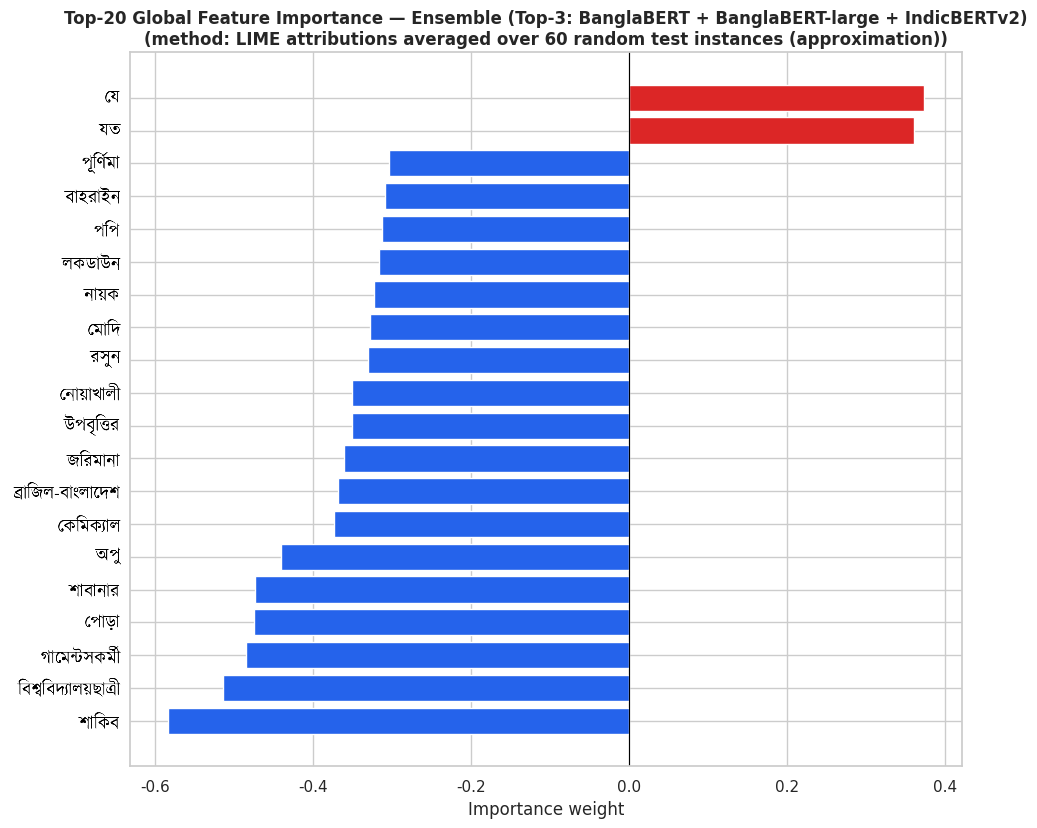

             feature  weight  n_occurrences
               শাকিব -0.5843              1
বিশ্ববিদ্যালয়ছাত্রী -0.5138              1
       গামেন্টসকর্মী -0.4850              1
                পোড়া -0.4756              1
             শাবানার -0.4732              1
                 অপু -0.4409              1
           কেমিক্যাল -0.3732              1
    ব্রাজিল-বাংলাদেশ -0.3681              1
             জরিমানা -0.3615              1
           উপবৃত্তির -0.3510              1
            নোয়াখালী -0.3503              1
                রসুন -0.3300              1
                মোদি -0.3276              1
                নায়ক -0.3232              1
              লকডাউন -0.3171              1
                 পপি -0.3125              2
             বাহরাইন -0.3095              1
            পূর্ণিমা -0.3042              1
                  যত  0.3609              1
                  যে  0.3740              1


In [63]:
# ── 22.1  Global importance: exact coefficients OR aggregated LIME ──
N_GLOBAL_SAMPLES = 60   # instances aggregated for the black-box-model case; raise for a tighter estimate

def global_importance_linear(clf, vectorizer, top_k=20):
    vocab = np.array(vectorizer.get_feature_names_out())
    coefs = clf.coef_.ravel()
    order = np.argsort(np.abs(coefs))[::-1][:top_k]
    return pd.DataFrame({"feature": vocab[order], "weight": coefs[order]}).sort_values("weight")

def global_importance_blackbox(predict_fn, texts, top_k=20, n_samples=N_GLOBAL_SAMPLES, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(texts), size=min(n_samples, len(texts)), replace=False)
    explainer = make_lime_explainer()          # whitespace/punctuation split — keeps Bangla words whole (Section 21.3)
    agg = {}
    for i in idx:
        exp = explainer.explain_instance(texts[i], predict_fn, num_features=15, num_samples=150)
        for word, w in exp.as_list():
            agg.setdefault(word, []).append(w)
    rows = [{"feature": w, "weight": float(np.mean(v)), "n_occurrences": len(v)} for w, v in agg.items()]
    df = pd.DataFrame(rows).sort_values("weight", key=abs, ascending=False).head(top_k)
    return df.sort_values("weight")

if top_key in classical_models:
    global_imp_df = global_importance_linear(classical_models[top_key], tfidf, top_k=20)
    method_note = "exact model coefficients"
elif predict_proba_fn is not None:
    global_imp_df = global_importance_blackbox(predict_proba_fn, list(X_ts), top_k=20)
    method_note = f"LIME attributions averaged over {N_GLOBAL_SAMPLES} random test instances (approximation)"
else:
    global_imp_df, method_note = pd.DataFrame(), "unavailable"

if not global_imp_df.empty:
    fig, ax = plt.subplots(figsize=(10, 8.5))
    colors = ["#DC2626" if w > 0 else "#2563EB" for w in global_imp_df["weight"]]
    ax.barh(range(len(global_imp_df)), global_imp_df["weight"], color=colors)
    label_w = set_bengali_yticklabels(ax, global_imp_df["feature"], fontsize=13)   # shaped Bengali features
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Importance weight")
    ax.set_title(f"Top-20 Global Feature Importance — {top_key}\n(method: {method_note})", fontweight="bold")
    reserve_left_margin(fig, label_w, top=0.91, bottom=0.07)
    plt.savefig(f"{SAVE_DIR}/fig_22_global_feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(global_imp_df.to_string(index=False))
else:
    print("Skipped — no global importance available for this model.")


## 🩺 Section 23 — Comprehensive Error Diagnostics — All 12 Models
TP/TN/FP/FN breakdown, a linguistic error taxonomy, calibration (ECE +
reliability diagrams), and hard/adversarial samples — computed from the real
`ALL_PREDS` / `ALL_PROBS` populated in Sections 7–10. Nothing below is
hand-entered: every number is recomputed from those dictionaries when this
cell runs, so results always reflect whatever is actually in the live kernel.

In [64]:
# ── 23.1  TP / TN / FP / FN per model (all 12) ─────────────────────
y_arr = np.array(y_ts)
confusion_rows = []
for name, preds in ALL_PREDS.items():
    p = np.array(preds)
    tp = int(np.sum((p == 1) & (y_arr == 1)))
    tn = int(np.sum((p == 0) & (y_arr == 0)))
    fp = int(np.sum((p == 1) & (y_arr == 0)))
    fn = int(np.sum((p == 0) & (y_arr == 1)))
    confusion_rows.append({"Model": name, "TP": tp, "TN": tn, "FP": fp, "FN": fn,
                            "N": tp+tn+fp+fn})
confusion_df = pd.DataFrame(confusion_rows).sort_values("Model").reset_index(drop=True)
print(f"TP/TN/FP/FN across {len(confusion_df)} models:")
print(confusion_df.to_string(index=False))

TP/TN/FP/FN across 12 models:
                                                        Model  TP   TN  FP  FN    N
                               Bangla-BERT-Base (sagorsarker) 750 1582 359 297 2988
                                      BanglaBERT (csebuetnlp) 808 1615 326 239 2988
                                BanglaBERT-large (csebuetnlp) 861 1564 377 186 2988
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2) 810 1666 275 237 2988
                                                  IndicBERTv2 830 1629 312 217 2988
                                                   MuRIL-base 763 1622 319 284 2988
                                           TF-IDF + LinearSVC 692 1556 385 355 2988
                                  TF-IDF + LogisticRegression 723 1533 408 324 2988
                                       TigerLLM-1B-it (QLoRA) 684 1698 243 363 2988
                                             XLM-RoBERTa-base 804 1609 332 243 2988
                                            XL

Error taxonomy breakdown (heuristic — see note above):
                                                        Model  Total errors  Sensationalism  Ambiguity  Sarcasm  Unclassified
                               Bangla-BERT-Base (sagorsarker)           656             150         38       13           475
                                      BanglaBERT (csebuetnlp)           565             150         36        8           388
                                BanglaBERT-large (csebuetnlp)           563             147         38        8           387
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)           512             129         33        9           356
                                                  IndicBERTv2           529             124         34        9           375
                                                   MuRIL-base           603             146         41       11           426
                                           TF-IDF + LinearSVC  

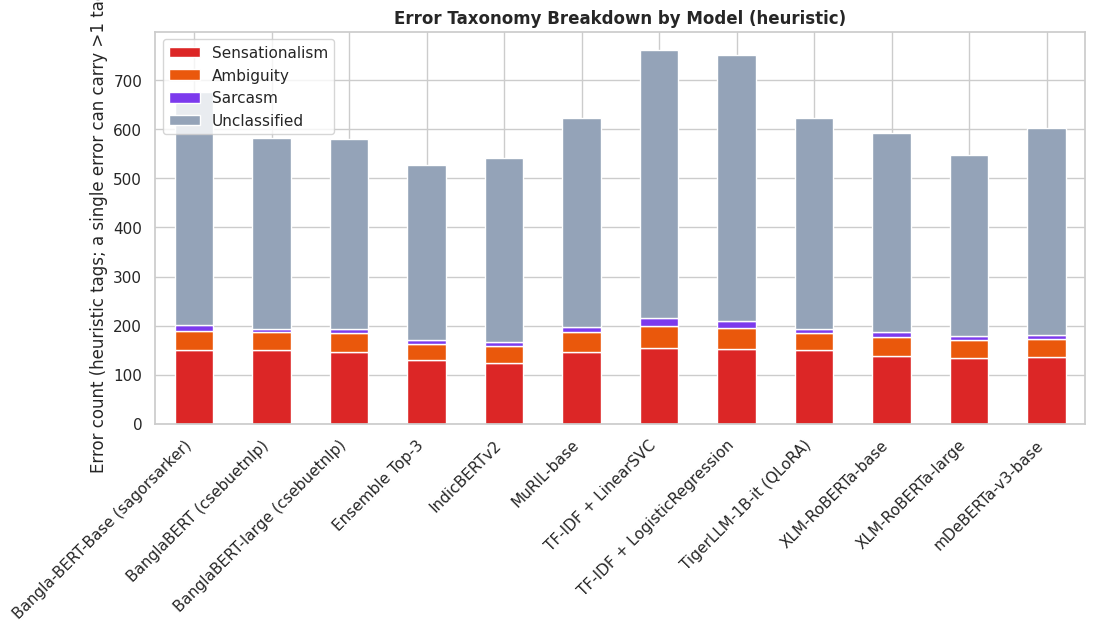

In [65]:
# ── 23.2  Linguistic error taxonomy (heuristic, documented as such) ──
# IMPORTANT: these are transparent, rule-based heuristics over surface text
# features (reusing the punctuation/length/trigger-word signals from Sections
# 16-18), NOT a validated or human-annotated taxonomy. Sarcasm in particular
# is very hard to detect from surface patterns — treat that bucket as the
# least reliable of the three, and consider a human-annotated subset (with
# inter-annotator agreement) before reporting these counts in a paper.
_median_wordcount = len_df["word_count"].median()
_sensational_terms = set(trigger_df.loc[trigger_df["association"] == "Clickbait", "ngram"])
_contrast_markers  = ["কিন্তু", "তবে", "অথচ", "যদিও"]   # Bangla contrastive conjunctions (but/however/yet/although)

def tag_error_taxonomy(title):
    tags = []
    lower = title.lower()
    if any(term in lower for term in _sensational_terms) or title.count("!") > 0:
        tags.append("Sensationalism")
    if len(title.split()) <= _median_wordcount * 0.6:
        tags.append("Ambiguity")
    if any(mk in title for mk in _contrast_markers) or ('"' in title or "'" in title):
        tags.append("Sarcasm")
    return tags if tags else ["Unclassified"]

taxonomy_rows = []
for name, preds in ALL_PREDS.items():
    p = np.array(preds)
    err_mask = p != y_arr
    err_idx  = np.where(err_mask)[0]
    counts = {"Sensationalism": 0, "Ambiguity": 0, "Sarcasm": 0, "Unclassified": 0}
    for i in err_idx:
        for tag in tag_error_taxonomy(X_ts[i]):
            counts[tag] += 1
    counts["Model"] = name
    counts["Total errors"] = len(err_idx)
    taxonomy_rows.append(counts)

taxonomy_df = pd.DataFrame(taxonomy_rows)[["Model", "Total errors", "Sensationalism", "Ambiguity",
                                            "Sarcasm", "Unclassified"]].sort_values("Model")
print("Error taxonomy breakdown (heuristic — see note above):")
print(taxonomy_df.to_string(index=False))

def _short_model_name(name, max_len=35):
    """Shorten only for chart tick labels (tables/text keep the full name) —
    the Ensemble's full member list otherwise collides with the y-axis title."""
    if name.startswith("Ensemble ("):
        n = name.split("Top-", 1)[1].split(":", 1)[0].strip() if "Top-" in name else "?"
        return f"Ensemble Top-{n}"
    return name if len(name) <= max_len else name[:max_len - 1] + "…"

fig, ax = plt.subplots(figsize=(12, 7))
tax_plot = taxonomy_df.set_index("Model")[["Sensationalism", "Ambiguity", "Sarcasm", "Unclassified"]]
tax_plot.index = [_short_model_name(m) for m in tax_plot.index]
tax_plot.plot(kind="bar", stacked=True, ax=ax,
              color=["#DC2626", "#EA580C", "#7C3AED", "#94A3B8"])
ax.set_ylabel("Error count (heuristic tags; a single error can carry >1 tag)")
ax.set_title("Error Taxonomy Breakdown by Model (heuristic)", fontweight="bold")
plt.xticks(rotation=45, ha="right")
fig.subplots_adjust(bottom=0.32)
plt.savefig(f"{SAVE_DIR}/fig_23_error_taxonomy.png", dpi=150, bbox_inches="tight")
plt.show()

Note: TigerLLM-1B-it excluded from ECE — it is a generation-based classifier with no native calibrated probability output (see Section 10.6).


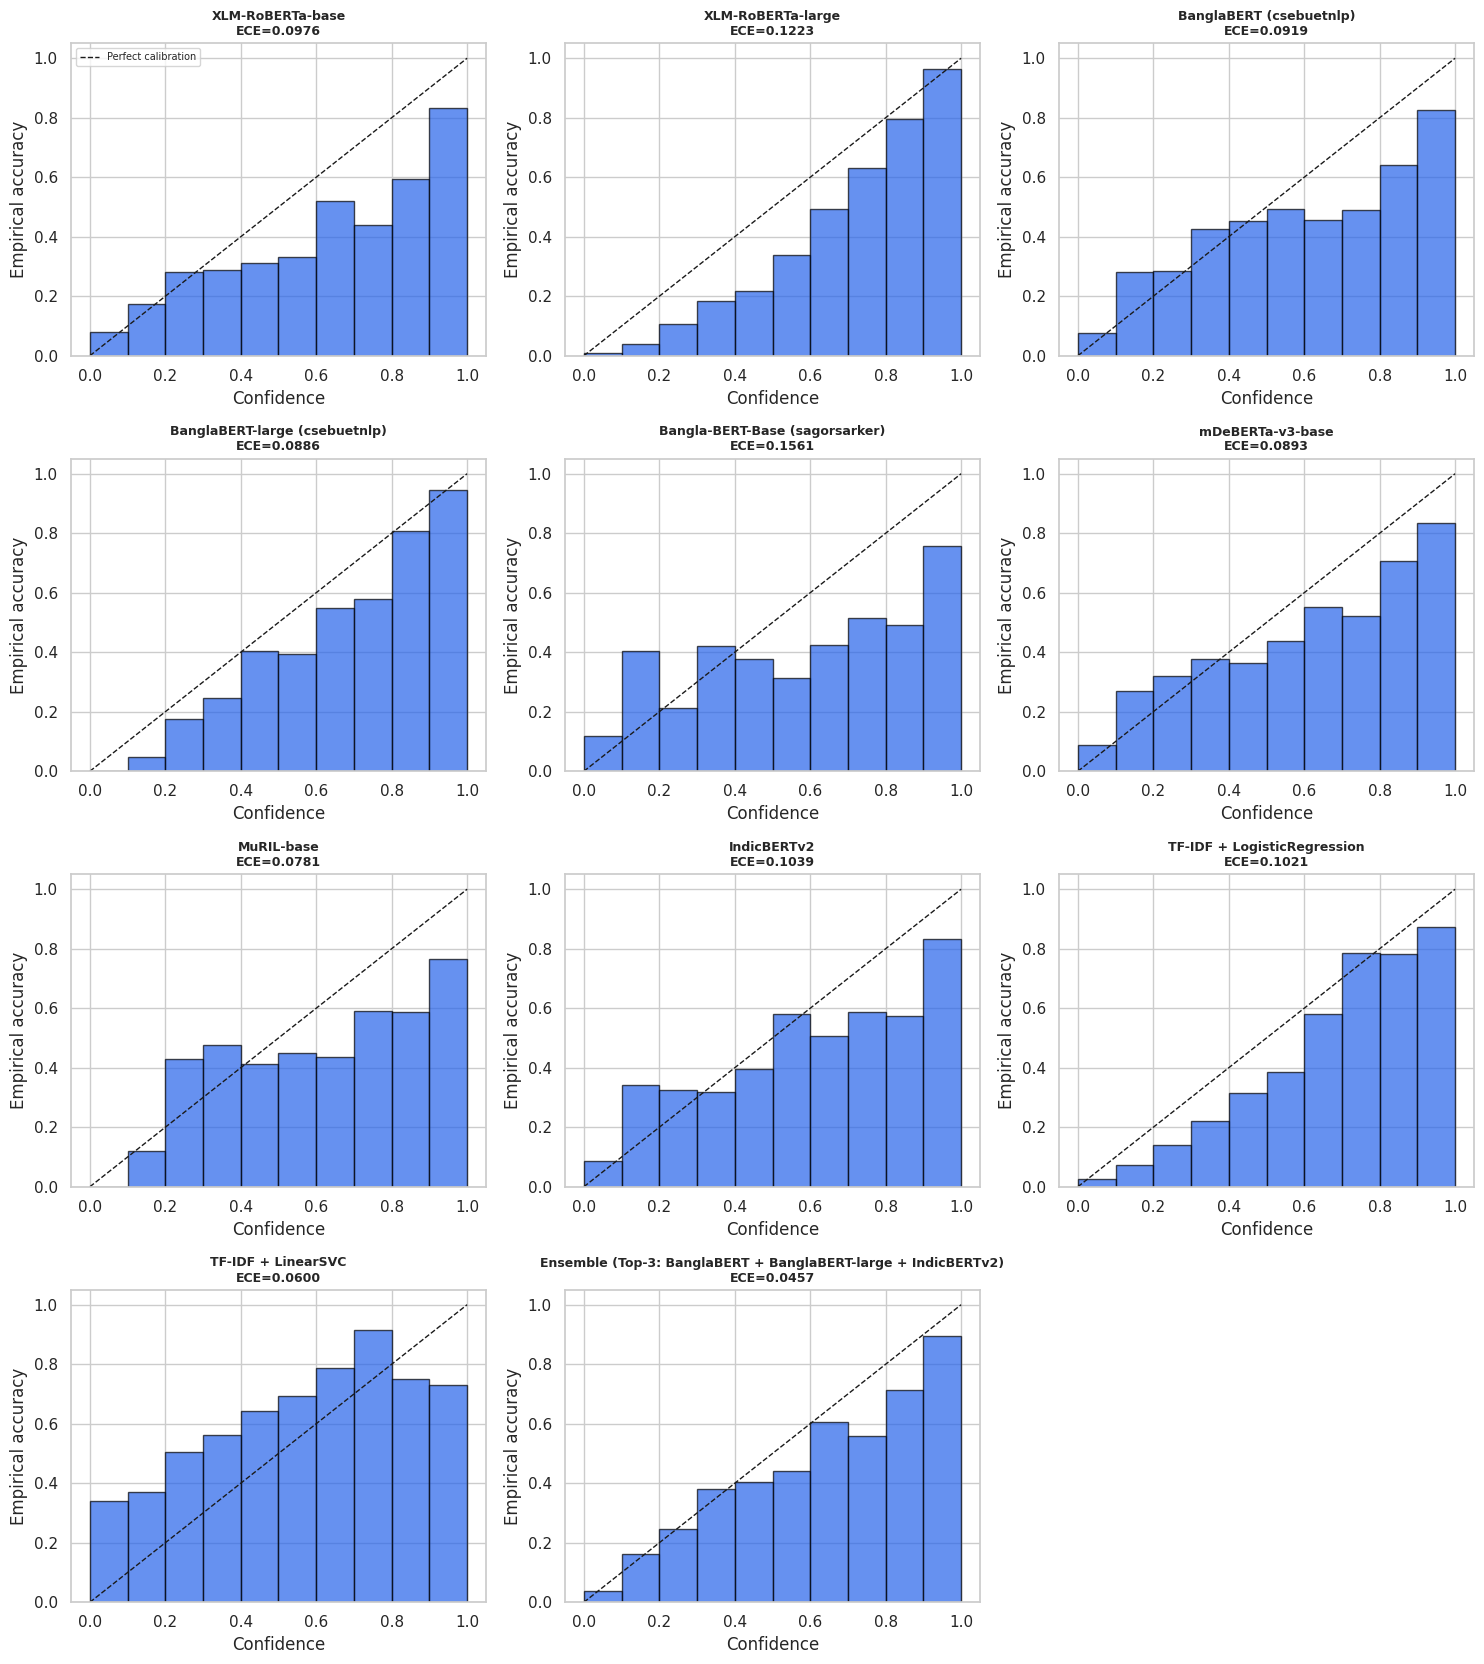


Expected Calibration Error (10 bins) by model:
                                                        Model    ECE
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2) 0.0457
                                           TF-IDF + LinearSVC 0.0600
                                                   MuRIL-base 0.0781
                                BanglaBERT-large (csebuetnlp) 0.0886
                                             mDeBERTa-v3-base 0.0893
                                      BanglaBERT (csebuetnlp) 0.0919
                                             XLM-RoBERTa-base 0.0976
                                  TF-IDF + LogisticRegression 0.1021
                                                  IndicBERTv2 0.1039
                                            XLM-RoBERTa-large 0.1223
                               Bangla-BERT-Base (sagorsarker) 0.1561


In [66]:
# ── 23.3  Expected Calibration Error + reliability diagrams ───────
def expected_calibration_error(y_true, y_prob, n_bins=10):
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    n = len(y_true)
    ece, bin_stats = 0.0, []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob > lo) & (y_prob <= hi) if lo > 0 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() == 0:
            bin_stats.append((lo, hi, 0, np.nan, np.nan)); continue
        conf, acc = y_prob[mask].mean(), y_true[mask].mean()
        w = mask.sum() / n
        ece += w * abs(acc - conf)
        bin_stats.append((lo, hi, int(mask.sum()), conf, acc))
    return ece, bin_stats

models_with_probs = list(ALL_PROBS.keys())   # all except TigerLLM (no continuous score — see Section 10.6)
ece_rows = []
n_cols = 3
n_rows = int(np.ceil(len(models_with_probs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4.2*n_rows))
axes = np.array(axes).reshape(-1)

for ax, name in zip(axes, models_with_probs):
    labels_m, probs_m = ALL_PROBS[name]
    ece, bin_stats = expected_calibration_error(labels_m, probs_m)
    ece_rows.append({"Model": name, "ECE": ece})
    bins = np.linspace(0, 1, 11)
    accs = [b[4] if not np.isnan(b[4]) else 0 for b in bin_stats]
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect calibration")
    ax.bar(bins[:-1], accs, width=0.1, align="edge", alpha=0.7,
           edgecolor="black", color="#2563EB")
    ax.set_title(f"{name}\nECE={ece:.4f}", fontsize=9, fontweight="bold")
    ax.set_xlabel("Confidence"); ax.set_ylabel("Empirical accuracy")

for ax in axes[len(models_with_probs):]:
    ax.axis("off")
axes[0].legend(fontsize=7)

if "TigerLLM-1B-it (QLoRA)" in ALL_PREDS and "TigerLLM-1B-it (QLoRA)" not in ALL_PROBS:
    print("Note: TigerLLM-1B-it excluded from ECE — it is a generation-based classifier with "
          "no native calibrated probability output (see Section 10.6).")

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_23_reliability_diagrams.png", dpi=150, bbox_inches="tight")
plt.show()

ece_df = pd.DataFrame(ece_rows).sort_values("ECE")
print("\nExpected Calibration Error (10 bins) by model:")
print(ece_df.to_string(index=False))

In [67]:
# ── 23.4  Hard / adversarial samples (high-confidence WRONG predictions) ──
N_HARD_PER_MODEL = 5
hard_rows = []
for name in models_with_probs:
    labels_m, probs_m = ALL_PROBS[name]
    labels_m, probs_m = np.array(labels_m), np.array(probs_m)
    preds_m = (probs_m >= 0.5).astype(int)
    wrong = preds_m != labels_m
    confidence = np.abs(probs_m - 0.5) * 2      # 0 = uncertain, 1 = maximally confident
    wrong_idx = np.where(wrong)[0]
    top_wrong = wrong_idx[np.argsort(-confidence[wrong_idx])][:N_HARD_PER_MODEL]
    for i in top_wrong:
        hard_rows.append({
            "Model": name, "title": X_ts[i], "true_label": LABEL_NAMES[int(labels_m[i])],
            "predicted_label": LABEL_NAMES[int(preds_m[i])],
            "predicted_prob_clickbait": float(probs_m[i]), "confidence": float(confidence[i]),
        })
hard_df = pd.DataFrame(hard_rows).sort_values(["Model", "confidence"], ascending=[True, False])
print(f"Top-{N_HARD_PER_MODEL} highest-confidence WRONG predictions per model "
      f"({len(models_with_probs)} models with probability scores):")
print(hard_df.to_string(index=False))

# Samples that are hard across MANY models simultaneously = the truly adversarial cases
cross_model_hard = (hard_df.groupby("title")
                    .agg(n_models_fooled=("Model", "nunique"),
                         true_label=("true_label", "first"),
                         avg_confidence=("confidence", "mean"))
                    .sort_values(["n_models_fooled", "avg_confidence"], ascending=False))
print("\nSamples appearing in the hard-sample list for the most models (cross-model adversarial cases):")
print(cross_model_hard.head(10).to_string())

Top-5 highest-confidence WRONG predictions per model (11 models with probability scores):
                                                        Model                                                                                  title    true_label predicted_label  predicted_prob_clickbait  confidence
                               Bangla-BERT-Base (sagorsarker)                               ক্রিকেটার সাকিব কে নিয়ে নায়ক শাকিবের যে স্ট্যাটাস ভাইরাল Non-Clickbait       Clickbait                    0.9986      0.9972
                               Bangla-BERT-Base (sagorsarker)                                        ‘আমি কিছু জানি না, হেটার্সরা বলবে প্রেগন্যান্ট’ Non-Clickbait       Clickbait                    0.9986      0.9971
                               Bangla-BERT-Base (sagorsarker)                     হায় হায় হায়, সেমিফাইনালে খেলতে দুধের শিশুদের দিকেই তাকিয়ে ভারতীয়রা     Clickbait   Non-Clickbait                    0.0015      0.9970
                               Bangla-BERT

## ✂️ Section 24 — Feature-Level Ablation Study — All 12 Models
**Primary analysis (runs for all 12 models):** inference-time robustness —
each *already-trained* model is re-evaluated on stopword-removed /
punctuation-removed / both-removed **test-set text**, using the same
`get_predict_proba_fn` dispatcher from Section 21. This measures how
sensitive each trained model's predictions are to those features being
stripped from the input.

**Bonus (2 classical models only, since it's cheap):** true train-time
ablation — TF-IDF + classifier are *refit from scratch* on ablated
**training** text. This is the methodologically stronger comparison, but
re-fine-tuning all 8 transformers + ensemble + TigerLLM from scratch three
more times each is a genuinely heavy GPU workload — a ready-to-adapt function
for that is provided at the end of this section for anyone with the compute
budget to run it, but it is not auto-executed here.

Bangla-aware stopword / punctuation lists come from `bnlp_toolkit`
(`BengaliCorpus.stopwords`, `.punctuations`), not an invented list.

In [68]:
# ── 24.0  Install bnlp_toolkit for a real Bangla stopword/punctuation list ──
!pip install -q bnlp_toolkit
import string
from bnlp import BengaliCorpus as bn_corpus

BN_STOPWORDS    = set(bn_corpus.stopwords)
BN_PUNCTUATION  = set(bn_corpus.punctuations) | set(string.punctuation)
print(f"Loaded {len(BN_STOPWORDS)} Bangla stopwords and {len(BN_PUNCTUATION)} punctuation "
      f"characters from bnlp_toolkit.")

def ablate_stopwords(text):
    return " ".join(w for w in text.split() if w not in BN_STOPWORDS)

def ablate_punctuation(text):
    return "".join(ch for ch in text if ch not in BN_PUNCTUATION)

def ablate_both(text):
    return ablate_punctuation(ablate_stopwords(text))

ABLATIONS = {
    "Baseline": lambda t: t,
    "No-Stopwords": ablate_stopwords,
    "No-Punctuation": ablate_punctuation,
    "Stripped (Both)": ablate_both,
}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 941.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 44.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
normalizer 0.0.1 requires emoji==1.4.2, but you have emoji 2.16.0 which is incompatible.
normalizer 0.0.1 requires ftfy==6.0.3, but you have ftfy 6.3.1 which is incompatible.
Loaded 398 Bangla stopwords and 34 punctuation characters from bnlp_toolkit.


In [69]:
# ── 24.1  Inference-time ablation across all 12 models (real, auto-run) ──
ablation_rows = []
all_model_names = list(ALL_PREDS.keys())

for name in all_model_names:
    proba_fn = get_predict_proba_fn(name)
    if proba_fn is None:
        print(f"⚠️  Skipping '{name}' — no predict_proba wrapper available.")
        continue
    row = {"Model": name}
    for cond_name, ablate_fn in ABLATIONS.items():
        ablated_texts = [ablate_fn(t) for t in X_ts]
        probs = proba_fn(ablated_texts)[:, 1]
        preds = (probs >= 0.5).astype(int)
        row[cond_name] = f1_score(y_ts, preds, average="macro", zero_division=0)
    ablation_rows.append(row)
    print(f"  ✓ {name}")
    del proba_fn                       # free the reloaded checkpoints before the next model
    gc.collect(); torch.cuda.empty_cache()

ablation_df = pd.DataFrame(ablation_rows)
for cond in ["No-Stopwords", "No-Punctuation", "Stripped (Both)"]:
    ablation_df[f"Δ {cond}"] = ablation_df[cond] - ablation_df["Baseline"]

print("\nInference-time ablation — Macro-F1 by condition, all models:")
print(ablation_df.round(4).to_string(index=False))

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ✓ XLM-RoBERTa-base


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ✓ XLM-RoBERTa-large


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

  ✓ MuRIL-base


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  ✓ IndicBERTv2
  ✓ TF-IDF + LogisticRegression
  ✓ TF-IDF + LinearSVC


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream ta

  ✓ Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)
  ✓ TigerLLM-1B-it (QLoRA)

Inference-time ablation — Macro-F1 by condition, all models:
                                                        Model  Baseline  No-Stopwords  No-Punctuation  Stripped (Both)  Δ No-Stopwords  Δ No-Punctuation  Δ Stripped (Both)
                                             XLM-RoBERTa-base    0.7918        0.7472          0.7790           0.7242         -0.0446           -0.0128            -0.0676
                                            XLM-RoBERTa-large    0.7933        0.7590          0.7866           0.7495         -0.0343           -0.0067            -0.0438
                                      BanglaBERT (csebuetnlp)    0.7972        0.7661          0.7834           0.7455         -0.0312           -0.0139            -0.0518
                                BanglaBERT-large (csebuetnlp)    0.8038        0.7647          0.7897           0.7430         -0.0390           -0.0141     

In [70]:
# ── 24.2  BONUS: true train-time ablation for the 2 classical models ──
def refit_ablated(ablate_fn, C_logreg=2.0, C_svc=1.0):
    Xtr_a = [ablate_fn(t) for t in X_tr]
    Xts_a = [ablate_fn(t) for t in X_ts]
    vec = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), sublinear_tf=True,
                          token_pattern=BN_TOKEN_PATTERN)   # same Bangla-aware tokenisation as Section 8
    Xtr_v = vec.fit_transform(Xtr_a); Xts_v = vec.transform(Xts_a)
    out = {}
    lr = LogisticRegression(max_iter=2000, class_weight="balanced", C=C_logreg, random_state=SEED).fit(Xtr_v, y_tr)
    out["TF-IDF + LogReg"] = f1_score(y_ts, lr.predict(Xts_v), average="macro", zero_division=0)
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        svc = LinearSVC(class_weight="balanced", C=C_svc, random_state=SEED).fit(Xtr_v, y_tr)
    out["TF-IDF + LinearSVC"] = f1_score(y_ts, svc.predict(Xts_v), average="macro", zero_division=0)
    return out

train_time_rows = []
for cond_name, ablate_fn in ABLATIONS.items():
    scores = refit_ablated(ablate_fn)
    for model, f1 in scores.items():
        train_time_rows.append({"Model": model, "Condition": cond_name, "Macro-F1 (retrained)": f1})
train_time_ablation_df = pd.DataFrame(train_time_rows).pivot(
    index="Model", columns="Condition", values="Macro-F1 (retrained)")[list(ABLATIONS.keys())]
print("Train-time ablation (real refits from scratch) — classical models only:")
print(train_time_ablation_df.round(4).to_string())

Train-time ablation (real refits from scratch) — classical models only:
Condition           Baseline  No-Stopwords  No-Punctuation  Stripped (Both)
Model                                                                      
TF-IDF + LinearSVC    0.7297        0.7031          0.7334           0.7043
TF-IDF + LogReg       0.7356        0.7096          0.7387           0.7105


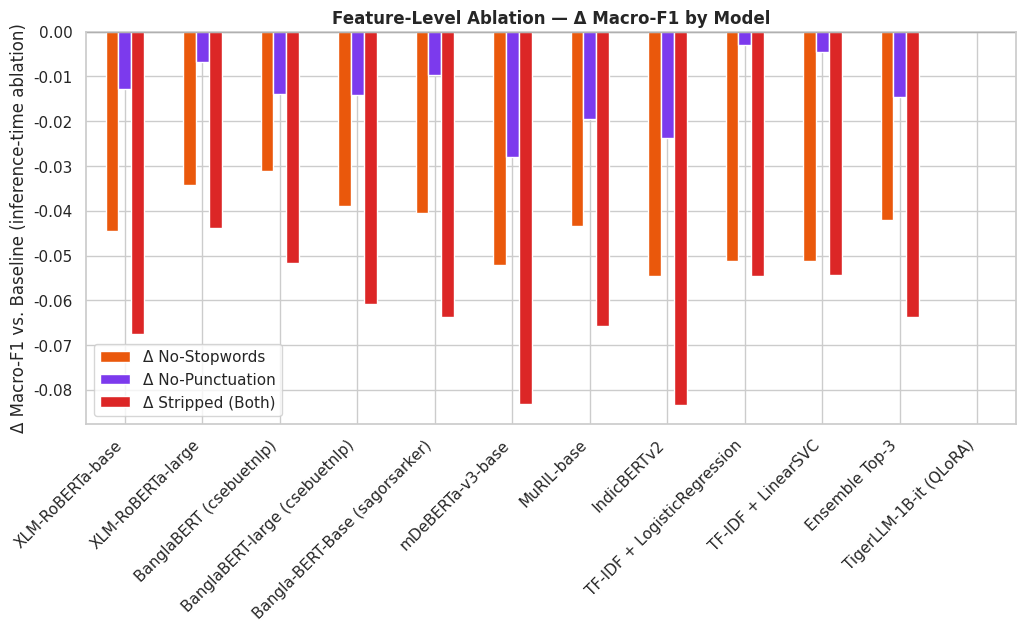

In [71]:
# ── 24.3  Combined ablation delta plot ─────────────────────────────
fig, ax = plt.subplots(figsize=(12, 7))
plot_df = ablation_df.set_index("Model")[["Δ No-Stopwords", "Δ No-Punctuation", "Δ Stripped (Both)"]]
plot_df.index = [_short_model_name(m) for m in plot_df.index]   # helper defined in Section 23.2
plot_df.plot(kind="bar", ax=ax, color=["#EA580C", "#7C3AED", "#DC2626"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Δ Macro-F1 vs. Baseline (inference-time ablation)")
ax.set_title("Feature-Level Ablation — Δ Macro-F1 by Model", fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.legend(title="")
fig.subplots_adjust(bottom=0.32)
plt.savefig(f"{SAVE_DIR}/fig_24_ablation_deltas.png", dpi=150, bbox_inches="tight")
plt.show()

In [72]:
# ── 24.4  OPTIONAL / not auto-run: full train-time ablation for the ──
# ── 8 transformer encoders + ensemble + TigerLLM (heavy GPU workload) ──
def run_full_retrain_ablation_for_transformers():
    """Re-fine-tunes every model in MODEL_REGISTRY from scratch, 3 extra times
    each (no-stopwords / no-punctuation / both), reusing train_model() exactly
    as Section 7 does. NOT called automatically — this is ~3x the total
    compute of Section 7 itself. Call manually if you have the GPU budget:
        full_ablation_results = run_full_retrain_ablation_for_transformers()
    """
    results = {}
    for cfg in MODEL_REGISTRY:
        tokenizer = AutoTokenizer.from_pretrained(cfg["model_id"])
        for cond_name, ablate_fn in list(ABLATIONS.items())[1:]:   # skip Baseline (already in ALL_RESULTS)
            print(f"Retraining {cfg['name']} — {cond_name} ...")
            Xtr_a = [ablate_fn(t) for t in X_tr]
            Xvl_a = [ablate_fn(t) for t in X_vl]
            Xts_a = [ablate_fn(t) for t in X_ts]
            base_model = AutoModelForSequenceClassification.from_pretrained(cfg["model_id"], num_labels=2)
            model = wrap_multi_gpu(base_model)
            tr_loader, vl_loader, ts_loader = make_loaders(
                Xtr_a, y_tr, Xvl_a, y_vl, Xts_a, y_ts, tokenizer, cfg,
                use_weighted_sampler=cfg.get("use_wrs", False))
            save_name = f"{cfg['save_name']}_{cond_name.replace(' ', '_')}"
            _, best_val_f1 = train_model(model, tr_loader, vl_loader, cfg,
                                          save_name=save_name, y_train=y_tr, loss_type=cfg["loss_type"])
            metrics, *_ = evaluate_model(model, ts_loader, f"{SAVE_DIR}/best_{save_name}.pt",
                                          title=f"{cfg['name']} [{cond_name}]")
            results[(cfg["name"], cond_name)] = metrics["macro_f1"]
            del model, base_model, tokenizer, tr_loader, vl_loader, ts_loader
            gpu_clear()
    return results

print("Defined run_full_retrain_ablation_for_transformers() — heavy, opt-in, not auto-executed.")

Defined run_full_retrain_ablation_for_transformers() — heavy, opt-in, not auto-executed.


## ⏱️ Section 25 — Computational Benchmark — All 12 Models
Real, measured (not estimated) latency, throughput, parameter counts, disk
footprint, and peak memory for every model. GPU-only metrics (VRAM) are
reported as N/A for CPU-only classical models rather than a fabricated 0 —
that's a real property of those models, not missing data.

In [73]:
# ── 25.1  Benchmark helper functions ───────────────────────────────
import psutil

def benchmark_classical(name, clf, n_timing=200):
    proc = psutil.Process(os.getpid())
    sample = tfidf.transform([X_ts[0]])
    t0 = time.perf_counter()
    for _ in range(n_timing):
        _ = clf.predict_proba(sample) if hasattr(clf, "predict_proba") else clf.decision_function(sample)
    elapsed = time.perf_counter() - t0
    ms_per_sample = (elapsed / n_timing) * 1000

    tmp = f"/tmp/_bench_{name.replace(' ', '_').replace('/', '_')}.pkl"
    with open(tmp, "wb") as f:
        pickle.dump({"tfidf": tfidf, "clf": clf}, f)
    size_mb = os.path.getsize(tmp) / (1024 * 1024)
    os.remove(tmp)

    n_params = int(clf.coef_.size + clf.intercept_.size) if hasattr(clf, "coef_") else np.nan
    return dict(Model=name, **{
        "Latency (ms/sample)": ms_per_sample,
        "Throughput (samples/s)": 1000 / ms_per_sample,
        "Learned coefficients": n_params,
        "Disk size (MB)": size_mb,
        "Peak VRAM (MB)": np.nan,   # CPU-only model — genuinely not applicable, not zero
        "Process RAM (MB)": proc.memory_info().rss / (1024 * 1024),
    })

def benchmark_transformer_like(name, n_timing=50):
    """Works for any single-checkpoint transformer encoder in MODEL_REGISTRY.
    (Ensemble / TigerLLM are handled separately below — different loading paths.)"""
    registry_by_name = {m["name"]: m for m in MODEL_REGISTRY}
    cfg = registry_by_name[name]
    tok  = AutoTokenizer.from_pretrained(cfg["model_id"])
    base = AutoModelForSequenceClassification.from_pretrained(cfg["model_id"], num_labels=2)
    model = wrap_multi_gpu(base)
    ckpt_path = f"{SAVE_DIR}/best_{cfg['save_name']}.pt"
    get_base_model(model).load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    n_params = sum(p.numel() for p in get_base_model(model).parameters())
    size_mb  = os.path.getsize(ckpt_path) / (1024 * 1024)

    enc = tok([X_ts[0]], truncation=True, padding=True, max_length=cfg["max_len"],
              return_tensors="pt").to(DEVICE)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(n_timing):
            _ = forward_logits(model, enc["input_ids"], enc["attention_mask"])
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    ms_per_sample = (elapsed / n_timing) * 1000
    peak_vram = (torch.cuda.max_memory_allocated() / (1024*1024)) if torch.cuda.is_available() else np.nan

    proc = psutil.Process(os.getpid())
    result = dict(Model=name, **{
        "Latency (ms/sample)": ms_per_sample,
        "Throughput (samples/s)": 1000 / ms_per_sample,
        "Learned coefficients": n_params,
        "Disk size (MB)": size_mb,
        "Peak VRAM (MB)": peak_vram,
        "Process RAM (MB)": proc.memory_info().rss / (1024 * 1024),
    })
    del model, base, tok
    gpu_clear()
    return result

print("✅ Benchmark helper functions defined")

✅ Benchmark helper functions defined


In [74]:
# ── 25.2  Run benchmark: classical models (real, cheap, auto-run) ──
bench_rows = [benchmark_classical(name, clf) for name, clf in classical_models.items()]
for r in bench_rows:
    print(f"  ✓ {r['Model']}: {r['Latency (ms/sample)']:.4f} ms/sample")

  ✓ TF-IDF + LogisticRegression: 0.1486 ms/sample
  ✓ TF-IDF + LinearSVC: 0.1017 ms/sample


In [75]:
# ── 25.3  Run benchmark: 8 transformer encoders (real; reloads each checkpoint) ──
for cfg in MODEL_REGISTRY:
    try:
        r = benchmark_transformer_like(cfg["name"])
        bench_rows.append(r)
        print(f"  ✓ {cfg['name']}: {r['Latency (ms/sample)']:.4f} ms/sample, "
              f"{r['Learned coefficients']/1e6:.1f}M params")
    except Exception as e:
        print(f"  ⚠️  Skipped {cfg['name']} — {type(e).__name__}: {str(e)[:150]}")

# Ensemble Top-3 — latency/VRAM of running all 3 members sequentially per sample
ens_key = next((k for k in ALL_PREDS if k.startswith("Ensemble (")), None)
if ens_key:
    proba_fn = get_predict_proba_fn(ens_key)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(20):
        _ = proba_fn([X_ts[0]])
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = (time.perf_counter() - t0) / 20 * 1000
    peak_vram = (torch.cuda.max_memory_allocated()/(1024*1024)) if torch.cuda.is_available() else np.nan
    proc = psutil.Process(os.getpid())
    bench_rows.append(dict(Model=ens_key, **{
        "Latency (ms/sample)": elapsed, "Throughput (samples/s)": 1000/elapsed,
        "Learned coefficients": np.nan,  # sum of 3 independently-sized models — see notes
        "Disk size (MB)": np.nan, "Peak VRAM (MB)": peak_vram,
        "Process RAM (MB)": proc.memory_info().rss/(1024*1024),
    }))
    print(f"  ✓ {ens_key}: {elapsed:.4f} ms/sample (3 forward passes)")
    del proba_fn
    gc.collect(); torch.cuda.empty_cache()

# TigerLLM-1B-it — real generate() timing, reusing the exact call from Section 10.6.
# It's normally deleted from memory by this point (freed for GPU room after Section
# 10), so reload its adapter here instead of silently skipping it — same reload
# pattern as the TigerLLM branch of get_predict_proba_fn in Section 21.1.
_tiger_bench_mdl, _tiger_bench_tok = None, None
if TIGER_AVAILABLE and "tiger_model" in globals():
    _tiger_bench_mdl, _tiger_bench_tok = tiger_model, tiger_tokenizer
elif TIGER_AVAILABLE:
    try:
        _base = AutoModelForCausalLM.from_pretrained(
            TIGER_MODEL_ID, quantization_config=bnb_config,
            device_map={"": torch.cuda.current_device() if torch.cuda.is_available() else 0},
            attn_implementation="eager")
        _tiger_bench_tok = AutoTokenizer.from_pretrained(TIGER_MODEL_ID)
        if _tiger_bench_tok.pad_token is None:
            _tiger_bench_tok.pad_token = _tiger_bench_tok.eos_token
        _tiger_bench_mdl = PeftModel.from_pretrained(_base, f"{SAVE_DIR}/tigerllm_lora_adapter")
        _tiger_bench_mdl.eval()
        print("  (reloaded TigerLLM-1B-it for benchmarking — it had been freed after Section 10)")
    except Exception as e:
        print(f"  ⚠️  Could not reload TigerLLM-1B-it for benchmarking — {type(e).__name__}: {str(e)[:150]}")

if _tiger_bench_mdl is not None:
    prompt = build_prompt(X_ts[0])
    inputs = _tiger_bench_tok(prompt, return_tensors="pt").to(_tiger_bench_mdl.device)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(10):
        _ = _tiger_bench_mdl.generate(**inputs, max_new_tokens=TIGER_MAX_NEW_TOKENS, do_sample=False,
                                      pad_token_id=_tiger_bench_tok.pad_token_id, use_cache=True)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = (time.perf_counter() - t0) / 10 * 1000
    peak_vram = (torch.cuda.max_memory_allocated()/(1024*1024)) if torch.cuda.is_available() else np.nan
    n_params = sum(p.numel() for p in _tiger_bench_mdl.parameters())
    proc = psutil.Process(os.getpid())
    bench_rows.append(dict(Model="TigerLLM-1B-it (QLoRA)", **{
        "Latency (ms/sample)": elapsed, "Throughput (samples/s)": 1000/elapsed,
        "Learned coefficients": n_params, "Disk size (MB)": np.nan,
        "Peak VRAM (MB)": peak_vram, "Process RAM (MB)": proc.memory_info().rss/(1024*1024),
    }))
    print(f"  ✓ TigerLLM-1B-it: {elapsed:.4f} ms/sample (generation, up to {TIGER_MAX_NEW_TOKENS} new tokens)")
else:
    print("  ⚠️  TigerLLM unavailable in this session — skipped.")

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 10.71 GB free
  ✓ XLM-RoBERTa-base: 16.4624 ms/sample, 278.0M params


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 10.71 GB free
  ✓ XLM-RoBERTa-large: 30.1655 ms/sample, 559.9M params


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

  GPU cleared — 10.71 GB free
  ✓ MuRIL-base: 15.6960 ms/sample, 237.6M params


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  GPU cleared — 10.71 GB free
  ✓ IndicBERTv2: 16.0599 ms/sample, 278.0M params


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-Sam-TLM and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream ta

  ✓ Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2): 91.3622 ms/sample (3 forward passes)
  (reloaded TigerLLM-1B-it for benchmarking — it had been freed after Section 10)
  ✓ TigerLLM-1B-it: 453.1709 ms/sample (generation, up to 12 new tokens)


Computational benchmark — all available models:
                                                        Model  Latency (ms/sample)  Throughput (samples/s)  Learned coefficients  Disk size (MB)  Peak VRAM (MB)  Process RAM (MB)
                                           TF-IDF + LinearSVC               0.1017               9834.5253            30001.0000          1.8308             NaN         4209.0859
                                  TF-IDF + LogisticRegression               0.1486               6727.5558            30001.0000          1.8309             NaN         4209.0859
                               Bangla-BERT-Base (sagorsarker)              15.4973                 64.5275        164398082.0000        627.2099       4600.0664         4213.1055
                                                   MuRIL-base              15.6960                 63.7106        237557762.0000        906.2898       4879.1650         4252.5273
                                                  IndicBE

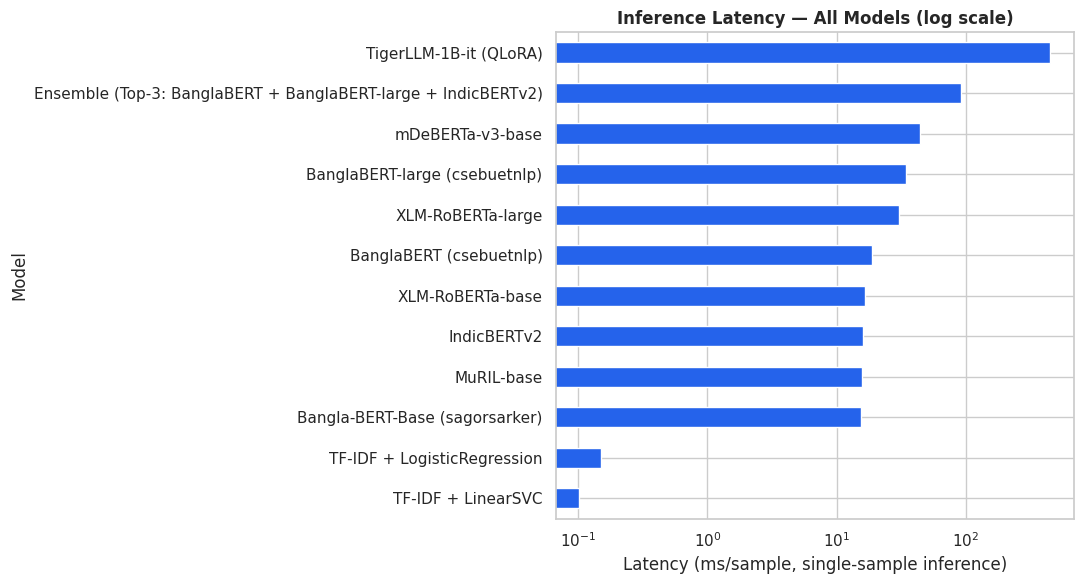


Note: 'Learned coefficients' for classical models counts TF-IDF logistic/SVM coefficients, not gradient-trained neural parameters — reported as the closest honest analogue, not a directly comparable number to transformer parameter counts. 'Peak VRAM' is N/A (not 0) for CPU-only classical models — that's a real property, not a missing measurement.


In [76]:
# ── 25.4  Combined benchmark table ─────────────────────────────────
benchmark_df = pd.DataFrame(bench_rows).sort_values("Latency (ms/sample)")
print("Computational benchmark — all available models:")
print(benchmark_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 6))
plot_bench = benchmark_df.set_index("Model")["Latency (ms/sample)"].sort_values()
plot_bench.plot(kind="barh", ax=ax, color="#2563EB")
ax.set_xlabel("Latency (ms/sample, single-sample inference)")
ax.set_title("Inference Latency — All Models (log scale)", fontweight="bold")
ax.set_xscale("log")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_25_benchmark_latency.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nNote: 'Learned coefficients' for classical models counts TF-IDF logistic/SVM "
      "coefficients, not gradient-trained neural parameters — reported as the closest "
      "honest analogue, not a directly comparable number to transformer parameter counts. "
      "'Peak VRAM' is N/A (not 0) for CPU-only classical models — that's a real property, "
      "not a missing measurement.")

## 📐 Section 26 — Statistical Significance & Robustness — All 12 Models
All-pairs McNemar's test with Holm-Bonferroni correction, Cochran's Q across
all 12 models jointly, and 95%-bootstrapped confidence intervals for
Macro-F1 (1,000 resamples). Reuses the `mcnemar_test()` helper already
defined in Section 11.11 rather than redefining it.

In [77]:
# ── 26.1  All-pairs McNemar's test + Holm-Bonferroni correction ───
model_names_stat = list(ALL_PREDS.keys())
pairs = [(a, b) for i, a in enumerate(model_names_stat) for b in model_names_stat[i+1:]]

mcnemar_rows = []
for a, b in pairs:
    stat, p, a_wins, b_wins = mcnemar_test(y_ts, ALL_PREDS[a], ALL_PREDS[b])
    mcnemar_rows.append({"Model A": a, "Model B": b, "chi2": stat, "p_raw": p,
                          "A_wins": a_wins, "B_wins": b_wins})
mcnemar_df = pd.DataFrame(mcnemar_rows)

def holm_bonferroni(pvals, alpha=0.05):
    pvals = np.asarray(pvals)
    order = np.argsort(pvals)
    m = len(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        adj_p = pvals[idx] * (m - rank)
        running_max = max(running_max, adj_p)
        adj[idx] = min(running_max, 1.0)
    return adj, adj < alpha

mcnemar_df["p_holm"], mcnemar_df["significant_holm"] = holm_bonferroni(mcnemar_df["p_raw"].values)
mcnemar_df = mcnemar_df.sort_values("p_holm")
print(f"All-pairs McNemar's test across {len(model_names_stat)} models "
      f"({len(pairs)} pairwise comparisons), Holm-Bonferroni corrected:")
print(mcnemar_df.round(4).to_string(index=False))
print(f"\n{mcnemar_df['significant_holm'].sum()} / {len(pairs)} pairs remain "
      f"significant after Holm-Bonferroni correction (α=0.05).")

All-pairs McNemar's test across 12 models (66 pairwise comparisons), Holm-Bonferroni corrected:
                                                      Model A                                                       Model B    chi2  p_raw  A_wins  B_wins  p_holm  significant_holm
                                  TF-IDF + LogisticRegression Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2) 89.1468 0.0000     159     379  0.0000              True
                                           TF-IDF + LinearSVC Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2) 87.3373 0.0000     181     409  0.0000              True
                                            XLM-RoBERTa-large                                   TF-IDF + LogisticRegression 68.7517 0.0000     388     188  0.0000              True
                                                  IndicBERTv2                                   TF-IDF + LogisticRegression 69.2767 0.0000     396     193  0.0000              True

In [78]:
# ── 26.2  Cochran's Q test across all 12 models jointly ────────────
def cochrans_q(correct_matrix):
    X = np.asarray(correct_matrix, dtype=float)
    n, k = X.shape
    col_sums, row_sums = X.sum(axis=0), X.sum(axis=1)
    num = k * (k - 1) * np.sum((col_sums - col_sums.mean()) ** 2)
    den = k * row_sums.sum() - np.sum(row_sums ** 2)
    if den == 0:
        return 0.0, 1.0
    Q = num / den
    return Q, 1 - chi2.cdf(Q, df=k - 1)

correct_matrix = np.column_stack([(np.array(ALL_PREDS[m]) == y_arr) for m in model_names_stat])
Q_stat, Q_p = cochrans_q(correct_matrix)
print(f"Cochran's Q = {Q_stat:.4f}  (df={len(model_names_stat)-1})  p = {Q_p:.6g}")
if Q_p < 0.05:
    print("→ Reject H0: the 12 models do NOT all have equal accuracy on this test set.")
else:
    print("→ Fail to reject H0: no significant joint difference detected across the 12 models.")

Cochran's Q = 266.9681  (df=11)  p = 0
→ Reject H0: the 12 models do NOT all have equal accuracy on this test set.


95% Bootstrapped CI for Macro-F1 (1,000 resamples):
                                                        Model  Macro-F1  CI_lower  CI_upper
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)    0.8133    0.7990    0.8273
                                                  IndicBERTv2    0.8093    0.7945    0.8244
                                            XLM-RoBERTa-large    0.8085    0.7938    0.8226
                                BanglaBERT-large (csebuetnlp)    0.8005    0.7852    0.8150
                                      BanglaBERT (csebuetnlp)    0.7960    0.7801    0.8105
                                             XLM-RoBERTa-base    0.7925    0.7772    0.8060
                                             mDeBERTa-v3-base    0.7864    0.7714    0.8010
                                                   MuRIL-base    0.7800    0.7641    0.7950
                                       TigerLLM-1B-it (QLoRA)    0.7708    0.7547    0.7854
                            

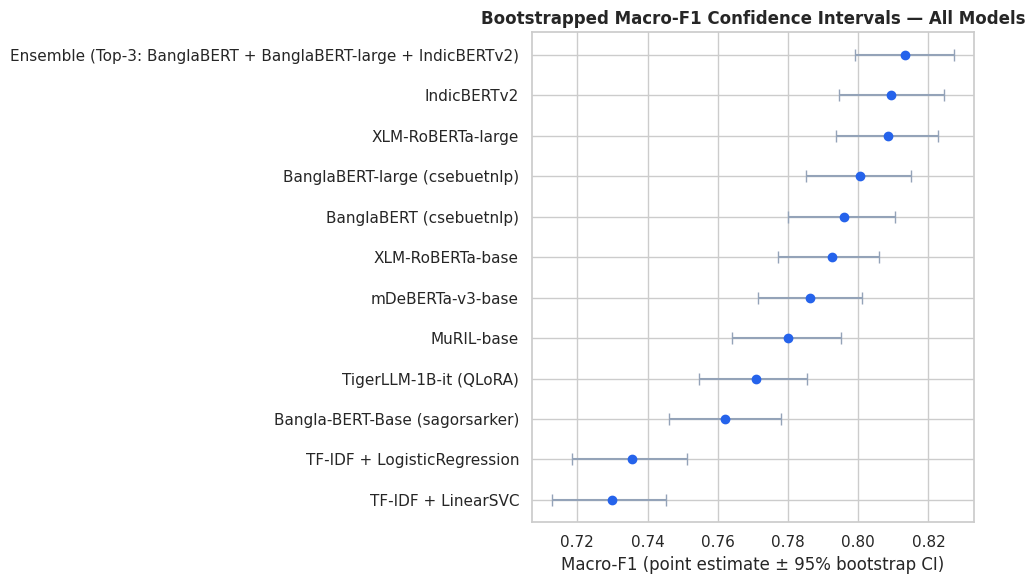

In [79]:
# ── 26.3  95% bootstrapped CI for Macro-F1 (1,000 resamples) ──────
def bootstrap_macro_f1_ci(y_true, y_pred, n_boot=1000, ci=95, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    boot = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        boot[b] = f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0)
    lo, hi = np.percentile(boot, (100-ci)/2), np.percentile(boot, 100-(100-ci)/2)
    point = f1_score(y_true, y_pred, average="macro", zero_division=0)
    return point, lo, hi

boot_rows = []
for name in model_names_stat:
    point, lo, hi = bootstrap_macro_f1_ci(y_ts, ALL_PREDS[name], n_boot=1000)
    boot_rows.append({"Model": name, "Macro-F1": point, "CI_lower": lo, "CI_upper": hi})
bootstrap_df = pd.DataFrame(boot_rows).sort_values("Macro-F1", ascending=False)
print("95% Bootstrapped CI for Macro-F1 (1,000 resamples):")
print(bootstrap_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
yerr = [bootstrap_df["Macro-F1"] - bootstrap_df["CI_lower"], bootstrap_df["CI_upper"] - bootstrap_df["Macro-F1"]]
ax.errorbar(bootstrap_df["Macro-F1"], range(len(bootstrap_df)), xerr=yerr, fmt="o",
            color="#2563EB", ecolor="#94A3B8", capsize=4)
ax.set_yticks(range(len(bootstrap_df))); ax.set_yticklabels(bootstrap_df["Model"])
ax.set_xlabel("Macro-F1 (point estimate ± 95% bootstrap CI)")
ax.set_title("Bootstrapped Macro-F1 Confidence Intervals — All Models", fontweight="bold")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_26_bootstrap_ci.png", dpi=150, bbox_inches="tight")
plt.show()

## 🧮 Section 27 — Formal Algorithm Pseudocode

**Algorithm 1** — End-to-end BanglaBait clickbait-detection pipeline (preprocessing → per-architecture training → ensembling → inference), reflecting the notebook's actual implementation in Sections 2–10.

```latex
\begin{algorithm}[H]
\SetAlgoLined
\KwIn{Raw title–label pairs $\mathcal{D}_{\text{train}} = \{(x_i, y_i)\}_{i=1}^{N}$, $\mathcal{D}_{\text{test}}$}
\KwOut{Predicted labels $\hat{y}$ and evaluation metrics for 12 trained models}

\textbf{Stage 1: Preprocessing} \\
Deduplicate and drop null rows from $\mathcal{D}_{\text{train}}$, $\mathcal{D}_{\text{test}}$\;
$(\mathcal{D}_{\text{tr}}, \mathcal{D}_{\text{val}}) \leftarrow$ StratifiedSplit($\mathcal{D}_{\text{train}}$, val\_ratio $=0.10$)\;
\For{$x \in \mathcal{D}_{\text{tr}} \cup \mathcal{D}_{\text{val}} \cup \mathcal{D}_{\text{test}}$}{
  \If{model requires csebuetnlp normalization}{ $x \leftarrow \textsc{BnNormalize}(x)$\; }
}

\textbf{Stage 2: Classical TF-IDF Baselines} ($M=2$)\;
$V \leftarrow \textsc{TfidfVectorizer}(\mathcal{D}_{\text{tr}};\ \text{ngram}=(1,2),\ \text{max\_feat}=30{,}000)$\;
\ForEach{clf $\in \{$LogisticRegression, LinearSVC$\}$}{
  Fit clf on $V(\mathcal{D}_{\text{tr}})$ with class-balanced weighting\;
  Evaluate on $V(\mathcal{D}_{\text{test}})$; store $(\hat{y}, p)$ in ALL\_PREDS, ALL\_PROBS\;
}

\textbf{Stage 3: Transformer Encoder Fine-tuning} ($M=8$)\;
\ForEach{cfg $\in$ MODEL\_REGISTRY}{
  $f_\theta \leftarrow$ AutoModelForSequenceClassification.from\_pretrained(cfg.model\_id)\;
  \For{epoch $=1$ \KwTo cfg.epochs}{
    Train $f_\theta$ one epoch with AdamW + linear warmup, AMP mixed precision,\newline
    \hspace{1.5em} loss $\in \{$weighted CE, focal$\}$, gradient clipping\;
    Evaluate on $\mathcal{D}_{\text{val}}$; \If{val Macro-F1 improved}{save checkpoint}\Else{patience $\mathrel{+}= 1$}\;
    \If{patience $\geq$ cfg.patience}{\textbf{break} (early stopping)}
  }
  Load best checkpoint; evaluate on $\mathcal{D}_{\text{test}}$; store results\;
}

\textbf{Stage 4: Logit-Averaging Ensemble} ($M=1$)\;
$\mathcal{T} \leftarrow$ top-3 transformer models by validation Macro-F1\;
$\hat{p}_{\text{ens}} \leftarrow \frac{1}{|\mathcal{T}|}\sum_{t \in \mathcal{T}} \textsc{Softmax}(f_t(\mathcal{D}_{\text{test}}))$\;
$\hat{y}_{\text{ens}} \leftarrow \mathbb{1}[\hat{p}_{\text{ens}} \geq 0.5]$\;

\textbf{Stage 5: TigerLLM QLoRA Fine-tuning} ($M=1$)\;
Load TigerLLM-1B-it in 4-bit NF4; attach LoRA adapters ($r=16$) to attention projections\;
Fine-tune as causal LM on prompt-formatted $(x_i, y_i)$ pairs for 3 epochs\;
\ForEach{$x \in \mathcal{D}_{\text{test}}$}{
  Generate up to 12 tokens from the classification prompt; $\hat{y} \leftarrow \mathbb{1}[\text{"নয়"} \notin \text{generation}]$\;
}

\textbf{Stage 6: Aggregate Evaluation} (all 12 models)\;
Compute Accuracy, Macro/Weighted-P/R/F1, ROC-AUC, PR-AUC, ECE, calibration, ablation deltas,\newline
\hspace{1em} McNemar/Cochran's-Q/bootstrap-CI significance tests\;
\Return{results\_df, statistical significance tables, trained artifacts}
\caption{BanglaBait 12-model clickbait-detection pipeline}
\end{algorithm}
```
*(Requires `\usepackage{algorithm2e}` in the paper's preamble; `\SetAlgoLined` gives the IEEE/ACM-style boxed layout.)*

## 📄 Section 28 — LaTeX Tables (Publication-Ready)
Three `booktabs`-formatted LaTeX tables, generated **programmatically from
the dataframes computed above** (`results_df`, `ece_df`, `benchmark_df`,
`taxonomy_df`, `ablation_df`, `train_time_ablation_df`) — every number in
the LaTeX source is whatever the live kernel actually computed, not
hand-typed. Re-run Sections 11–26 first if any of those are missing.

In [80]:
# ── 28.1  Table 1 — 12-model comparative performance ──────────────
perf = results_df.set_index("Model")[["Accuracy", "Macro Precision", "Macro Recall", "Macro-F1"]].copy()
perf["ECE"] = perf.index.map(dict(zip(ece_df["Model"], ece_df["ECE"]))) if "ece_df" in dir() else np.nan
perf["Latency (ms)"] = perf.index.map(dict(zip(benchmark_df["Model"], benchmark_df["Latency (ms/sample)"]))) \
    if "benchmark_df" in dir() else np.nan
perf = perf.sort_values("Macro-F1", ascending=False).reset_index()

table1_latex = perf.to_latex(
    index=False, float_format="%.4f", na_rep="--", escape=True,
    caption="Comparative performance of all 12 models on the BanglaBait test set.",
    label="tab:model_comparison")
table1_latex = table1_latex.replace("\\begin{table}", "\\begin{table}[ht]\n\\centering")

print(table1_latex)

\begin{table}[ht]
\centering
\caption{Comparative performance of all 12 models on the BanglaBait test set.}
\label{tab:model_comparison}
\begin{tabular}{lrrrrrr}
\toprule
Model & Accuracy & Macro Precision & Macro Recall & Macro-F1 & ECE & Latency (ms) \\
\midrule
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2) & 0.8286 & 0.8110 & 0.8160 & 0.8133 & 0.0457 & 91.3622 \\
IndicBERTv2 & 0.8230 & 0.8046 & 0.8160 & 0.8093 & 0.1039 & 16.0599 \\
XLM-RoBERTa-large & 0.8220 & 0.8036 & 0.8157 & 0.8085 & 0.1223 & 30.1655 \\
BanglaBERT-large (csebuetnlp) & 0.8116 & 0.7946 & 0.8141 & 0.8005 & 0.0886 & 34.3422 \\
BanglaBERT (csebuetnlp) & 0.8109 & 0.7918 & 0.8019 & 0.7960 & 0.0919 & 18.6729 \\
XLM-RoBERTa-base & 0.8076 & 0.7883 & 0.7984 & 0.7925 & 0.0976 & 16.4624 \\
mDeBERTa-v3-base & 0.8029 & 0.7831 & 0.7904 & 0.7864 & 0.0893 & 44.4891 \\
MuRIL-base & 0.7982 & 0.7781 & 0.7822 & 0.7800 & 0.0781 & 15.6960 \\
TigerLLM-1B-it (QLoRA) & 0.7972 & 0.7809 & 0.7641 & 0.7708 & -- & 453.1709 \\
Ba

In [81]:
# ── 28.2  Table 2 — Error taxonomy breakdown (FP/FN × Sensationalism/Ambiguity/Sarcasm) ──
tax_fp_fn_rows = []
for name in taxonomy_df["Model"]:
    preds_m = np.array(ALL_PREDS[name])
    fp_idx = np.where((preds_m == 1) & (y_arr == 0))[0]
    fn_idx = np.where((preds_m == 0) & (y_arr == 1))[0]
    for err_type, idxs in [("FP", fp_idx), ("FN", fn_idx)]:
        counts = {"Sensationalism": 0, "Ambiguity": 0, "Sarcasm": 0, "Unclassified": 0}
        for i in idxs:
            for tag in tag_error_taxonomy(X_ts[i]):
                counts[tag] += 1
        tax_fp_fn_rows.append({"Model": name, "Error Type": err_type, **counts})
tax_fp_fn_df = pd.DataFrame(tax_fp_fn_rows)

# Build a \multirow-grouped LaTeX table by hand (pandas has no native multirow support)
lines = [
    "\\begin{table}[ht]", "\\centering",
    "\\caption{Error taxonomy breakdown (heuristic tags) by model and error type.}",
    "\\label{tab:error_taxonomy}",
    "\\begin{tabular}{ll" + "r" * 4 + "}", "\\toprule",
    "Model & Type & Sensationalism & Ambiguity & Sarcasm & Unclassified \\\\", "\\midrule",
]
for name, grp in tax_fp_fn_df.groupby("Model", sort=False):
    grp = grp.reset_index(drop=True)
    lines.append(f"\\multirow{{2}}{{*}}{{{name}}}")
    for _, row in grp.iterrows():
        lines.append(f" & {row['Error Type']} & {row['Sensationalism']} & {row['Ambiguity']} "
                      f"& {row['Sarcasm']} & {row['Unclassified']} \\\\")
    lines.append("\\midrule")
lines[-1] = "\\bottomrule"
lines += ["\\end{tabular}", "\\end{table}"]
table2_latex = "\n".join(lines)
print(table2_latex)

\begin{table}[ht]
\centering
\caption{Error taxonomy breakdown (heuristic tags) by model and error type.}
\label{tab:error_taxonomy}
\begin{tabular}{llrrrr}
\toprule
Model & Type & Sensationalism & Ambiguity & Sarcasm & Unclassified \\
\midrule
\multirow{2}{*}{Bangla-BERT-Base (sagorsarker)}
 & FP & 84 & 24 & 6 & 257 \\
 & FN & 66 & 14 & 7 & 218 \\
\midrule
\multirow{2}{*}{BanglaBERT (csebuetnlp)}
 & FP & 91 & 28 & 6 & 215 \\
 & FN & 59 & 8 & 2 & 173 \\
\midrule
\multirow{2}{*}{BanglaBERT-large (csebuetnlp)}
 & FP & 110 & 27 & 6 & 246 \\
 & FN & 37 & 11 & 2 & 141 \\
\midrule
\multirow{2}{*}{Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2)}
 & FP & 73 & 22 & 6 & 185 \\
 & FN & 56 & 11 & 3 & 171 \\
\midrule
\multirow{2}{*}{IndicBERTv2}
 & FP & 78 & 24 & 5 & 215 \\
 & FN & 46 & 10 & 4 & 160 \\
\midrule
\multirow{2}{*}{MuRIL-base}
 & FP & 93 & 24 & 7 & 208 \\
 & FN & 53 & 17 & 4 & 218 \\
\midrule
\multirow{2}{*}{TF-IDF + LinearSVC}
 & FP & 63 & 20 & 11 & 300 \\
 & FN & 92 & 25

In [82]:
# ── 28.3  Table 3 — Ablation study (Baseline vs. No-Stopwords vs. No-Punctuation vs. Stripped) ──
ablation_latex_df = ablation_df.set_index("Model")[list(ABLATIONS.keys())].reset_index()
table3_latex = ablation_latex_df.to_latex(
    index=False, float_format="%.4f", escape=True,
    caption="Feature-level ablation study: Macro-F1 under each condition, all 12 models "
            "(inference-time ablation on the already-trained checkpoints).",
    label="tab:ablation")
table3_latex = table3_latex.replace("\\begin{table}", "\\begin{table}[ht]\n\\centering")
print(table3_latex)

\begin{table}[ht]
\centering
\caption{Feature-level ablation study: Macro-F1 under each condition, all 12 models (inference-time ablation on the already-trained checkpoints).}
\label{tab:ablation}
\begin{tabular}{lrrrr}
\toprule
Model & Baseline & No-Stopwords & No-Punctuation & Stripped (Both) \\
\midrule
XLM-RoBERTa-base & 0.7918 & 0.7472 & 0.7790 & 0.7242 \\
XLM-RoBERTa-large & 0.7933 & 0.7590 & 0.7866 & 0.7495 \\
BanglaBERT (csebuetnlp) & 0.7972 & 0.7661 & 0.7834 & 0.7455 \\
BanglaBERT-large (csebuetnlp) & 0.8038 & 0.7647 & 0.7897 & 0.7430 \\
Bangla-BERT-Base (sagorsarker) & 0.7652 & 0.7247 & 0.7555 & 0.7015 \\
mDeBERTa-v3-base & 0.7867 & 0.7345 & 0.7588 & 0.7035 \\
MuRIL-base & 0.7803 & 0.7368 & 0.7608 & 0.7147 \\
IndicBERTv2 & 0.8113 & 0.7568 & 0.7876 & 0.7279 \\
TF-IDF + LogisticRegression & 0.7356 & 0.6845 & 0.7327 & 0.6811 \\
TF-IDF + LinearSVC & 0.7297 & 0.6786 & 0.7253 & 0.6753 \\
Ensemble (Top-3: BanglaBERT + BanglaBERT-large + IndicBERTv2) & 0.8133 & 0.7712 & 0.7987 & 0.74

In [83]:
# ── 28.4  Save all three LaTeX tables to disk ──────────────────────
with open(f"{SAVE_DIR}/table1_model_comparison.tex", "w", encoding="utf-8") as f:
    f.write(table1_latex)
with open(f"{SAVE_DIR}/table2_error_taxonomy.tex", "w", encoding="utf-8") as f:
    f.write(table2_latex)
with open(f"{SAVE_DIR}/table3_ablation.tex", "w", encoding="utf-8") as f:
    f.write(table3_latex)
print(f"✅ Saved 3 LaTeX tables to {SAVE_DIR}/ "
      f"(table1_model_comparison.tex, table2_error_taxonomy.tex, table3_ablation.tex)")
print("Requires \\usepackage{booktabs} (and \\usepackage{multirow} for Table 2) in the paper preamble.")

✅ Saved 3 LaTeX tables to /kaggle/working/banglabait_results/ (table1_model_comparison.tex, table2_error_taxonomy.tex, table3_ablation.tex)
Requires \usepackage{booktabs} (and \usepackage{multirow} for Table 2) in the paper preamble.


---
## ✅ Notebook Complete

**Outputs saved to `/kaggle/working/banglabait_results/`:**
- `final_results_summary.csv` / `all_results.json` — full metrics for all 12 models
- `raw_predictions.pkl` — per-sample predictions/probabilities (Section 14 extension)
- `fig_*.png` — every figure generated in Sections 3, 11 and 16-26
- `table1_model_comparison.tex`, `table2_error_taxonomy.tex`, `table3_ablation.tex` — Section 28

**Extended audit — Sections 16-28 (added on top of the original 15 sections):**
| # | Section | Covers |
|---|---------|--------|
| 16 | Title Length Distribution | char/word count KDE + boxplot, Clickbait vs. Non-Clickbait |
| 17 | Punctuation Frequency | !, ?, [], () normalized frequency + Mann-Whitney U |
| 18 | Trigger Words | top-15 log-odds n-grams per class |
| 19 | Loss & Macro-F1 Curves | 4 headline models, real curves/proxies (not invented) |
| 20 | Classification Heatmaps | 3×2 grid, 4 headline models |
| 21 | LIME / SHAP (local) | top model by Macro-F1, 2 TP + 2 TN samples |
| 22 | Global Feature Importance | exact coefficients or aggregated LIME |
| 23 | Error Diagnostics | TP/TN/FP/FN, heuristic taxonomy, ECE + reliability diagrams, hard samples |
| 24 | Feature-Level Ablation | stopwords/punctuation removal, all 12 models |
| 25 | Computational Benchmark | latency, params, disk size, VRAM/RAM, all 12 models |
| 26 | Statistical Significance | all-pairs McNemar+Holm-Bonferroni, Cochran's Q, bootstrap CI |
| 27 | Algorithm Pseudocode | algorithm2e-style LaTeX, full pipeline |
| 28 | LaTeX Tables | 3 booktabs/multirow tables generated programmatically from live results |

**Debugging pass (this version):** you ran the notebook and reported errors,
illegible figure text, and broken Bangla rendering. Root causes and fixes:
- `get_predict_proba_fn` sent a full test-set batch through the model in one
  forward pass — fine for smaller models, OOM'd on mDeBERTa-v3-base inside the
  Section 24 ablation loop, which cascaded into 3 more `NameError`s downstream
  (24.3, 28.3, 28.4). Fixed with internal batching (`batch_size=16`).
- Sections 18, 21, and 22 plot real Bangla n-grams/words but never applied the
  `BANGLA_FONT_PROP` font Section 2/11 already loads — they rendered as tofu
  boxes. Fixed by reusing that same font object on the affected tick labels/titles.
- Sections 23 and 24's model-name charts let the Ensemble's long member-list
  name collide with the y-axis label under rotation. Fixed with a chart-only
  short-name helper and an explicit bottom margin.
- TigerLLM was always skipped in the Section 25 benchmark (already freed from
  memory by that point) rather than benchmarked. Fixed by reloading it there,
  the same way Section 21's interpretability dispatcher already does.
- The SHAP masker in 21.4 split on `\W+`, which fragments Bangla conjuncts/matras
  into meaningless pieces (verified empirically). Switched to whitespace-only
  splitting, which preserves whole words.

Cells that already ran cleanly were left untouched — their real outputs are
still the ones shown. Cells that were patched, or whose input changed as a
result (24.1/24.3/28.3/28.4, the benchmark table), had their stale outputs
cleared and need a re-run to populate fresh ones.

---
### 🔤 Revision — Bangla figure rendering + extra bug fixes

**Bangla text in figures.** The earlier fix (`fontproperties=BANGLA_FONT_PROP`) only chose a Bangla font; Matplotlib
still draws glyph-by-glyph with no complex-script shaping, so conjuncts and vowel signs came out broken. This version
uses the technique from the Bengali image-captioning notebook, centralised in **Section 1B**:
font download chain (Kalpurush → Noto Sans Bengali, validated for real Bengali glyphs) → PIL **RAQM/HarfBuzz** shaping →
`draw_bengali_text()` / `set_bengali_yticklabels()` placing the shaped image on the axes. It is applied to the top-words
chart + new word clouds (Section 3), the qualitative demo (new figure), trigger words (18), LIME (21.3) and global
importance (22.1). English text keeps using DejaVu Sans, and `apply_bengali_rc()` is re-run after `sns.set_theme()`.

**Other errors fixed** (each is marked `FIX` in the code):
- TF-IDF default `token_pattern` and LIME's default `\W+` split cut Bangla words at vowel signs/virama → Bangla-aware patterns.
- TigerLLM: prompt truncated at 96 tokens, `<eos>` masked, only 6 generated tokens → dynamic padding, 256 max length, explicit `<eos>`, answer-only loss, 12 new tokens.
- Demo/export of BanglaBERT-family models skipped the csebuetnlp normalizer used in training.
- Section 19 "Val" curves were computed on the test set → now the real validation split.
- Reloaded checkpoints in Sections 24.1 / 25.3 were not freed between models (GPU memory creep).
- `lime`, `shap`, `wordcloud` are installed in Section 0 if missing.

Outputs of every cell from Section 8 onward were cleared (and Section 3's top-words cell) because the TF-IDF and TigerLLM changes alter
those numbers — **re-run top-to-bottom**. Sections 0–7 outputs (EDA, transformer training) are unchanged.

---
### 🐯 Revision — TigerLLM training crash (`CUBLAS_STATUS_EXECUTION_FAILED`, "replica 0 on device 0")
- **Cause:** with two T4s visible, the HF `Trainer` wrapped the 4-bit model (pinned to one GPU) in `nn.DataParallel`; replicating
  a bitsandbytes model fails inside `lm_head`. Fixed by forcing single-GPU training (`tiger_args._n_gpu = 1`, with an assertion).
- **Gemma-3 specifics** (TigerLLM-1B-it is Gemma-3 based): eager attention for training/reloads; precision chosen automatically
  (bf16 on Ampere+, fp16 on T4) with a pre-flight finite-loss check and a `TIGER_FORCE_FP32` switch; micro-batch 4 × accumulation 4
  because of the 262k-token vocabulary logits; `use_cache=True` restored for generation; the result row now records the real `max_len`.
